# Explainable Short-Horizon N₂O Forecasting for Wastewater Treatment Process Monitoring

## Project Objective

**Primary question:** Can currently available wastewater-process measurements be used to forecast N₂O concentration one hour ahead, and which process variables contribute most to the forecast?

**Target:** Hourly mean N₂O concentration at *t + 1 hour*.

**Operational scenario:** Current N₂O and wastewater-process/control measurements are available at forecast time *t*.

**Analytical workflow**

Raw data → quality-aware SQL ingestion → hourly aggregation → statistical analysis → feature engineering → leakage validation → chronological forecasting → error analysis → interpretability → decision support.

## Final Run Summary

| Item | Result |
|---|---:|
| Modelling-ready rows | 7,510 |
| Forecast horizon | 1 hour |
| Selected model | HistGradientBoosting |
| Test MAE | 0.033821 |
| Test RMSE | 0.053006 |
| Test R² | 0.798793 |
| Analytical Q90 threshold | 0.41287 |

### Time-zone convention

The raw Avedøre timestamps are parsed with their original offsets. For reproducibility of the validated Stage 2B → Stage 3 → Stage 5 pipeline, the hourly hand-off timestamp convention is retained as a fixed **+05:30 (`Asia/Kolkata`) representation**, because the frozen Stage 2B export uses that convention.

This is a **data-pipeline compatibility convention, not the physical plant timezone**. The Avedøre plant is in Denmark; **Europe/Copenhagen** is the appropriate timezone for explicitly derived plant-local calendar interpretation. UTC remains appropriate for internal timestamp alignment when needed.


## Methodological Principles

- Quality flags distinguish usable from bad-quality measurements.
- Raw values are not altered by their quality flags.
- Hourly aggregation provides a consistent forecasting resolution.
- The exact next hourly record is required for the one-hour-ahead target.
- Predictive features use only information available at or before forecast time.
- Model selection is based on the validation period; the test period is held out for final evaluation.
- MAE and RMSE are the primary performance measures; R² is secondary.
- Predictive importance is interpreted as association, not causation.
- The analytical monitoring threshold is derived from historical pre-test data and is not a regulatory limit.


# 1. Project Definition


## Source notes

- Dataset source: Avedøre WWTP, Copenhagen, Denmark.
- Process: full-scale activated-sludge biological treatment, line 3.
- Source paper: *Time Series Dataset for Modeling and Forecasting of N2O in Wastewater Treatment*.
- The paper defines quality `0 = Good` and `1 = Bad`.
- The actual CSV is treated as authoritative for its observed schema, timestamp sequence, missingness, and column names.
- Paper descriptions are used to interpret process meaning and units.


In [1]:
# Cell 1 — Imports and project path

import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("../data/raw/aved_raw.csv")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

print("Data path:", DATA_PATH)

Data path: ..\data\raw\aved_raw.csv


In [2]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nRaw data exists:", Path("../data/raw/aved_raw.csv").exists())
print("Processed folder exists:", Path("../data/processed").exists())

Current working directory:
C:\Users\Dell\Data_S\N2O_Forecasting_Project\notebooks

Raw data exists: True
Processed folder exists: True


In [3]:
# Cell 2 — Load the raw CSV and verify dimensions
df = pd.read_csv(DATA_PATH, low_memory=False)

print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Expected Stage-1 structure: 1 time + 24 value + 24 quality columns")

assert len(df.columns) == 49, "Unexpected column count — inspect before proceeding."
assert len(df) > 0, "Dataset loaded with zero rows."

df.head(3)


Rows: 906815
Columns: 49
Expected Stage-1 structure: 1 time + 24 value + 24 quality columns


,time,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW value,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW quality,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT value,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT quality,BIOLOGY.LINE 3 TANK 1.N2O value,BIOLOGY.LINE 3 TANK 1.N2O quality,BIOLOGY.LINE 3 TANK 1.NH4 value,BIOLOGY.LINE 3 TANK 1.NH4 quality,BIOLOGY.LINE 3 TANK 1.NO3 value,BIOLOGY.LINE 3 TANK 1.NO3 quality,BIOLOGY.LINE 3 TANK 1.O2 value,BIOLOGY.LINE 3 TANK 1.O2 quality,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT value,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT quality,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE value,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE quality,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW value,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW quality,BIOLOGY.LINE 3 TANK 1.SS value,BIOLOGY.LINE 3 TANK 1.SS quality,BIOLOGY.LINE 3 TANK 1.TEMPERATURE value,BIOLOGY.LINE 3 TANK 1.TEMPERATURE quality,BIOLOGY.LINE 3 TANK 2 VALVE 1.PCT value,BIOLOGY.LINE 3 TANK 2 VALVE 1.PCT quality,BIOLOGY.LINE 3 TANK 2.O2 value,BIOLOGY.LINE 3 TANK 2.O2 quality,BIOLOGY.LINE 3 TANK 2.O2.SETPOINT value,BIOLOGY.LINE 3 TANK 2.O2.SETPOINT quality,BIOLOGY.LINE 3 TANK 2.PROCESSPHASE value,BIOLOGY.LINE 3 TANK 2.PROCESSPHASE quality,BIOLOGY.LINE 3 TANK 2.Q.AIRFLOW value,BIOLOGY.LINE 3 TANK 2.Q.AIRFLOW quality,BIOLOGY.LINE 3 TANK 2.SS value,BIOLOGY.LINE 3 TANK 2.SS quality,BIOLOGY.LINE 3 TANK 2.TEMPERATURE value,BIOLOGY.LINE 3 TANK 2.TEMPERATURE quality,BIOLOGY.LINE 3.PHASECODE.SETPOINT value,BIOLOGY.LINE 3.PHASECODE.SETPOINT quality,BIOLOGY.LINE 3.PROCESSPHASE.INLET TANK value,BIOLOGY.LINE 3.PROCESSPHASE.INLET TANK quality,BIOLOGY.LINE 3.PROCESSPHASE.OUTLET TANK value,BIOLOGY.LINE 3.PROCESSPHASE.OUTLET TANK quality,BIOLOGY.LINE 3 TANK 1.PO4 value,BIOLOGY.LINE 3 TANK 1.PO4 quality,INLET.Q value,INLET.Q quality,INLET.STATE.SWM INLET FLOW value,INLET.STATE.SWM INLET FLOW quality
0,2022-06-12 00:01:00+02:00,26829.375000,1.0,NaN,NaN,0.700231,0.0,1.66608,0.0,0.074907,0.0,0.058955,0.0,NaN,NaN,2.0,0.0,NaN,NaN,1.525374,1.0,NaN,NaN,NaN,NaN,1.384549,0.0,NaN,NaN,2.0,0.0,NaN,NaN,1.647483,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.285834,1.0,NaN,NaN,NaN,NaN
1,2022-06-12 00:02:00+02:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.238239,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.507085,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1222.0,0.0,1.0,0.0,2.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0
2,2022-06-12 00:03:00+02:00,29626.341797,1.0,NaN,NaN,0.697917,0.0,1.52727,0.0,0.074907,0.0,0.079933,0.0,NaN,NaN,2.0,0.0,NaN,NaN,1.536805,1.0,NaN,NaN,NaN,NaN,1.673177,0.0,NaN,NaN,2.0,0.0,NaN,NaN,1.594784,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.273499,1.0,NaN,NaN,NaN,NaN


In [4]:
# Cell 3 — Inspect the complete raw schema
schema = pd.DataFrame({
    "column_position": range(len(df.columns)),
    "column_name": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "missing_count": df.isna().sum().values,
    "missing_pct": (df.isna().mean().values * 100)
})

schema


,column_position,column_name,dtype,missing_count,missing_pct
0,0,time,str,0,0.000000
1,1,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW value,float64,386227,42.591598
2,2,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW quality,float64,386227,42.591598
3,3,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT value,float64,403980,44.549329
4,4,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT quality,float64,403980,44.549329
5,5,BIOLOGY.LINE 3 TANK 1.N2O value,float64,386269,42.596230
6,6,BIOLOGY.LINE 3 TANK 1.N2O quality,float64,386269,42.596230
7,7,BIOLOGY.LINE 3 TANK 1.NH4 value,float64,386220,42.590826
8,8,BIOLOGY.LINE 3 TANK 1.NH4 quality,float64,386220,42.590826
9,9,BIOLOGY.LINE 3 TANK 1.NO3 value,float64,386232,42.592149


In [5]:
# Cell 4 — Verify value/quality column pairing
value_cols = [c for c in df.columns if c.endswith(" value")]
quality_cols = [c for c in df.columns if c.endswith(" quality")]

print("Value columns:", len(value_cols))
print("Quality columns:", len(quality_cols))

assert len(value_cols) == 24
assert len(quality_cols) == 24

pair_check = []
for value_col in value_cols:
    quality_col = value_col[:-6] + " quality"
    pair_check.append({
        "value_column": value_col,
        "quality_column": quality_col,
        "quality_exists": quality_col in df.columns
    })

pair_df = pd.DataFrame(pair_check)
pair_df


Value columns: 24
Quality columns: 24


,value_column,quality_column,quality_exists
0,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW value,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW quality,True
1,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT value,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT quality,True
2,BIOLOGY.LINE 3 TANK 1.N2O value,BIOLOGY.LINE 3 TANK 1.N2O quality,True
3,BIOLOGY.LINE 3 TANK 1.NH4 value,BIOLOGY.LINE 3 TANK 1.NH4 quality,True
4,BIOLOGY.LINE 3 TANK 1.NO3 value,BIOLOGY.LINE 3 TANK 1.NO3 quality,True
5,BIOLOGY.LINE 3 TANK 1.O2 value,BIOLOGY.LINE 3 TANK 1.O2 quality,True
6,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT value,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT quality,True
7,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE value,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE quality,True
8,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW value,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW quality,True
9,BIOLOGY.LINE 3 TANK 1.SS value,BIOLOGY.LINE 3 TANK 1.SS quality,True


In [6]:
# Cell 5 — Parse timestamps and audit ordering/uniqueness
time = pd.to_datetime(df["time"], utc=True)

timestamp_audit = {
    "rows": len(df),
    "unique_timestamps": time.nunique(),
    "duplicate_timestamps": time.duplicated().sum(),
    "min_timestamp_utc": time.min(),
    "max_timestamp_utc": time.max(),
    "missing_timestamps": time.isna().sum(),
    "is_monotonic_in_file_order": time.is_monotonic_increasing
}

pd.Series(timestamp_audit)


rows                                             906815
unique_timestamps                                906815
duplicate_timestamps                                  0
min_timestamp_utc             2022-06-11 22:01:00+00:00
max_timestamp_utc             2024-06-11 21:59:00+00:00
missing_timestamps                                    0
is_monotonic_in_file_order                         True
dtype: object

In [7]:
# Cell 6 — Inspect the actual timestamp interval structure
intervals = time.sort_values().diff().dropna()

interval_summary = intervals.value_counts().sort_index().rename_axis("interval").reset_index(name="count")
interval_summary["percentage"] = interval_summary["count"] / interval_summary["count"].sum() * 100

interval_summary


,interval,count,percentage
0,0 days 00:01:00,761026,83.923054
1,0 days 00:02:00,145776,16.075623
2,0 days 00:03:00,5,0.000551
3,0 days 00:04:00,5,0.000551
4,0 days 00:05:00,1,0.000110
5,0 days 00:20:00,1,0.000110


In [8]:
# Cell 7 — Audit quality-flag semantics actually present in the CSV
quality_audit = []

for qcol in quality_cols:
    q = df[qcol]
    quality_audit.append({
        "quality_column": qcol,
        "missing": int(q.isna().sum()),
        "good_0": int((q == 0).sum()),
        "bad_1": int((q == 1).sum()),
        "other_nonmissing_values": int((~q.isin([0, 1]) & q.notna()).sum()),
        "unique_nonmissing": sorted(q.dropna().unique().tolist())
    })

quality_audit_df = pd.DataFrame(quality_audit)
quality_audit_df


,quality_column,missing,good_0,bad_1,other_nonmissing_values,unique_nonmissing
0,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW quality,386227,477289,43299,0,"[0.0, 1.0]"
1,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT quality,403980,502835,0,0,[0.0]
2,BIOLOGY.LINE 3 TANK 1.N2O quality,386269,452814,67732,0,"[0.0, 1.0]"
3,BIOLOGY.LINE 3 TANK 1.NH4 quality,386220,465607,54988,0,"[0.0, 1.0]"
4,BIOLOGY.LINE 3 TANK 1.NO3 quality,386232,494952,25631,0,"[0.0, 1.0]"
5,BIOLOGY.LINE 3 TANK 1.O2 quality,386214,451633,68968,0,"[0.0, 1.0]"
6,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT quality,380530,526285,0,0,[0.0]
7,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE quality,387466,519349,0,0,[0.0]
8,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW quality,436612,464527,5676,0,"[0.0, 1.0]"
9,BIOLOGY.LINE 3 TANK 1.SS quality,386226,449296,71293,0,"[0.0, 1.0]"


In [9]:
# Cell 8 — Verify whether value and quality presence are aligned
alignment_rows = []

for vcol in value_cols:
    qcol = vcol[:-6] + " quality"
    value_present = df[vcol].notna()
    quality_present = df[qcol].notna()

    alignment_rows.append({
        "value_column": vcol,
        "value_present_quality_missing": int((value_present & ~quality_present).sum()),
        "value_missing_quality_present": int((~value_present & quality_present).sum()),
        "value_present_quality_good": int((value_present & (df[qcol] == 0)).sum()),
        "value_present_quality_bad": int((value_present & (df[qcol] == 1)).sum())
    })

alignment_df = pd.DataFrame(alignment_rows)
alignment_df


,value_column,value_present_quality_missing,value_missing_quality_present,value_present_quality_good,value_present_quality_bad
0,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW value,0,0,477289,43299
1,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT value,0,0,502835,0
2,BIOLOGY.LINE 3 TANK 1.N2O value,0,0,452814,67732
3,BIOLOGY.LINE 3 TANK 1.NH4 value,0,0,465607,54988
4,BIOLOGY.LINE 3 TANK 1.NO3 value,0,0,494952,25631
5,BIOLOGY.LINE 3 TANK 1.O2 value,0,0,451633,68968
6,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT value,0,0,526285,0
7,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE value,0,0,519349,0
8,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW value,0,0,464527,5676
9,BIOLOGY.LINE 3 TANK 1.SS value,0,0,449296,71293


In [10]:
# Cell 9 — Build the preliminary data dictionary
# This is a project artifact, not the final modelling feature list.

data_dictionary = pd.DataFrame([
    ['BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW value', 'total_airflow', 'continuous', 'Nm3/h', 'measurement', 'Combined airflow from blower station', 'Current process feature', 'Include initially', 'Direct operational aeration intensity measure.'],
    ['BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT value', 't1_valve_pct', 'continuous', '%', 'controlled state', 'Valve position for tank 1 aeration', 'Current process/control feature', 'Include initially', 'Direct aeration control signal.'],
    ['BIOLOGY.LINE 3 TANK 1.N2O value', 't1_n2o', 'continuous', 'mg-N/L', 'measurement', 'Dissolved nitrous oxide concentration', 'Target; current N2O predictor; lags', 'Include initially', 'Primary target and operationally available current state.'],
    ['BIOLOGY.LINE 3 TANK 1.NH4 value', 't1_nh4', 'continuous', 'mg-N/L', 'measurement', 'Ammonium concentration', 'Current process feature; lags', 'Include initially', 'Nitrogen substrate/process indicator.'],
    ['BIOLOGY.LINE 3 TANK 1.NO3 value', 't1_no3', 'continuous', 'mg-N/L', 'measurement', 'Nitrate concentration', 'Current process feature; lags', 'Include initially', 'Nitrogen transformation indicator.'],
    ['BIOLOGY.LINE 3 TANK 1.O2 value', 't1_do', 'continuous', 'mg/L', 'measurement', 'Dissolved oxygen concentration', 'Current process feature; lags', 'Include initially', 'Aerobic process condition.'],
    ['BIOLOGY.LINE 3 TANK 1.O2.SETPOINT value', 't1_do_setpoint', 'continuous', 'mg/L', 'controlled state', 'Dissolved oxygen setpoint', 'Current control feature', 'Include initially', 'Operational control target.'],
    ['BIOLOGY.LINE 3 TANK 1.PROCESSPHASE value', 't1_phase', 'categorical', 'code', 'controlled state', 'Aeration/process phase in tank 1', 'Process-state feature', 'Include initially', 'Phase code 0/1/2 has direct process meaning.'],
    ['BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW value', 't1_airflow_est', 'continuous', 'Nm3/h', 'estimated', 'Estimated airflow over tank 1 valve', 'Current process feature', 'Include initially with caveat', 'Estimated variable; quality depends on inputs.'],
    ['BIOLOGY.LINE 3 TANK 1.SS value', 't1_ss', 'continuous', 'g/L', 'measurement', 'Suspended solids concentration', 'Current process feature', 'Include initially', 'Biomass/process condition.'],
    ['BIOLOGY.LINE 3 TANK 1.TEMPERATURE value', 't1_temp', 'continuous', 'degC', 'measurement', 'Temperature', 'Current process feature', 'Include initially', 'Biological process condition.'],
    ['BIOLOGY.LINE 3 TANK 2 VALVE 1.PCT value', 't2_valve_pct', 'continuous', '%', 'controlled state', 'Valve position for tank 2 aeration', 'Current process/control feature', 'Include initially', 'Direct aeration control signal.'],
    ['BIOLOGY.LINE 3 TANK 2.O2 value', 't2_do', 'continuous', 'mg/L', 'measurement', 'Dissolved oxygen concentration', 'Current process feature', 'Include initially', 'Aerobic process condition.'],
    ['BIOLOGY.LINE 3 TANK 2.O2.SETPOINT value', 't2_do_setpoint', 'continuous', 'mg/L', 'controlled state', 'Dissolved oxygen setpoint', 'Current control feature', 'Include initially', 'Operational control target.'],
    ['BIOLOGY.LINE 3 TANK 2.PROCESSPHASE value', 't2_phase', 'categorical', 'code', 'controlled state', 'Aeration/process phase in tank 2', 'Process-state feature', 'Include initially', 'Phase code 0/1/2 has direct process meaning.'],
    ['BIOLOGY.LINE 3 TANK 2.Q.AIRFLOW value', 't2_airflow_est', 'continuous', 'Nm3/h', 'estimated', 'Estimated airflow over tank 2 valve', 'Current process feature', 'Include initially with caveat', 'Estimated variable; quality depends on inputs.'],
    ['BIOLOGY.LINE 3 TANK 2.SS value', 't2_ss', 'continuous', 'g/L', 'measurement', 'Suspended solids concentration', 'Current process feature', 'Include initially', 'Biomass/process condition.'],
    ['BIOLOGY.LINE 3 TANK 2.TEMPERATURE value', 't2_temp', 'continuous', 'degC', 'measurement', 'Temperature', 'Current process feature', 'Include initially', 'Biological process condition.'],
    ['BIOLOGY.LINE 3.PHASECODE.SETPOINT value', 'phase_code', 'categorical', '4-digit code', 'controlled state', 'Four-digit biological phase code describing inlet/outlet tanks and tank phases', 'Process-state feature', 'Transform initially', 'Do not treat the 4-digit code as a continuous numeric quantity.'],
    ['BIOLOGY.LINE 3.PROCESSPHASE.INLET TANK value', 'inlet_tank', 'categorical', 'code', 'controlled state', 'Tank receiving wastewater', 'Process-state feature', 'Include initially', 'Operational state.'],
    ['BIOLOGY.LINE 3.PROCESSPHASE.OUTLET TANK value', 'outlet_tank', 'categorical', 'code', 'controlled state', 'Tank from which effluent exits', 'Process-state feature', 'Include initially', 'Operational state.'],
    ['BIOLOGY.LINE 3 TANK 1.PO4 value', 't1_po4', 'continuous', 'mg-P/L', 'measurement', 'Phosphate concentration', 'Current process feature', 'Include initially', 'Additional water-quality/process indicator.'],
    ['INLET.Q value', 'inlet_flow', 'continuous', 'm3/h', 'measurement', 'Total wastewater flow', 'Current process feature; hydraulic context', 'Include initially', 'Hydraulic loading; raw data contain unusual values that require quality review.'],
    ['INLET.STATE.SWM INLET FLOW value', 'stormwater_mode', 'binary', '0/1', 'watchdog/state', 'Storm-water mode state', 'Process-state feature', 'Include initially', 'Special wet-weather operating state.'],
], columns=[
    "original_column", "simplified_name", "type", "unit", "category",
    "process_meaning", "modelling_role", "initial_status", "reason"
])

data_dictionary


,original_column,simplified_name,type,unit,category,process_meaning,modelling_role,initial_status,reason
0,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW value,total_airflow,continuous,Nm3/h,measurement,Combined airflow from blower station,Current process feature,Include initially,Direct operational aeration intensity measure.
1,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT value,t1_valve_pct,continuous,%,controlled state,Valve position for tank 1 aeration,Current process/control feature,Include initially,Direct aeration control signal.
2,BIOLOGY.LINE 3 TANK 1.N2O value,t1_n2o,continuous,mg-N/L,measurement,Dissolved nitrous oxide concentration,Target; current N2O predictor; lags,Include initially,Primary target and operationally available cur...
3,BIOLOGY.LINE 3 TANK 1.NH4 value,t1_nh4,continuous,mg-N/L,measurement,Ammonium concentration,Current process feature; lags,Include initially,Nitrogen substrate/process indicator.
4,BIOLOGY.LINE 3 TANK 1.NO3 value,t1_no3,continuous,mg-N/L,measurement,Nitrate concentration,Current process feature; lags,Include initially,Nitrogen transformation indicator.
5,BIOLOGY.LINE 3 TANK 1.O2 value,t1_do,continuous,mg/L,measurement,Dissolved oxygen concentration,Current process feature; lags,Include initially,Aerobic process condition.
6,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT value,t1_do_setpoint,continuous,mg/L,controlled state,Dissolved oxygen setpoint,Current control feature,Include initially,Operational control target.
7,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE value,t1_phase,categorical,code,controlled state,Aeration/process phase in tank 1,Process-state feature,Include initially,Phase code 0/1/2 has direct process meaning.
8,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW value,t1_airflow_est,continuous,Nm3/h,estimated,Estimated airflow over tank 1 valve,Current process feature,Include initially with caveat,Estimated variable; quality depends on inputs.
9,BIOLOGY.LINE 3 TANK 1.SS value,t1_ss,continuous,g/L,measurement,Suspended solids concentration,Current process feature,Include initially,Biomass/process condition.


## Stage 1 validation gate

1. 49 raw columns are present.
2. There is exactly one timestamp column.
3. There are 24 value/quality pairs.
4. Quality values present in the CSV are only `0` and `1`.
5. Value and quality missingness are aligned.


# 2. Raw Data Audit and Data Dictionary


## Stage 2A validation principle

We follow:

**Implement → Run → Inspect → Validate → Freeze → Proceed**

The raw CSV is not modified.

The quality flags are used as metadata about measurement validity. A quality value of `0` is treated as good and `1` as bad, consistent with the source dataset documentation.

The actual CSV is authoritative for its observed schema and values.


In [11]:
# Cell 1 — Imports and file path
from pathlib import Path
import duckdb
import pandas as pd
 
DATA_PATH = Path("../data/raw/aved_raw.csv")

assert DATA_PATH.exists(), f"CSV not found: {DATA_PATH}"

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

print("CSV path:", DATA_PATH)
print("DuckDB version:", duckdb.__version__)


CSV path: ..\data\raw\aved_raw.csv
DuckDB version: 1.5.6


In [12]:
# Cell 2 — Create a fresh DuckDB connection
con = duckdb.connect(database=":memory:")

print("DuckDB connection created successfully.")


DuckDB connection created successfully.


In [13]:
# Cell 3 — Preview the raw CSV through DuckDB
raw_preview = con.execute(
    f"""
    SELECT *
    FROM read_csv_auto('{DATA_PATH.as_posix()}', header=True)
    LIMIT 5
    """
).df()

print("Preview rows:", len(raw_preview))
raw_preview


Preview rows: 5


,time,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW value,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW quality,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT value,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT quality,BIOLOGY.LINE 3 TANK 1.N2O value,BIOLOGY.LINE 3 TANK 1.N2O quality,BIOLOGY.LINE 3 TANK 1.NH4 value,BIOLOGY.LINE 3 TANK 1.NH4 quality,BIOLOGY.LINE 3 TANK 1.NO3 value,BIOLOGY.LINE 3 TANK 1.NO3 quality,BIOLOGY.LINE 3 TANK 1.O2 value,BIOLOGY.LINE 3 TANK 1.O2 quality,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT value,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT quality,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE value,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE quality,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW value,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW quality,BIOLOGY.LINE 3 TANK 1.SS value,BIOLOGY.LINE 3 TANK 1.SS quality,BIOLOGY.LINE 3 TANK 1.TEMPERATURE value,BIOLOGY.LINE 3 TANK 1.TEMPERATURE quality,BIOLOGY.LINE 3 TANK 2 VALVE 1.PCT value,BIOLOGY.LINE 3 TANK 2 VALVE 1.PCT quality,BIOLOGY.LINE 3 TANK 2.O2 value,BIOLOGY.LINE 3 TANK 2.O2 quality,BIOLOGY.LINE 3 TANK 2.O2.SETPOINT value,BIOLOGY.LINE 3 TANK 2.O2.SETPOINT quality,BIOLOGY.LINE 3 TANK 2.PROCESSPHASE value,BIOLOGY.LINE 3 TANK 2.PROCESSPHASE quality,BIOLOGY.LINE 3 TANK 2.Q.AIRFLOW value,BIOLOGY.LINE 3 TANK 2.Q.AIRFLOW quality,BIOLOGY.LINE 3 TANK 2.SS value,BIOLOGY.LINE 3 TANK 2.SS quality,BIOLOGY.LINE 3 TANK 2.TEMPERATURE value,BIOLOGY.LINE 3 TANK 2.TEMPERATURE quality,BIOLOGY.LINE 3.PHASECODE.SETPOINT value,BIOLOGY.LINE 3.PHASECODE.SETPOINT quality,BIOLOGY.LINE 3.PROCESSPHASE.INLET TANK value,BIOLOGY.LINE 3.PROCESSPHASE.INLET TANK quality,BIOLOGY.LINE 3.PROCESSPHASE.OUTLET TANK value,BIOLOGY.LINE 3.PROCESSPHASE.OUTLET TANK quality,BIOLOGY.LINE 3 TANK 1.PO4 value,BIOLOGY.LINE 3 TANK 1.PO4 quality,INLET.Q value,INLET.Q quality,INLET.STATE.SWM INLET FLOW value,INLET.STATE.SWM INLET FLOW quality
0,2022-06-12 03:31:00+05:30,26829.375000,1.0,None,None,0.700231,0.0,1.66608,0.0,0.074907,0.0,0.058955,0.0,NaN,NaN,2.0,0.0,None,None,1.525374,1.0,None,None,None,None,1.384549,0.0,NaN,NaN,2.0,0.0,None,None,1.647483,0.0,None,None,NaN,NaN,NaN,NaN,NaN,NaN,0.285834,1.0,None,None,NaN,NaN
1,2022-06-12 03:32:00+05:30,NaN,NaN,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.238239,0.0,NaN,NaN,None,None,NaN,NaN,None,None,None,None,NaN,NaN,1.507085,0.0,NaN,NaN,None,None,NaN,NaN,None,None,1222.0,0.0,1.0,0.0,2.0,0.0,NaN,NaN,None,None,0.0,0.0
2,2022-06-12 03:33:00+05:30,29626.341797,1.0,None,None,0.697917,0.0,1.52727,0.0,0.074907,0.0,0.079933,0.0,NaN,NaN,2.0,0.0,None,None,1.536805,1.0,None,None,None,None,1.673177,0.0,NaN,NaN,2.0,0.0,None,None,1.594784,0.0,None,None,NaN,NaN,NaN,NaN,NaN,NaN,0.273499,1.0,None,None,NaN,NaN
3,2022-06-12 03:34:00+05:30,NaN,NaN,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.154271,0.0,NaN,NaN,None,None,NaN,NaN,None,None,None,None,NaN,NaN,1.432644,0.0,NaN,NaN,None,None,NaN,NaN,None,None,1222.0,0.0,1.0,0.0,2.0,0.0,NaN,NaN,None,None,0.0,0.0
4,2022-06-12 03:35:00+05:30,28605.208984,1.0,None,None,0.656829,0.0,1.43633,0.0,0.056901,0.0,0.330223,0.0,NaN,NaN,2.0,0.0,None,None,1.509847,0.0,None,None,None,None,2.121311,0.0,NaN,NaN,2.0,0.0,None,None,1.631665,0.0,None,None,NaN,NaN,NaN,NaN,NaN,NaN,0.273499,1.0,None,None,NaN,NaN


In [14]:
# Cell 4 — Inspect the DuckDB-inferred schema
schema_sql = f"""
DESCRIBE
SELECT *
FROM read_csv_auto('{DATA_PATH.as_posix()}', header=True)
"""

duck_schema = con.execute(schema_sql).df()

print("Number of columns detected by DuckDB:", len(duck_schema))
duck_schema


Number of columns detected by DuckDB: 49


,column_name,column_type,null,key,default,extra
0,time,TIMESTAMP WITH TIME ZONE,YES,None,None,None
1,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW value,DOUBLE,YES,None,None,None
2,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW quality,DOUBLE,YES,None,None,None
3,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT value,VARCHAR,YES,None,None,None
4,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT quality,VARCHAR,YES,None,None,None
5,BIOLOGY.LINE 3 TANK 1.N2O value,DOUBLE,YES,None,None,None
6,BIOLOGY.LINE 3 TANK 1.N2O quality,DOUBLE,YES,None,None,None
7,BIOLOGY.LINE 3 TANK 1.NH4 value,DOUBLE,YES,None,None,None
8,BIOLOGY.LINE 3 TANK 1.NH4 quality,DOUBLE,YES,None,None,None
9,BIOLOGY.LINE 3 TANK 1.NO3 value,DOUBLE,YES,None,None,None


### Schema observation

DuckDB may infer different raw CSV columns as `DOUBLE`, `VARCHAR`, etc. This is an observation of the ingestion layer, not an instruction to overwrite the raw data.

In particular, quality columns may have mixed inferred types. Therefore, when auditing quality flags across columns, we explicitly use `TRY_CAST(... AS DOUBLE)`.


In [15]:
# Cell 5 — Create a reusable DuckDB view over the raw CSV
con.execute(
    f"""
    CREATE OR REPLACE VIEW raw_avedore AS
    SELECT *
    FROM read_csv_auto('{DATA_PATH.as_posix()}', header=True)
    """
)

view_check = con.execute(
    "SELECT COUNT(*) AS row_count FROM raw_avedore"
).df()

view_check


,row_count
0,906815


In [16]:
# Cell 6 — Verify raw row count and timestamp integrity
duck_raw_audit = con.execute("""
    SELECT
        COUNT(*) AS row_count,
        COUNT(DISTINCT time) AS unique_timestamps,
        MIN(CAST(time AS TIMESTAMPTZ)) AS min_timestamp,
        MAX(CAST(time AS TIMESTAMPTZ)) AS max_timestamp,
        COUNT(*) - COUNT(DISTINCT time) AS duplicate_timestamp_rows
    FROM raw_avedore
""").df()

duck_raw_audit


,row_count,unique_timestamps,min_timestamp,max_timestamp,duplicate_timestamp_rows
0,906815,906815,2022-06-12 03:31:00+05:30,2024-06-12 03:29:00+05:30,0


In [17]:
# Cell 7 — Identify value and quality columns using DuckDB metadata
value_columns = con.execute("""
    SELECT column_name
    FROM information_schema.columns
    WHERE table_name = 'raw_avedore'
      AND column_name LIKE '% value'
    ORDER BY ordinal_position
""").df()

quality_columns = con.execute("""
    SELECT column_name
    FROM information_schema.columns
    WHERE table_name = 'raw_avedore'
      AND column_name LIKE '% quality'
    ORDER BY ordinal_position
""").df()

print("Value columns:", len(value_columns))
print("Quality columns:", len(quality_columns))

column_count_check = pd.DataFrame({
    "item": ["value columns", "quality columns"],
    "count": [len(value_columns), len(quality_columns)]
})

column_count_check


Value columns: 24
Quality columns: 24


,item,count
0,value columns,24
1,quality columns,24


In [18]:
# Cell 8 — SQL quality-flag audit across all 24 quality columns
# We explicitly cast each quality column to DOUBLE because DuckDB's
# automatic CSV inference can produce mixed DOUBLE/VARCHAR types.

quality_names = quality_columns["column_name"].tolist()

print("Quality columns found:", len(quality_names))

union_parts = []

for col in quality_names:
    safe_col = '"' + col.replace('"', '""') + '"'
    safe_label = col.replace("'", "''")

    union_parts.append(
        f"""
        SELECT
            '{safe_label}' AS quality_column,
            TRY_CAST({safe_col} AS DOUBLE) AS quality_value
        FROM raw_avedore
        """
    )

quality_long_sql = "\nUNION ALL\n".join(union_parts)

quality_audit_sql = f"""
WITH quality_long AS (
    {quality_long_sql}
)

SELECT
    quality_column,
    COUNT(*) AS total_rows,
    COUNT(quality_value) AS non_missing,

    SUM(
        CASE
            WHEN quality_value = 0 THEN 1
            ELSE 0
        END
    ) AS good_quality,

    SUM(
        CASE
            WHEN quality_value = 1 THEN 1
            ELSE 0
        END
    ) AS bad_quality,

    SUM(
        CASE
            WHEN quality_value IS NOT NULL
             AND quality_value NOT IN (0, 1)
            THEN 1
            ELSE 0
        END
    ) AS unexpected_quality_values

FROM quality_long

GROUP BY quality_column
ORDER BY quality_column
"""

quality_audit_result = con.execute(quality_audit_sql).df()

quality_audit_result


Quality columns found: 24


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,quality_column,total_rows,non_missing,good_quality,bad_quality,unexpected_quality_values
0,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW quality,906815,520588,477289.0,43299.0,0.0
1,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT quality,906815,502835,502835.0,0.0,0.0
2,BIOLOGY.LINE 3 TANK 1.N2O quality,906815,520546,452814.0,67732.0,0.0
3,BIOLOGY.LINE 3 TANK 1.NH4 quality,906815,520595,465607.0,54988.0,0.0
4,BIOLOGY.LINE 3 TANK 1.NO3 quality,906815,520583,494952.0,25631.0,0.0
5,BIOLOGY.LINE 3 TANK 1.O2 quality,906815,520601,451633.0,68968.0,0.0
6,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT quality,906815,526285,526285.0,0.0,0.0
7,BIOLOGY.LINE 3 TANK 1.PO4 quality,906815,520593,500417.0,20176.0,0.0
8,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE quality,906815,519349,519349.0,0.0,0.0
9,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW quality,906815,470203,464527.0,5676.0,0.0


In [19]:
# Cell 9 — Check whether every quality column has only 0/1 among non-missing values
quality_code_check = pd.DataFrame({
    "quality_column": quality_audit_result["quality_column"],
    "unexpected_quality_values": quality_audit_result["unexpected_quality_values"]
})

quality_code_check["valid_quality_codes_only"] = (
    quality_code_check["unexpected_quality_values"] == 0
)

quality_code_check


,quality_column,unexpected_quality_values,valid_quality_codes_only
0,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW quality,0.0,True
1,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT quality,0.0,True
2,BIOLOGY.LINE 3 TANK 1.N2O quality,0.0,True
3,BIOLOGY.LINE 3 TANK 1.NH4 quality,0.0,True
4,BIOLOGY.LINE 3 TANK 1.NO3 quality,0.0,True
5,BIOLOGY.LINE 3 TANK 1.O2 quality,0.0,True
6,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT quality,0.0,True
7,BIOLOGY.LINE 3 TANK 1.PO4 quality,0.0,True
8,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE quality,0.0,True
9,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW quality,0.0,True


In [20]:
# Cell 10 — Build a quality-aware N₂O CTE
n2o_quality_sql = """
WITH n2o_raw AS (
    SELECT
        CAST(time AS TIMESTAMPTZ) AS timestamp,
        "BIOLOGY.LINE 3 TANK 1.N2O value" AS n2o_raw,
        "BIOLOGY.LINE 3 TANK 1.N2O quality" AS n2o_quality
    FROM raw_avedore
),

n2o_quality_aware AS (
    SELECT
        timestamp,
        n2o_raw,
        n2o_quality,

        CASE
            WHEN n2o_quality = 0 THEN n2o_raw
            ELSE NULL
        END AS n2o_good_quality

    FROM n2o_raw
)

SELECT
    COUNT(*) AS total_rows,
    COUNT(n2o_raw) AS raw_n2o_present,

    SUM(
        CASE
            WHEN n2o_quality = 0 THEN 1
            ELSE 0
        END
    ) AS good_quality_rows,

    SUM(
        CASE
            WHEN n2o_quality = 1 THEN 1
            ELSE 0
        END
    ) AS bad_quality_rows,

    COUNT(n2o_good_quality) AS usable_n2o_rows

FROM n2o_quality_aware
"""

n2o_quality_check = con.execute(n2o_quality_sql).df()

n2o_quality_check


,total_rows,raw_n2o_present,good_quality_rows,bad_quality_rows,usable_n2o_rows
0,906815,520546,452814.0,67732.0,452814


In [21]:
# Cell 11 — Verify DuckDB N₂O results against the Stage 1 audit
expected = {
    "total_rows": 906815,
    "raw_n2o_present": 520546,
    "good_quality_rows": 452814,
    "bad_quality_rows": 67732,
    "usable_n2o_rows": 452814,
}

actual = n2o_quality_check.iloc[0].to_dict()

verification = pd.DataFrame([
    {
        "metric": key,
        "expected_stage1": value,
        "duckdb_result": actual[key],
        "match": value == actual[key]
    }
    for key, value in expected.items()
])

verification


,metric,expected_stage1,duckdb_result,match
0,total_rows,906815,906815.0,True
1,raw_n2o_present,520546,520546.0,True
2,good_quality_rows,452814,452814.0,True
3,bad_quality_rows,67732,67732.0,True
4,usable_n2o_rows,452814,452814.0,True


In [22]:
# Cell 12 — Final Stage 2A validation gate
all_quality_codes_valid = (
    quality_audit_result["unexpected_quality_values"].eq(0).all()
)

all_n2o_checks_match = verification["match"].all()

stage_2a_gate = pd.DataFrame({
    "validation_check": [
        "DuckDB row count = 906,815",
        "49-column schema identified",
        "24 value columns identified",
        "24 quality columns identified",
        "No unexpected quality codes",
        "N₂O quality-aware counts match Stage 1"
    ],
    "status": [
        duck_raw_audit.loc[0, "row_count"] == 906815,
        len(duck_schema) == 49,
        len(value_columns) == 24,
        len(quality_columns) == 24,
        all_quality_codes_valid,
        all_n2o_checks_match
    ]
})

stage_2a_gate


,validation_check,status
0,"DuckDB row count = 906,815",True
1,49-column schema identified,True
2,24 value columns identified,True
3,24 quality columns identified,True
4,No unexpected quality codes,True
5,N₂O quality-aware counts match Stage 1,True


# Stage 2A — Completion criterion

Stage 2A is complete only when every row in the final validation gate is `True`.

## Next stage

**Stage 2B — Hourly SQL aggregation and coverage analysis**

That stage will determine how continuous measurements, control variables, process phases, and binary states should be aggregated into hourly records.

We will inspect hourly coverage **before** choosing the final minimum-valid-observation rule.

No interpolation or modelling will be introduced until that analysis is complete.


# 3. SQL Ingestion and Data Quality


In [23]:
# Cell 1 — Imports and data path
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np

DATA_PATH = Path("../data/raw/aved_raw.csv")
assert DATA_PATH.exists(), f"CSV not found: {DATA_PATH}"

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

print("CSV path:", DATA_PATH)


CSV path: ..\data\raw\aved_raw.csv


In [24]:
# Cell 2 — DuckDB connection
con = duckdb.connect(database=":memory:")
print("DuckDB version:", duckdb.__version__)
print("Connection created successfully.")


DuckDB version: 1.5.6
Connection created successfully.


In [25]:
# Cell 3 — Raw CSV view
con.execute(
    f"""
    CREATE OR REPLACE VIEW raw_avedore AS
    SELECT *
    FROM read_csv_auto('{DATA_PATH.as_posix()}', header=True)
    """
)

con.execute("SELECT COUNT(*) AS row_count FROM raw_avedore").df()


,row_count
0,906815


In [26]:
# Cell 4 — Raw schema inspection

schema_df = con.execute("""
    SELECT
        column_name,
        data_type
    FROM information_schema.columns
    WHERE table_name = 'raw_avedore'
    ORDER BY ordinal_position
""").df()

print("Raw columns:", len(schema_df))

schema_df

Raw columns: 49


,column_name,data_type
0,time,TIMESTAMP WITH TIME ZONE
1,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW value,DOUBLE
2,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW quality,DOUBLE
3,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT value,VARCHAR
4,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT quality,VARCHAR
5,BIOLOGY.LINE 3 TANK 1.N2O value,DOUBLE
6,BIOLOGY.LINE 3 TANK 1.N2O quality,DOUBLE
7,BIOLOGY.LINE 3 TANK 1.NH4 value,DOUBLE
8,BIOLOGY.LINE 3 TANK 1.NH4 quality,DOUBLE
9,BIOLOGY.LINE 3 TANK 1.NO3 value,DOUBLE


In [27]:
# Cell 5 — Verified 24-variable mapping
variable_map = [
    ("total_airflow", "BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW value", "BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW quality", "continuous"),
    ("t1_valve_pct", "BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT value", "BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT quality", "continuous"),
    ("t1_n2o", "BIOLOGY.LINE 3 TANK 1.N2O value", "BIOLOGY.LINE 3 TANK 1.N2O quality", "continuous"),
    ("t1_nh4", "BIOLOGY.LINE 3 TANK 1.NH4 value", "BIOLOGY.LINE 3 TANK 1.NH4 quality", "continuous"),
    ("t1_no3", "BIOLOGY.LINE 3 TANK 1.NO3 value", "BIOLOGY.LINE 3 TANK 1.NO3 quality", "continuous"),
    ("t1_do", "BIOLOGY.LINE 3 TANK 1.O2 value", "BIOLOGY.LINE 3 TANK 1.O2 quality", "continuous"),
    ("t1_do_setpoint", "BIOLOGY.LINE 3 TANK 1.O2.SETPOINT value", "BIOLOGY.LINE 3 TANK 1.O2.SETPOINT quality", "continuous"),
    ("t1_phase", "BIOLOGY.LINE 3 TANK 1.PROCESSPHASE value", "BIOLOGY.LINE 3 TANK 1.PROCESSPHASE quality", "state"),
    ("t1_airflow_est", "BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW value", "BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW quality", "continuous"),
    ("t1_ss", "BIOLOGY.LINE 3 TANK 1.SS value", "BIOLOGY.LINE 3 TANK 1.SS quality", "continuous"),
    ("t1_temp", "BIOLOGY.LINE 3 TANK 1.TEMPERATURE value", "BIOLOGY.LINE 3 TANK 1.TEMPERATURE quality", "continuous"),
    ("t2_valve_pct", "BIOLOGY.LINE 3 TANK 2 VALVE 1.PCT value", "BIOLOGY.LINE 3 TANK 2 VALVE 1.PCT quality", "continuous"),
    ("t2_do", "BIOLOGY.LINE 3 TANK 2.O2 value", "BIOLOGY.LINE 3 TANK 2.O2 quality", "continuous"),
    ("t2_do_setpoint", "BIOLOGY.LINE 3 TANK 2.O2.SETPOINT value", "BIOLOGY.LINE 3 TANK 2.O2.SETPOINT quality", "continuous"),
    ("t2_phase", "BIOLOGY.LINE 3 TANK 2.PROCESSPHASE value", "BIOLOGY.LINE 3 TANK 2.PROCESSPHASE quality", "state"),
    ("t2_airflow_est", "BIOLOGY.LINE 3 TANK 2.Q.AIRFLOW value", "BIOLOGY.LINE 3 TANK 2.Q.AIRFLOW quality", "continuous"),
    ("t2_ss", "BIOLOGY.LINE 3 TANK 2.SS value", "BIOLOGY.LINE 3 TANK 2.SS quality", "continuous"),
    ("t2_temp", "BIOLOGY.LINE 3 TANK 2.TEMPERATURE value", "BIOLOGY.LINE 3 TANK 2.TEMPERATURE quality", "continuous"),
    ("phase_code", "BIOLOGY.LINE 3.PHASECODE.SETPOINT value", "BIOLOGY.LINE 3.PHASECODE.SETPOINT quality", "state"),
    ("inlet_tank", "BIOLOGY.LINE 3.PROCESSPHASE.INLET TANK value", "BIOLOGY.LINE 3.PROCESSPHASE.INLET TANK quality", "state"),
    ("outlet_tank", "BIOLOGY.LINE 3.PROCESSPHASE.OUTLET TANK value", "BIOLOGY.LINE 3.PROCESSPHASE.OUTLET TANK quality", "state"),
    ("t1_po4", "BIOLOGY.LINE 3 TANK 1.PO4 value", "BIOLOGY.LINE 3 TANK 1.PO4 quality", "continuous"),
    ("inlet_flow", "INLET.Q value", "INLET.Q quality", "continuous"),
    ("stormwater_mode", "INLET.STATE.SWM INLET FLOW value", "INLET.STATE.SWM INLET FLOW quality", "state"),
]

variable_map_df = pd.DataFrame(
    variable_map,
    columns=["name", "value_column", "quality_column", "signal_type"]
)

print("Variables mapped:", len(variable_map_df))
variable_map_df


Variables mapped: 24


,name,value_column,quality_column,signal_type
0,total_airflow,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW value,BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW quality,continuous
1,t1_valve_pct,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT value,BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT quality,continuous
2,t1_n2o,BIOLOGY.LINE 3 TANK 1.N2O value,BIOLOGY.LINE 3 TANK 1.N2O quality,continuous
3,t1_nh4,BIOLOGY.LINE 3 TANK 1.NH4 value,BIOLOGY.LINE 3 TANK 1.NH4 quality,continuous
4,t1_no3,BIOLOGY.LINE 3 TANK 1.NO3 value,BIOLOGY.LINE 3 TANK 1.NO3 quality,continuous
5,t1_do,BIOLOGY.LINE 3 TANK 1.O2 value,BIOLOGY.LINE 3 TANK 1.O2 quality,continuous
6,t1_do_setpoint,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT value,BIOLOGY.LINE 3 TANK 1.O2.SETPOINT quality,continuous
7,t1_phase,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE value,BIOLOGY.LINE 3 TANK 1.PROCESSPHASE quality,state
8,t1_airflow_est,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW value,BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW quality,continuous
9,t1_ss,BIOLOGY.LINE 3 TANK 1.SS value,BIOLOGY.LINE 3 TANK 1.SS quality,continuous


In [28]:
# Cell 6 — Verify all mapped columns exist
raw_columns = set(schema_df["column_name"])
missing = []

for _, row in variable_map_df.iterrows():
    for field in ["value_column", "quality_column"]:
        if row[field] not in raw_columns:
            missing.append({
                "name": row["name"],
                "field": field,
                "column": row[field]
            })

missing_mapping_df = pd.DataFrame(missing)

print("Missing mapped columns:", len(missing_mapping_df))
if len(missing_mapping_df) == 0:
    print("All 48 value/quality columns are present.")
else:
    missing_mapping_df


Missing mapped columns: 0
All 48 value/quality columns are present.


In [29]:
# Cell 7 — Compute raw quality-aware counts directly from CSV
# This replaces the unreliable hard-coded Stage 1 reference counts.

raw_count_parts = []

for name, value_col, quality_col, signal_type in variable_map:
    v = '"' + value_col.replace('"', '""') + '"'
    q = '"' + quality_col.replace('"', '""') + '"'

    raw_count_parts.append(
        f"""
        SUM(
            CASE
                WHEN TRY_CAST({q} AS DOUBLE) = 0
                 AND TRY_CAST({v} AS DOUBLE) IS NOT NULL
                THEN 1
                ELSE 0
            END
        ) AS {name}_raw_valid_count
        """
    )

raw_quality_counts_wide = con.execute(
    f"""
    SELECT {",".join(raw_count_parts)}
    FROM raw_avedore
    """
).df()

raw_quality_counts = pd.DataFrame([
    {
        "variable": name,
        "raw_valid_count": int(
            raw_quality_counts_wide.loc[0, f"{name}_raw_valid_count"]
        )
    }
    for name, _, _, _ in variable_map
])

raw_quality_counts


,variable,raw_valid_count
0,total_airflow,477289
1,t1_valve_pct,502835
2,t1_n2o,452814
3,t1_nh4,465607
4,t1_no3,494952
5,t1_do,451633
6,t1_do_setpoint,526285
7,t1_phase,519349
8,t1_airflow_est,464527
9,t1_ss,449296


In [30]:
# Cell 8 — Quality-aware typed raw view
# Quality flag 0 = good quality.
# Bad-quality values are represented as NULL in this modelling view.

typed_expressions = ["CAST(time AS TIMESTAMPTZ) AS timestamp"]

for name, value_col, quality_col, signal_type in variable_map:
    v = '"' + value_col.replace('"', '""') + '"'
    q = '"' + quality_col.replace('"', '""') + '"'

    typed_expressions.append(
        f"""
        CASE
            WHEN TRY_CAST({q} AS DOUBLE) = 0
             AND TRY_CAST({v} AS DOUBLE) IS NOT NULL
            THEN TRY_CAST({v} AS DOUBLE)
            ELSE NULL
        END AS {name}
        """
    )

con.execute(
    f"""
    CREATE OR REPLACE VIEW typed_raw_avedore AS
    SELECT {",".join(typed_expressions)}
    FROM raw_avedore
    """
)

typed_schema = con.execute("DESCRIBE typed_raw_avedore").df()

print("Typed view columns:", len(typed_schema))
typed_schema


Typed view columns: 25


,column_name,column_type,null,key,default,extra
0,timestamp,TIMESTAMP WITH TIME ZONE,YES,None,None,None
1,total_airflow,DOUBLE,YES,None,None,None
2,t1_valve_pct,DOUBLE,YES,None,None,None
3,t1_n2o,DOUBLE,YES,None,None,None
4,t1_nh4,DOUBLE,YES,None,None,None
5,t1_no3,DOUBLE,YES,None,None,None
6,t1_do,DOUBLE,YES,None,None,None
7,t1_do_setpoint,DOUBLE,YES,None,None,None
8,t1_phase,DOUBLE,YES,None,None,None
9,t1_airflow_est,DOUBLE,YES,None,None,None


In [31]:
# Cell 9 — Hourly aggregation
continuous_vars = variable_map_df.loc[
    variable_map_df["signal_type"] == "continuous", "name"
].tolist()

state_vars = variable_map_df.loc[
    variable_map_df["signal_type"] == "state", "name"
].tolist()

select_parts = [
    "DATE_TRUNC('hour', timestamp) AS hour_start",
    "COUNT(*) AS raw_observed_rows"
]

for name in continuous_vars:
    select_parts.append(f"AVG({name}) AS {name}_mean")
    select_parts.append(f"COUNT({name}) AS {name}_valid_count")

for name in state_vars:
    select_parts.append(f"MODE({name}) AS {name}_mode")
    select_parts.append(f"COUNT({name}) AS {name}_valid_count")

con.execute(
    f"""
    CREATE OR REPLACE TEMP VIEW hourly_avedore AS
    SELECT {",".join(select_parts)}
    FROM typed_raw_avedore
    GROUP BY 1
    """
)

con.execute(
    "SELECT COUNT(*) AS hourly_rows FROM hourly_avedore"
).df()


,hourly_rows
0,17545


In [32]:
# Cell 10 — Raw observations per hour
hourly_observation_summary = con.execute("""
    SELECT
        COUNT(*) AS hourly_rows,
        MIN(raw_observed_rows) AS min_raw_observations,
        AVG(raw_observed_rows) AS mean_raw_observations,
        MEDIAN(raw_observed_rows) AS median_raw_observations,
        QUANTILE_CONT(raw_observed_rows, 0.75) AS p75_raw_observations,
        MAX(raw_observed_rows) AS max_raw_observations
    FROM hourly_avedore
""").df()

hourly_observation_summary


,hourly_rows,min_raw_observations,mean_raw_observations,median_raw_observations,p75_raw_observations,max_raw_observations
0,17545,24,51.685095,60.0,60.0,60


In [33]:
# Cell 11 — Hourly time integrity
hourly_time_check = con.execute("""
    SELECT
        COUNT(*) AS hourly_rows,
        COUNT(DISTINCT hour_start) AS unique_hours,
        COUNT(*) - COUNT(DISTINCT hour_start) AS duplicate_hour_rows,
        MIN(hour_start) AS min_hour,
        MAX(hour_start) AS max_hour
    FROM hourly_avedore
""").df()

hourly_time_check


,hourly_rows,unique_hours,duplicate_hour_rows,min_hour,max_hour
0,17545,17545,0,2022-06-12 03:00:00+05:30,2024-06-12 03:00:00+05:30


In [34]:
# Cell 12 — N₂O hourly coverage
n2o_hourly_coverage = con.execute("""
    SELECT
        hour_start,
        raw_observed_rows,
        t1_n2o_valid_count AS n2o_valid_count,
        t1_n2o_valid_count * 1.0
            / NULLIF(raw_observed_rows, 0) AS n2o_coverage
    FROM hourly_avedore
    ORDER BY hour_start
""").df()

n2o_hourly_coverage.head(10)


,hour_start,raw_observed_rows,n2o_valid_count,n2o_coverage
0,2022-06-12 03:00:00+05:30,29,15,0.517241
1,2022-06-12 04:00:00+05:30,60,30,0.500000
2,2022-06-12 05:00:00+05:30,60,30,0.500000
3,2022-06-12 06:00:00+05:30,60,30,0.500000
4,2022-06-12 07:00:00+05:30,60,30,0.500000
5,2022-06-12 08:00:00+05:30,60,30,0.500000
6,2022-06-12 09:00:00+05:30,60,30,0.500000
7,2022-06-12 10:00:00+05:30,60,30,0.500000
8,2022-06-12 11:00:00+05:30,60,30,0.500000
9,2022-06-12 12:00:00+05:30,60,30,0.500000


In [35]:
# Cell 13 — N₂O coverage distribution
n2o_coverage_summary = (
    n2o_hourly_coverage["n2o_coverage"]
    .describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .to_frame()
    .T
)

n2o_coverage_summary


,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
n2o_coverage,17545.0,0.550615,0.296711,0.0,0.0,0.0,0.0,0.5,0.5,0.681818,1.0,1.0,1.0,1.0


In [36]:
# Cell 14 — Descriptive threshold sensitivity
# These are descriptive only. No final threshold is selected here.

thresholds = [0.25, 0.50, 0.75, 0.90]
threshold_rows = []

for threshold in thresholds:
    retained = int(
        (n2o_hourly_coverage["n2o_coverage"] >= threshold).sum()
    )

    threshold_rows.append({
        "threshold": threshold,
        "hours_retained": retained,
        "percent_hours_retained": 100 * retained / len(n2o_hourly_coverage)
    })

n2o_threshold_sensitivity = pd.DataFrame(threshold_rows)
n2o_threshold_sensitivity


,threshold,hours_retained,percent_hours_retained
0,0.25,15111,86.127102
1,0.50,14903,84.941579
2,0.75,4211,24.001140
3,0.90,3783,21.561698


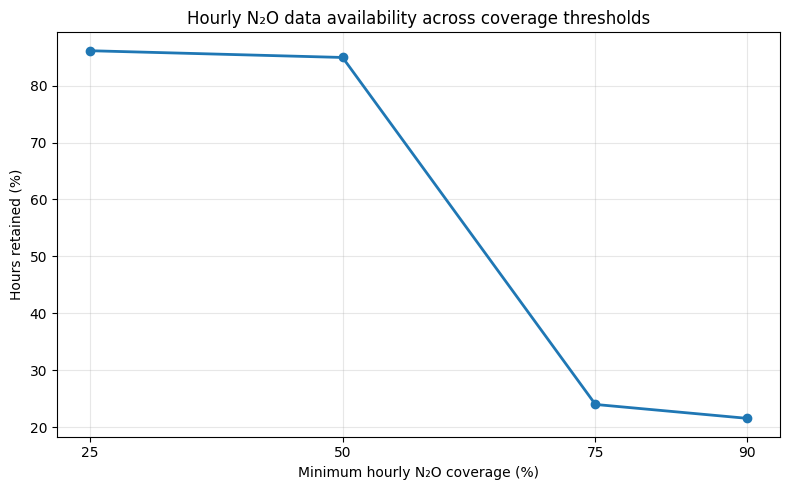

In [170]:
# N2O coverage sensitivity across hourly coverage thresholds

plt.figure(figsize=(8, 5))

plot_coverage = n2o_threshold_sensitivity.copy()
plot_coverage["threshold_pct"] = plot_coverage["threshold"] * 100

plt.plot(
    plot_coverage["threshold_pct"],
    plot_coverage["percent_hours_retained"],
    marker="o",
    linewidth=2
)

plt.xlabel("Minimum hourly N₂O coverage (%)")
plt.ylabel("Hours retained (%)")
plt.title("Hourly N₂O data availability across coverage thresholds")

plt.xticks([25, 50, 75, 90])
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../figures/n2o_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
# Cell 15 — Raw-to-hourly conservation check
# The raw reference and hourly totals are generated using the SAME quality rule.

conservation_rows = []

for name in variable_map_df["name"]:
    raw_count = int(
        raw_quality_counts.loc[
            raw_quality_counts["variable"] == name,
            "raw_valid_count"
        ].iloc[0]
    )

    hourly_count = con.execute(
        f"SELECT SUM({name}_valid_count) FROM hourly_avedore"
    ).fetchone()[0]

    hourly_count = int(hourly_count) if hourly_count is not None else None

    conservation_rows.append({
        "variable": name,
        "raw_quality_aware_count": raw_count,
        "hourly_valid_count_sum": hourly_count,
        "difference": hourly_count - raw_count if hourly_count is not None else None,
        "matches": hourly_count == raw_count if hourly_count is not None else False
    })

conservation_check = pd.DataFrame(conservation_rows)
conservation_check


,variable,raw_quality_aware_count,hourly_valid_count_sum,difference,matches
0,total_airflow,477289,477289,0,True
1,t1_valve_pct,502835,502835,0,True
2,t1_n2o,452814,452814,0,True
3,t1_nh4,465607,465607,0,True
4,t1_no3,494952,494952,0,True
5,t1_do,451633,451633,0,True
6,t1_do_setpoint,526285,526285,0,True
7,t1_phase,519349,519349,0,True
8,t1_airflow_est,464527,464527,0,True
9,t1_ss,449296,449296,0,True


In [38]:
# Cell 16 — Conservation validation gate
failed_conservation = conservation_check[
    ~conservation_check["matches"]
].copy()

print("Variables failing raw-to-hourly conservation:", len(failed_conservation))

if len(failed_conservation) == 0:
    print("PASS: all 24 variables conserve their valid observations.")
else:
    print("FAIL: investigate these variables before freezing Stage 2B.")
    failed_conservation


Variables failing raw-to-hourly conservation: 0
PASS: all 24 variables conserve their valid observations.


In [39]:
# Cell 17 — Full hourly coverage table
coverage_parts = ["hour_start", "raw_observed_rows"]

for name in variable_map_df["name"]:
    coverage_parts.append(f"{name}_valid_count AS {name}_valid_count")
    coverage_parts.append(
        f"{name}_valid_count * 1.0 / NULLIF(raw_observed_rows, 0) "
        f"AS {name}_coverage"
    )

hourly_coverage = con.execute(
    f"""
    SELECT {",".join(coverage_parts)}
    FROM hourly_avedore
    ORDER BY hour_start
    """
).df()

print("Hourly coverage rows:", len(hourly_coverage))
print("Hourly coverage columns:", len(hourly_coverage.columns))
hourly_coverage.head()


Hourly coverage rows: 17545
Hourly coverage columns: 50


,hour_start,raw_observed_rows,total_airflow_valid_count,total_airflow_coverage,t1_valve_pct_valid_count,t1_valve_pct_coverage,t1_n2o_valid_count,t1_n2o_coverage,t1_nh4_valid_count,t1_nh4_coverage,t1_no3_valid_count,t1_no3_coverage,t1_do_valid_count,t1_do_coverage,t1_do_setpoint_valid_count,t1_do_setpoint_coverage,t1_phase_valid_count,t1_phase_coverage,t1_airflow_est_valid_count,t1_airflow_est_coverage,t1_ss_valid_count,t1_ss_coverage,t1_temp_valid_count,t1_temp_coverage,t2_valve_pct_valid_count,t2_valve_pct_coverage,t2_do_valid_count,t2_do_coverage,t2_do_setpoint_valid_count,t2_do_setpoint_coverage,t2_phase_valid_count,t2_phase_coverage,t2_airflow_est_valid_count,t2_airflow_est_coverage,t2_ss_valid_count,t2_ss_coverage,t2_temp_valid_count,t2_temp_coverage,phase_code_valid_count,phase_code_coverage,inlet_tank_valid_count,inlet_tank_coverage,outlet_tank_valid_count,outlet_tank_coverage,t1_po4_valid_count,t1_po4_coverage,inlet_flow_valid_count,inlet_flow_coverage,stormwater_mode_valid_count,stormwater_mode_coverage
0,2022-06-12 03:00:00+05:30,29,0,0.000000,0,0.0,15,0.517241,15,0.517241,15,0.517241,15,0.517241,14,0.482759,15,0.517241,0,0.0,13,0.448276,0,0.0,0,0.0,15,0.517241,14,0.482759,15,0.517241,0,0.0,13,0.448276,0,0.0,14,0.482759,14,0.482759,14,0.482759,0,0.0,0,0.0,14,0.482759
1,2022-06-12 04:00:00+05:30,60,9,0.150000,0,0.0,30,0.500000,30,0.500000,30,0.500000,30,0.500000,30,0.500000,30,0.500000,0,0.0,17,0.283333,0,0.0,0,0.0,30,0.500000,30,0.500000,30,0.500000,0,0.0,8,0.133333,0,0.0,30,0.500000,30,0.500000,30,0.500000,0,0.0,0,0.0,30,0.500000
2,2022-06-12 05:00:00+05:30,60,9,0.150000,0,0.0,30,0.500000,30,0.500000,30,0.500000,30,0.500000,30,0.500000,30,0.500000,0,0.0,21,0.350000,0,0.0,0,0.0,30,0.500000,30,0.500000,30,0.500000,0,0.0,26,0.433333,0,0.0,30,0.500000,30,0.500000,30,0.500000,0,0.0,0,0.0,30,0.500000
3,2022-06-12 06:00:00+05:30,60,1,0.016667,0,0.0,30,0.500000,30,0.500000,30,0.500000,30,0.500000,30,0.500000,30,0.500000,0,0.0,18,0.300000,0,0.0,0,0.0,30,0.500000,30,0.500000,30,0.500000,0,0.0,16,0.266667,0,0.0,30,0.500000,30,0.500000,30,0.500000,0,0.0,0,0.0,30,0.500000
4,2022-06-12 07:00:00+05:30,60,4,0.066667,0,0.0,30,0.500000,30,0.500000,30,0.500000,30,0.500000,30,0.500000,30,0.500000,0,0.0,9,0.150000,0,0.0,0,0.0,30,0.500000,30,0.500000,30,0.500000,0,0.0,21,0.350000,0,0.0,30,0.500000,30,0.500000,30,0.500000,0,0.0,0,0.0,30,0.500000


In [40]:
# Cell 18 — SQL window-function diagnostic using LAG()
lag_diagnostic = con.execute("""
    WITH hourly AS (
        SELECT
            hour_start,
            raw_observed_rows,
            LAG(raw_observed_rows) OVER (
                ORDER BY hour_start
            ) AS previous_hour_observed_rows
        FROM hourly_avedore
    )
    SELECT
        hour_start,
        raw_observed_rows,
        previous_hour_observed_rows,
        raw_observed_rows - previous_hour_observed_rows
            AS change_from_previous_hour
    FROM hourly
    WHERE raw_observed_rows < 30
       OR previous_hour_observed_rows < 30
    ORDER BY hour_start
""").df()

print("Low-observation temporal diagnostic rows:", len(lag_diagnostic))
lag_diagnostic


Low-observation temporal diagnostic rows: 8


,hour_start,raw_observed_rows,previous_hour_observed_rows,change_from_previous_hour
0,2022-06-12 03:00:00+05:30,29,<NA>,<NA>
1,2022-06-12 04:00:00+05:30,60,29,31
2,2022-11-08 14:00:00+05:30,29,30,-1
3,2022-11-08 15:00:00+05:30,31,29,2
4,2022-11-28 21:00:00+05:30,29,30,-1
5,2022-11-28 22:00:00+05:30,30,29,1
6,2023-04-11 13:00:00+05:30,24,30,-6
7,2023-04-11 14:00:00+05:30,37,24,13


In [41]:
# Cell 19 — Final Stage 2B validation gate
hourly_row_count = con.execute(
    "SELECT COUNT(*) FROM hourly_avedore"
).fetchone()[0]

stage_2b_gate = pd.DataFrame({
    "validation_check": [
        "Hourly table contains records",
        "One unique record per hour",
        "N₂O coverage is bounded between 0 and 1",
        "All 24 variables pass raw-to-hourly conservation"
    ],
    "status": [
        hourly_row_count > 0,
        hourly_time_check.loc[0, "duplicate_hour_rows"] == 0,
        n2o_hourly_coverage["n2o_coverage"]
            .between(0, 1, inclusive="both")
            .all(),
        len(failed_conservation) == 0
    ]
})

stage_2b_gate


,validation_check,status
0,Hourly table contains records,True
1,One unique record per hour,True
2,N₂O coverage is bounded between 0 and 1,True
3,All 24 variables pass raw-to-hourly conservation,True


In [42]:
# Cell 20 — Export validated Stage 2B hourly coverage table
#
# This file is the hand-off from Stage 2B → Stage 2C.
# Stage 2C will load this file instead of depending on variables
# from the Stage 2B Jupyter kernel.

from pathlib import Path

STAGE_2B_EXPORT = Path("../data/processed/stage_2B_hourly_coverage.csv")

hourly_coverage.to_csv(
    STAGE_2B_EXPORT,
    index=False
)

print("Stage 2B export completed.")
print("File:", STAGE_2B_EXPORT.resolve())
print("Rows:", len(hourly_coverage))
print("Columns:", len(hourly_coverage.columns))

print("\nTime range:")
print("Start:", hourly_coverage["hour_start"].min())
print("End:  ", hourly_coverage["hour_start"].max())

print("\nExported file size:",
      round(STAGE_2B_EXPORT.stat().st_size / 1024**2, 2),
      "MB")

Stage 2B export completed.
File: C:\Users\Dell\Data_S\N2O_Forecasting_Project\data\processed\stage_2B_hourly_coverage.csv
Rows: 17545
Columns: 50

Time range:
Start: 2022-06-12 03:00:00+05:30
End:   2024-06-12 03:00:00+05:30

Exported file size: 4.18 MB


# Stage 2B completion rule

Stage 2B is complete only when all validation statuses are `True`.

The final N₂O coverage threshold remains deliberately undecided.

If the conservation gate passes, the next stage can examine target/predictor coverage and temporal continuity before selecting the modelling-ready hourly validity rule.


# 4. Hourly Aggregation and Target Availability


In [43]:
# Cell 1 — Imports and Stage 2B hand-off

from pathlib import Path
import pandas as pd
import numpy as np

STAGE_2B_FILE = Path("../data/processed/stage_2B_hourly_coverage.csv")

print("Working directory:", Path.cwd())
print("Expected Stage 2B file:", STAGE_2B_FILE.resolve())

if not STAGE_2B_FILE.exists():
    raise FileNotFoundError(
        f"Stage 2B export was not found at:\n{STAGE_2B_FILE.resolve()}\n\n"
        "Run the Stage 2B export cell first and place the CSV in the same project folder."
    )

coverage_table = pd.read_csv(
    STAGE_2B_FILE,
    parse_dates=["hour_start"]
)

print("Stage 2B table loaded.")
print("Rows:", len(coverage_table))
print("Columns:", len(coverage_table.columns))
print("First hour:", coverage_table["hour_start"].min())
print("Last hour:", coverage_table["hour_start"].max())


Working directory: C:\Users\Dell\Data_S\N2O_Forecasting_Project\notebooks
Expected Stage 2B file: C:\Users\Dell\Data_S\N2O_Forecasting_Project\data\processed\stage_2B_hourly_coverage.csv
Stage 2B table loaded.
Rows: 17545
Columns: 50
First hour: 2022-06-12 03:00:00+05:30
Last hour: 2024-06-12 03:00:00+05:30


In [44]:
# Cell 2 — Basic integrity checks for the Stage 2B hand-off

coverage_table = coverage_table.sort_values("hour_start").reset_index(drop=True)

duplicate_hours = int(coverage_table["hour_start"].duplicated().sum())
null_hours = int(coverage_table["hour_start"].isna().sum())

print("Duplicate hour rows:", duplicate_hours)
print("Null hour_start values:", null_hours)

if duplicate_hours != 0:
    raise ValueError("Duplicate hourly records found. Stage 2B output must be corrected before Stage 2C.")

if null_hours != 0:
    raise ValueError("Null hour_start values found. Stage 2B output must be corrected before Stage 2C.")

print("Basic hand-off integrity: PASS")


Duplicate hour rows: 0
Null hour_start values: 0
Basic hand-off integrity: PASS


In [45]:
# Cell 3 — Identify coverage and valid-count columns

coverage_columns = [
    c for c in coverage_table.columns
    if c.endswith("_coverage")
]

valid_count_columns = [
    c for c in coverage_table.columns
    if c.endswith("_valid_count")
]

print("Coverage columns:", len(coverage_columns))
print("Valid-count columns:", len(valid_count_columns))

print("\nCoverage columns:")
for c in coverage_columns:
    print(" -", c)

if len(coverage_columns) == 0:
    raise ValueError("No *_coverage columns were found in the Stage 2B export.")


Coverage columns: 24
Valid-count columns: 24

Coverage columns:
 - total_airflow_coverage
 - t1_valve_pct_coverage
 - t1_n2o_coverage
 - t1_nh4_coverage
 - t1_no3_coverage
 - t1_do_coverage
 - t1_do_setpoint_coverage
 - t1_phase_coverage
 - t1_airflow_est_coverage
 - t1_ss_coverage
 - t1_temp_coverage
 - t2_valve_pct_coverage
 - t2_do_coverage
 - t2_do_setpoint_coverage
 - t2_phase_coverage
 - t2_airflow_est_coverage
 - t2_ss_coverage
 - t2_temp_coverage
 - phase_code_coverage
 - inlet_tank_coverage
 - outlet_tank_coverage
 - t1_po4_coverage
 - inlet_flow_coverage
 - stormwater_mode_coverage


In [46]:
# Cell 4 — Define candidate continuous process variables

# These are candidate variables for coverage assessment.
# They are NOT yet the final modelling feature list.

candidate_continuous = [
    "t1_n2o",
    "t1_nh4",
    "t1_no3",
    "t1_do",
    "t1_do_setpoint",
    "t1_airflow_est",
    "t1_ss",
    "t1_temp",
    "inlet_flow",
]

candidate_continuous_coverage = [
    f"{name}_coverage" for name in candidate_continuous
]

missing_candidates = [
    c for c in candidate_continuous_coverage
    if c not in coverage_table.columns
]

if missing_candidates:
    raise ValueError(
        "The following candidate coverage columns are missing:\n"
        + "\n".join(missing_candidates)
    )

print("Candidate continuous variables:")
for name in candidate_continuous:
    print(" -", name)


Candidate continuous variables:
 - t1_n2o
 - t1_nh4
 - t1_no3
 - t1_do
 - t1_do_setpoint
 - t1_airflow_est
 - t1_ss
 - t1_temp
 - inlet_flow


In [47]:
# Cell 5 — Define candidate state/context variables separately

# These variables represent process states or operating context.
# Their later use will depend on state availability and process interpretation,
# not simply on treating them like continuous concentration measurements.

candidate_state = [
    "phase_code",
    "inlet_tank",
    "outlet_tank",
    "stormwater_mode",
]

candidate_state_coverage = [
    f"{name}_coverage" for name in candidate_state
]

available_state = [
    c for c in candidate_state_coverage
    if c in coverage_table.columns
]

print("Available candidate state/context coverage columns:")
for c in available_state:
    print(" -", c)

missing_state = [
    c for c in candidate_state_coverage
    if c not in coverage_table.columns
]

if missing_state:
    print("\nState/context columns not present in Stage 2B export:")
    for c in missing_state:
        print(" -", c)


Available candidate state/context coverage columns:
 - phase_code_coverage
 - inlet_tank_coverage
 - outlet_tank_coverage
 - stormwater_mode_coverage


In [48]:
# Cell 6 — Confirm the actual Stage 2B candidate coverage columns

print("Candidate coverage columns expected by Stage 2C:")
for col in candidate_continuous_coverage:
    print(" -", col)

missing_candidates = [
    c for c in candidate_continuous_coverage
    if c not in coverage_table.columns
]

print("\nMissing candidate coverage columns:", len(missing_candidates))

if missing_candidates:
    print(missing_candidates)
    print("\nAvailable coverage columns:")
    print(sorted(coverage_columns))
    raise ValueError(
        "Stage 2C candidate names do not match the Stage 2B export. "
        "Check the displayed available coverage columns before proceeding."
    )

print("Candidate column mapping: PASS")


Candidate coverage columns expected by Stage 2C:
 - t1_n2o_coverage
 - t1_nh4_coverage
 - t1_no3_coverage
 - t1_do_coverage
 - t1_do_setpoint_coverage
 - t1_airflow_est_coverage
 - t1_ss_coverage
 - t1_temp_coverage
 - inlet_flow_coverage

Missing candidate coverage columns: 0
Candidate column mapping: PASS


In [49]:
# Cell 7 — Variable-level coverage summary

coverage_summary = []

for name in candidate_continuous:
    col = f"{name}_coverage"
    s = pd.to_numeric(coverage_table[col], errors="coerce")

    coverage_summary.append({
        "variable": name,
        "mean_coverage": s.mean(),
        "median_coverage": s.median(),
        "p25_coverage": s.quantile(0.25),
        "p75_coverage": s.quantile(0.75),
        "hours_ge_25pct": int((s >= 0.25).sum()),
        "hours_ge_50pct": int((s >= 0.50).sum()),
        "hours_ge_75pct": int((s >= 0.75).sum()),
        "hours_ge_90pct": int((s >= 0.90).sum()),
    })

coverage_summary = pd.DataFrame(coverage_summary)

coverage_summary.sort_values(
    "median_coverage",
    ascending=False
)


,variable,mean_coverage,median_coverage,p25_coverage,p75_coverage,hours_ge_25pct,hours_ge_50pct,hours_ge_75pct,hours_ge_90pct
0,t1_n2o,0.550615,0.5,0.500000,0.681818,15111,14903,4211,3783
1,t1_nh4,0.563407,0.5,0.500000,0.681818,15609,14816,4204,3789
2,t1_no3,0.597560,0.5,0.500000,0.769231,16526,16263,4448,4013
3,t1_do,0.549504,0.5,0.500000,0.681818,15069,14892,4211,3783
4,t1_do_setpoint,0.632439,0.5,0.500000,0.833333,17545,17540,4635,4194
5,t1_airflow_est,0.557911,0.5,0.500000,0.638298,15675,13775,4081,3636
6,t1_ss,0.536592,0.5,0.466667,0.545455,15840,12724,3446,2899
7,t1_temp,0.550512,0.5,0.500000,0.652174,15218,15052,4100,3673
8,inlet_flow,0.539173,0.5,0.500000,0.638298,14963,14210,4050,3609


In [50]:
# Cell 8 — Raw hourly observation-density diagnostic

# raw_observed_rows is the number of raw timestamps represented in each hour.
# This is descriptive context for interpreting coverage; it is not itself
# a completeness threshold.

if "raw_observed_rows" not in coverage_table.columns:
    raise ValueError("raw_observed_rows is missing from the Stage 2B export.")

raw_density = coverage_table["raw_observed_rows"].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
)

raw_density


count    17545.000000
mean        51.685095
std         12.831085
min         24.000000
1%          30.000000
25%         36.000000
50%         60.000000
75%         60.000000
99%         60.000000
max         60.000000
Name: raw_observed_rows, dtype: float64

### Interpretation rule for coverage

The coverage metric is:

**valid observations / raw timestamps observed in that hour**

It should **not** be described as a universal percentage of an ideal sampling schedule.

The dataset documentation describes quality flags and the underlying time-series construction; the actual CSV also contains variable missingness and non-uniform timestamp intervals. Therefore, Stage 2C uses coverage as an empirical completeness indicator and retains the raw-observation-density diagnostic for context.

The thresholds below are sensitivity scenarios, not predetermined scientific truths.


In [51]:
# Cell 10 — Correct one-hour target availability

n2o_cov_col = "t1_n2o_coverage"

if n2o_cov_col not in coverage_table.columns:
    raise ValueError(f"Required target coverage column missing: {n2o_cov_col}")

# Keep timestamps as pandas datetime Series throughout.
# Do NOT use NumPy .values for this comparison because timezone information
# can be lost during conversion.
current_hours = coverage_table["hour_start"].copy()
next_row_hours = current_hours.shift(-1)

target_check = pd.DataFrame({
    "hour_start": current_hours,
    "target_hour": current_hours + pd.Timedelta(hours=1),
    "next_row_hour": next_row_hours,
    "current_n2o_coverage": coverage_table[n2o_cov_col],
    "next_row_n2o_coverage": coverage_table[n2o_cov_col].shift(-1),
})

target_check["is_exact_next_hour"] = (
    target_check["next_row_hour"] == target_check["target_hour"]
)

# Only an exactly consecutive hourly record can be the t+1 target.
target_check["n2o_t_plus_1_coverage"] = np.where(
    target_check["is_exact_next_hour"],
    target_check["next_row_n2o_coverage"],
    np.nan,
)

target_check["target_any_valid"] = (
    target_check["n2o_t_plus_1_coverage"] > 0
)

print(
    "Rows with an exact next-hour record:",
    int(target_check["is_exact_next_hour"].sum())
)
print(
    "Rows without an exact next-hour record:",
    int((~target_check["is_exact_next_hour"]).sum())
)
print(
    "Rows with any valid exact t+1 N2O:",
    int(target_check["target_any_valid"].sum())
)


Rows with an exact next-hour record: 17544
Rows without an exact next-hour record: 1
Rows with any valid exact t+1 N2O: 15125


In [52]:
# Cell 11 — Validate the exact t+1 construction

invalid_nonconsecutive = target_check[
    target_check["n2o_t_plus_1_coverage"].notna()
    & (~target_check["is_exact_next_hour"])
]

if len(invalid_nonconsecutive) != 0:
    raise AssertionError(
        "Exact t+1 validation failed: a non-consecutive row was assigned a target."
    )

exact_next_hour_count = int(
    target_check["is_exact_next_hour"].sum()
)

# A zero count is a failure, not a passing empty result.
if exact_next_hour_count == 0:
    raise AssertionError(
        "No exact t+1 hourly records were detected. "
        "Check timestamp type/timezone handling before proceeding."
    )

valid_target_rows = target_check[
    target_check["is_exact_next_hour"]
].copy()

print("Exact t+1 construction: PASS")
print("Rows with an exact t+1 hour:", exact_next_hour_count)
print(
    "Rows with any valid N2O at exact t+1:",
    int(valid_target_rows["target_any_valid"].sum())
)


Exact t+1 construction: PASS
Rows with an exact t+1 hour: 17544
Rows with any valid N2O at exact t+1: 15125


In [53]:
# Cell 12 — Target-availability sensitivity

target_sensitivity = []

for threshold in [0.25, 0.50, 0.75, 0.90]:
    valid_target = (
        target_check["is_exact_next_hour"]
        & (target_check["n2o_t_plus_1_coverage"] >= threshold)
    )

    target_sensitivity.append({
        "coverage_threshold": threshold,
        "valid_t_plus_1_targets": int(valid_target.sum()),
        "percent_of_hourly_rows": 100 * valid_target.mean(),
    })

target_sensitivity = pd.DataFrame(target_sensitivity)

target_sensitivity


,coverage_threshold,valid_t_plus_1_targets,percent_of_hourly_rows
0,0.25,15110,86.121402
1,0.50,14902,84.935879
2,0.75,4211,24.001140
3,0.90,3783,21.561698


In [54]:
# Cell 13 — Candidate predictor completeness scenarios

thresholds = [0.25, 0.50, 0.75, 0.90]

predictor_sensitivity = []

candidate_cov = coverage_table[
    candidate_continuous_coverage
].apply(pd.to_numeric, errors="coerce")

for threshold in thresholds:
    complete_predictors = (
        candidate_cov.ge(threshold).all(axis=1)
    )

    predictor_sensitivity.append({
        "coverage_threshold": threshold,
        "predictor_complete_hours": int(complete_predictors.sum()),
        "percent_of_hourly_rows": 100 * complete_predictors.mean(),
    })

predictor_sensitivity = pd.DataFrame(predictor_sensitivity)

predictor_sensitivity


,coverage_threshold,predictor_complete_hours,percent_of_hourly_rows
0,0.25,11052,62.992306
1,0.50,7581,43.208891
2,0.75,2940,16.756911
3,0.90,2434,13.872898


In [55]:
# Cell 14 — Candidate modelling-row scenarios with exact t+1 target

scenario_rows = []

for threshold in thresholds:
    predictors_ok = candidate_cov.ge(threshold).all(axis=1)

    target_ok = (
        target_check["is_exact_next_hour"]
        & (target_check["n2o_t_plus_1_coverage"] >= threshold)
    )

    modelling_candidate = predictors_ok & target_ok

    scenario_rows.append({
        "coverage_threshold": threshold,
        "predictor_complete": int(predictors_ok.sum()),
        "exact_t_plus_1_target_available": int(target_ok.sum()),
        "modelling_candidate_rows": int(modelling_candidate.sum()),
        "percent_of_all_hours": 100 * modelling_candidate.mean(),
    })

scenario_sensitivity = pd.DataFrame(scenario_rows)

scenario_sensitivity


,coverage_threshold,predictor_complete,exact_t_plus_1_target_available,modelling_candidate_rows,percent_of_all_hours
0,0.25,11052,15110,11039,62.918210
1,0.50,7581,14902,7510,42.804218
2,0.75,2940,4211,2873,16.375036
3,0.90,2434,3783,2373,13.525221


In [56]:
# Cell 15 — Temporal continuity for every candidate threshold

def continuity_summary(mask, label):
    hours = coverage_table.loc[mask, "hour_start"].sort_values()

    if len(hours) == 0:
        return {
            "coverage_threshold": label,
            "candidate_rows": 0,
            "contiguous_blocks": 0,
            "median_gap_hours": np.nan,
            "p95_gap_hours": np.nan,
            "max_gap_hours": np.nan,
        }

    gaps = hours.diff().dt.total_seconds().div(3600).dropna()

    # A gap of exactly 1 hour means consecutive hourly observations.
    # Values >1 indicate a break in the candidate sequence.
    breaks = gaps > 1

    return {
        "coverage_threshold": label,
        "candidate_rows": int(len(hours)),
        "contiguous_blocks": int(breaks.sum() + 1),
        "median_gap_hours": float(gaps.median()) if len(gaps) else np.nan,
        "p95_gap_hours": float(gaps.quantile(0.95)) if len(gaps) else np.nan,
        "max_gap_hours": float(gaps.max()) if len(gaps) else np.nan,
    }

continuity_rows = []

for threshold in thresholds:
    predictors_ok = candidate_cov.ge(threshold).all(axis=1)

    target_ok = (
        target_check["is_exact_next_hour"]
        & (target_check["n2o_t_plus_1_coverage"] >= threshold)
    )

    mask = predictors_ok & target_ok

    continuity_rows.append(
        continuity_summary(mask, threshold)
    )

continuity_sensitivity = pd.DataFrame(continuity_rows)

continuity_sensitivity


,coverage_threshold,candidate_rows,contiguous_blocks,median_gap_hours,p95_gap_hours,max_gap_hours
0,0.25,11039,752,1.0,2.0,1014.0
1,0.50,7510,1674,1.0,4.0,1030.0
2,0.75,2873,465,1.0,4.0,4050.0
3,0.90,2373,450,1.0,5.0,4102.0


In [57]:
# Cell 16 — N2O low-coverage gap analysis for every candidate threshold

n2o_gap_rows = []

for threshold in thresholds:
    good = coverage_table[n2o_cov_col] >= threshold

    # A "gap" here means consecutive hourly records where N2O does not
    # satisfy the candidate completeness threshold.
    bad = ~good

    group_id = bad.ne(bad.shift()).cumsum()
    bad_blocks = (
        coverage_table.loc[bad]
        .assign(group_id=group_id[bad].values)
        .groupby("group_id")
        .size()
    )

    if len(bad_blocks):
        max_gap = int(bad_blocks.max())
        median_gap = float(bad_blocks.median())
        number_of_blocks = int(len(bad_blocks))
    else:
        max_gap = 0
        median_gap = 0
        number_of_blocks = 0

    n2o_gap_rows.append({
        "coverage_threshold": threshold,
        "n2o_below_threshold_blocks": number_of_blocks,
        "median_gap_hours": median_gap,
        "max_gap_hours": max_gap,
    })

n2o_gap_summary = pd.DataFrame(n2o_gap_rows)

n2o_gap_summary


,coverage_threshold,n2o_below_threshold_blocks,median_gap_hours,max_gap_hours
0,0.25,16,1.0,2260
1,0.50,179,1.0,2260
2,0.75,151,6.0,3900
3,0.90,142,10.0,3902


In [58]:
# Cell 17 — Inspect candidate variables individually before freezing features

individual_threshold_review = []

for name in candidate_continuous:
    col = f"{name}_coverage"
    s = pd.to_numeric(coverage_table[col], errors="coerce")

    individual_threshold_review.append({
        "variable": name,
        "hours_ge_25pct": int((s >= 0.25).sum()),
        "hours_ge_50pct": int((s >= 0.50).sum()),
        "hours_ge_75pct": int((s >= 0.75).sum()),
        "hours_ge_90pct": int((s >= 0.90).sum()),
    })

individual_threshold_review = pd.DataFrame(individual_threshold_review)

individual_threshold_review


,variable,hours_ge_25pct,hours_ge_50pct,hours_ge_75pct,hours_ge_90pct
0,t1_n2o,15111,14903,4211,3783
1,t1_nh4,15609,14816,4204,3789
2,t1_no3,16526,16263,4448,4013
3,t1_do,15069,14892,4211,3783
4,t1_do_setpoint,17545,17540,4635,4194
5,t1_airflow_est,15675,13775,4081,3636
6,t1_ss,15840,12724,3446,2899
7,t1_temp,15218,15052,4100,3673
8,inlet_flow,14963,14210,4050,3609


In [59]:
# Cell 19 — Generate a decision table for human review

decision_table = scenario_sensitivity.merge(
    continuity_sensitivity,
    on="coverage_threshold",
    how="left"
).merge(
    n2o_gap_summary,
    on="coverage_threshold",
    how="left",
    suffixes=("_candidate_rows", "_n2o")
)

decision_table


,coverage_threshold,predictor_complete,exact_t_plus_1_target_available,modelling_candidate_rows,percent_of_all_hours,candidate_rows,contiguous_blocks,median_gap_hours_candidate_rows,p95_gap_hours,max_gap_hours_candidate_rows,n2o_below_threshold_blocks,median_gap_hours_n2o,max_gap_hours_n2o
0,0.25,11052,15110,11039,62.918210,11039,752,1.0,2.0,1014.0,16,1.0,2260
1,0.50,7581,14902,7510,42.804218,7510,1674,1.0,4.0,1030.0,179,1.0,2260
2,0.75,2940,4211,2873,16.375036,2873,465,1.0,4.0,4050.0,151,6.0,3900
3,0.90,2434,3783,2373,13.525221,2373,450,1.0,5.0,4102.0,142,10.0,3902


In [60]:
# Cell 17 — Stage 2C analytical validation gate

# This gate checks actual analytical conditions.
# It does NOT choose a final coverage threshold or final feature set.

checks = {
    "Stage 2B table loaded": len(coverage_table) > 0,
    "hour_start has no nulls": coverage_table["hour_start"].notna().all(),
    "hour_start has no duplicates": coverage_table["hour_start"].duplicated().sum() == 0,
    "coverage columns exist": len(coverage_columns) > 0,
    "candidate coverage columns exist": len(missing_candidates) == 0,
    "exact t+1 rows exist": exact_next_hour_count > 0,
    "no non-consecutive target assignments": len(invalid_nonconsecutive) == 0,
    "all candidate thresholds evaluated": set(thresholds) == set(
        scenario_sensitivity["coverage_threshold"]
    ),
    "temporal continuity evaluated": len(continuity_sensitivity) == len(thresholds),
    "N2O gap analysis evaluated": len(n2o_gap_summary) == len(thresholds),
}

stage_2c_gate = pd.DataFrame({
    "validation_check": list(checks.keys()),
    "status": list(checks.values()),
})

stage_2c_gate


,validation_check,status
0,Stage 2B table loaded,True
1,hour_start has no nulls,True
2,hour_start has no duplicates,True
3,coverage columns exist,True
4,candidate coverage columns exist,True
5,exact t+1 rows exist,True
6,no non-consecutive target assignments,True
7,all candidate thresholds evaluated,True
8,temporal continuity evaluated,True
9,N2O gap analysis evaluated,True


In [61]:
# Cell 18 — Final Stage 2C status

all_checks_pass = bool(stage_2c_gate["status"].all())

print(
    "Stage 2C analytical validation:",
    "PASS" if all_checks_pass else "FAIL"
)

if not all_checks_pass:
    failed = stage_2c_gate.loc[
        ~stage_2c_gate["status"],
        "validation_check"
    ].tolist()

    print("\nFailed checks:")
    for item in failed:
        print(" -", item)

    raise AssertionError(
        "Stage 2C validation failed. Correct the failed checks before proceeding."
    )

print("\nStage 2C analytical validation passed.")
print("No final coverage threshold has been selected.")
print("No final modelling feature set has been frozen.")
print("No target interpolation has been performed.")
print("No ML model has been trained.")


Stage 2C analytical validation: PASS

Stage 2C analytical validation passed.
No final coverage threshold has been selected.
No final modelling feature set has been frozen.
No target interpolation has been performed.
No ML model has been trained.


# 5. Statistical Analysis and Exploratory Data Analysis


In [62]:
# Cell 1 — Imports and plotting configuration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

print("Stage 3 imports: PASS")

Stage 3 imports: PASS


## Stage 2 → Stage 3 hand-off

We load the Stage 2B hourly coverage table and the raw CSV. The hourly values are reconstructed using the same quality-aware rule and checked against Stage 2B. This prevents a second, silently different aggregation pipeline from entering the analysis.


In [63]:
# Cell 2 — Load Stage 2B coverage table and raw data

RAW_PATH = "../data/raw/aved_raw.csv"
STAGE2B_PATH = "../data/processed/stage_2B_hourly_coverage.csv"

# The frozen Stage 2B export stores hour_start with a fixed +05:30
# timestamp convention. Reuse that convention here so the reconstructed
# hourly table can be validated exactly against the frozen Stage 2B hand-off.
STAGE2B_TIMEZONE = "Asia/Kolkata"
PLANT_TIMEZONE = "Europe/Copenhagen"

raw = pd.read_csv(RAW_PATH)
coverage_table = pd.read_csv(STAGE2B_PATH)

raw["time"] = pd.to_datetime(raw["time"], utc=True).dt.tz_convert(STAGE2B_TIMEZONE)
coverage_table["hour_start"] = pd.to_datetime(
    coverage_table["hour_start"], utc=True
).dt.tz_convert(STAGE2B_TIMEZONE)

print("Raw shape:", raw.shape)
print("Stage 2B coverage shape:", coverage_table.shape)
print("Raw time range:", raw["time"].min(), "to", raw["time"].max())
print("Stage 2B hour range:", coverage_table["hour_start"].min(), "to", coverage_table["hour_start"].max())

Raw shape: (906815, 49)
Stage 2B coverage shape: (17545, 50)
Raw time range: 2022-06-12 03:31:00+05:30 to 2024-06-12 03:29:00+05:30
Stage 2B hour range: 2022-06-12 03:00:00+05:30 to 2024-06-12 03:00:00+05:30


In [64]:
# Cell 3 — Reconstruct hourly process values using the Stage 2 quality rule

# Actual raw-column mapping established in the earlier stages.
column_map = {
    "t1_n2o": ("BIOLOGY.LINE 3 TANK 1.N2O value", "BIOLOGY.LINE 3 TANK 1.N2O quality"),
    "t1_nh4": ("BIOLOGY.LINE 3 TANK 1.NH4 value", "BIOLOGY.LINE 3 TANK 1.NH4 quality"),
    "t1_no3": ("BIOLOGY.LINE 3 TANK 1.NO3 value", "BIOLOGY.LINE 3 TANK 1.NO3 quality"),
    "t1_do": ("BIOLOGY.LINE 3 TANK 1.O2 value", "BIOLOGY.LINE 3 TANK 1.O2 quality"),
    "t1_do_setpoint": ("BIOLOGY.LINE 3 TANK 1.O2.SETPOINT value", "BIOLOGY.LINE 3 TANK 1.O2.SETPOINT quality"),
    "t1_phase": ("BIOLOGY.LINE 3 TANK 1.PROCESSPHASE value", "BIOLOGY.LINE 3 TANK 1.PROCESSPHASE quality"),
    "t1_airflow_est": ("BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW value", "BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW quality"),
    "t1_ss": ("BIOLOGY.LINE 3 TANK 1.SS value", "BIOLOGY.LINE 3 TANK 1.SS quality"),
    "t1_temp": ("BIOLOGY.LINE 3 TANK 1.TEMPERATURE value", "BIOLOGY.LINE 3 TANK 1.TEMPERATURE quality"),
    "inlet_flow": ("INLET.Q value", "INLET.Q quality"),
    "stormwater_mode": ("INLET.STATE.SWM INLET FLOW value", "INLET.STATE.SWM INLET FLOW quality"),
    "inlet_tank": ("BIOLOGY.LINE 3.PROCESSPHASE.INLET TANK value", "BIOLOGY.LINE 3.PROCESSPHASE.INLET TANK quality"),
    "outlet_tank": ("BIOLOGY.LINE 3.PROCESSPHASE.OUTLET TANK value", "BIOLOGY.LINE 3.PROCESSPHASE.OUTLET TANK quality"),
}

required_raw = [x for pair in column_map.values() for x in pair]
missing_raw = [c for c in required_raw if c not in raw.columns]

if missing_raw:
    raise KeyError(f"Missing raw columns: {missing_raw}")

# Stage 2B uses a fixed-offset timezone, so hourly flooring is DST-safe.
# This preserves the exact timestamp convention used by the frozen hand-off.
raw_hourly = pd.DataFrame({
    "hour_start": raw["time"].dt.floor("h")
})

for name, (value_col, quality_col) in column_map.items():
    value = pd.to_numeric(raw[value_col], errors="coerce")
    quality = pd.to_numeric(raw[quality_col], errors="coerce")
    valid = value.where(quality.eq(0))

    if name in {"t1_phase", "stormwater_mode", "inlet_tank", "outlet_tank"}:
        agg = valid.groupby(raw_hourly["hour_start"]).agg(
            lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan
        )
    else:
        agg = valid.groupby(raw_hourly["hour_start"]).mean()

    raw_hourly[name] = raw_hourly["hour_start"].map(agg)

# Rebuild quality-aware counts and coverage.
for name, (value_col, quality_col) in column_map.items():
    value = pd.to_numeric(raw[value_col], errors="coerce")
    quality = pd.to_numeric(raw[quality_col], errors="coerce")
    valid = value.where(quality.eq(0))
    count = valid.groupby(raw_hourly["hour_start"]).count()
    raw_hourly[f"{name}_valid_count"] = raw_hourly["hour_start"].map(count)

raw_hourly = raw_hourly.drop_duplicates("hour_start").sort_values("hour_start").reset_index(drop=True)

print("Reconstructed hourly rows:", len(raw_hourly))

Reconstructed hourly rows: 17545


In [65]:
# Cell 3A — Reconstructed hourly table sanity check

print("Shape:", raw_hourly.shape)
print("First hour:", raw_hourly["hour_start"].min())
print("Last hour:", raw_hourly["hour_start"].max())
print("Duplicate hours:", int(raw_hourly["hour_start"].duplicated().sum()))
print("Null hours:", int(raw_hourly["hour_start"].isna().sum()))

required_check = [
    "t1_n2o",
    "t1_nh4",
    "t1_no3",
    "t1_do",
    "t1_do_setpoint",
    "t1_phase",
    "t1_airflow_est",
    "t1_ss",
    "t1_temp",
    "inlet_flow",
    "stormwater_mode",
    "inlet_tank",
    "outlet_tank",
]

print(
    "Required columns present:",
    all(c in raw_hourly.columns for c in required_check)
)

if (
    raw_hourly["hour_start"].isna().any()
    or raw_hourly["hour_start"].duplicated().any()
    or not all(c in raw_hourly.columns for c in required_check)
):
    raise AssertionError("Reconstructed hourly table sanity check failed.")

print("Reconstructed hourly table sanity check: PASS")


Shape: (17545, 27)
First hour: 2022-06-12 03:00:00+05:30
Last hour: 2024-06-12 03:00:00+05:30
Duplicate hours: 0
Null hours: 0
Required columns present: True
Reconstructed hourly table sanity check: PASS


In [66]:
# Cell 4 — Validate Stage 2B hand-off

checks = {}

checks["no null hours"] = raw_hourly["hour_start"].notna().all()
checks["no duplicate hours"] = not raw_hourly["hour_start"].duplicated().any()

# Compare the core N2O hourly valid counts with the frozen Stage 2B table.
stage2_n2o_count_col = "t1_n2o_valid_count"

if stage2_n2o_count_col in coverage_table.columns:
    merged = coverage_table[
        ["hour_start", stage2_n2o_count_col]
    ].merge(
        raw_hourly[["hour_start", "t1_n2o_valid_count"]],
        on="hour_start",
        how="inner",
        suffixes=("_stage2", "_reconstructed")
    )

    checks["Stage 2B and reconstructed hours fully overlap"] = (
        len(merged) == len(coverage_table)
        and len(merged) == len(raw_hourly)
    )

    # Compare the numerical values rather than pandas dtypes.
    checks["N2O valid counts match Stage 2B"] = (
        len(merged) == len(coverage_table)
        and np.array_equal(
            merged["t1_n2o_valid_count_stage2"].to_numpy(dtype=float),
            merged["t1_n2o_valid_count_reconstructed"].to_numpy(dtype=float),
            equal_nan=True
        )
    )
else:
    checks["Stage 2B N2O count column exists"] = False

# Coverage is reconstructed from valid N2O observations divided by
# the number of raw observations in each hour.
if (
    "raw_observed_rows" in coverage_table.columns
    and "t1_n2o_coverage" in coverage_table.columns
):
    obs = coverage_table[
        ["hour_start", "raw_observed_rows", "t1_n2o_coverage"]
    ]

    rec = raw_hourly[
        ["hour_start", "t1_n2o_valid_count"]
    ]

    cov_check = obs.merge(
        rec,
        on="hour_start",
        how="inner"
    )

    reconstructed_cov = (
        cov_check["t1_n2o_valid_count"]
        / cov_check["raw_observed_rows"]
    )

    checks["N2O coverage matches Stage 2B"] = (
        len(cov_check) == len(coverage_table)
        and np.allclose(
            reconstructed_cov.to_numpy(dtype=float),
            cov_check["t1_n2o_coverage"].to_numpy(dtype=float),
            equal_nan=True,
            atol=1e-10
        )
    )
else:
    checks["Stage 2B coverage columns exist"] = False

for k, v in checks.items():
    print(f"{k}: {v}")

if not all(checks.values()):
    raise AssertionError(
        "Stage 2B → Stage 3 hand-off validation failed."
    )

print("\nStage 2 → Stage 3 hand-off: PASS")


no null hours: True
no duplicate hours: True
Stage 2B and reconstructed hours fully overlap: True
N2O valid counts match Stage 2B: True
N2O coverage matches Stage 2B: True

Stage 2 → Stage 3 hand-off: PASS


In [67]:
# Cell 5 — Build exact t+1-hour target without positional leakage

hourly = raw_hourly.copy().sort_values("hour_start").reset_index(drop=True)

# Add Stage 2B coverage columns where available.
coverage_cols = [c for c in coverage_table.columns if c.endswith("_coverage")]
coverage_subset = coverage_table[["hour_start"] + coverage_cols].drop_duplicates("hour_start")

hourly = hourly.merge(
    coverage_subset,
    on="hour_start",
    how="left",
    suffixes=("", "_stage2")
)

hourly["target_hour"] = hourly["hour_start"] + pd.Timedelta(hours=1)
next_existing_hour = hourly["hour_start"].shift(-1)
hourly["exact_next_hour"] = next_existing_hour.eq(hourly["target_hour"])

hourly["n2o_t_plus_1"] = hourly["t1_n2o"].shift(-1)
hourly["n2o_t_plus_1_coverage"] = hourly["t1_n2o_coverage"].shift(-1)

# Invalidate shifted targets unless the next row is exactly one hour later.
hourly.loc[~hourly["exact_next_hour"], "n2o_t_plus_1"] = np.nan
hourly.loc[~hourly["exact_next_hour"], "n2o_t_plus_1_coverage"] = np.nan

print("Hourly rows:", len(hourly))
print("Exact t+1 rows:", int(hourly["exact_next_hour"].sum()))
print("Usable exact t+1 N2O targets:", int(
    hourly["n2o_t_plus_1"].notna().sum()
))

Hourly rows: 17545
Exact t+1 rows: 17544
Usable exact t+1 N2O targets: 15125


In [68]:
# Cell 6 — Candidate variables and coverage scenarios

candidate_variables = [
    "t1_n2o",
    "t1_nh4",
    "t1_no3",
    "t1_do",
    "t1_do_setpoint",
    "t1_airflow_est",
    "t1_ss",
    "t1_temp",
    "inlet_flow",
]

required_coverage_columns = [
    f"{v}_coverage" for v in candidate_variables
]

missing_coverage = [
    c for c in required_coverage_columns
    if c not in hourly.columns
]

if missing_coverage:
    raise KeyError(f"Missing coverage columns: {missing_coverage}")

thresholds = [0.25, 0.50, 0.75, 0.90]
rows = []

for th in thresholds:
    target_ok = (
        hourly["exact_next_hour"]
        & hourly["n2o_t_plus_1"].notna()
        & hourly["n2o_t_plus_1_coverage"].ge(th)
    )
    predictors_ok = hourly[required_coverage_columns].ge(th).all(axis=1)
    rows.append({
        "coverage_threshold": th,
        "target_hours": int(target_ok.sum()),
        "all_candidate_predictors_hours": int(predictors_ok.sum()),
        "candidate_modelling_rows": int((target_ok & predictors_ok).sum()),
        "percent_of_hours": 100 * (target_ok & predictors_ok).mean()
    })

scenario_summary = pd.DataFrame(rows)
display(scenario_summary)

,coverage_threshold,target_hours,all_candidate_predictors_hours,candidate_modelling_rows,percent_of_hours
0,0.25000,15110,11052,11039,62.91821
1,0.50000,14902,7581,7510,42.80422
2,0.75000,4211,2940,2873,16.37504
3,0.90000,3783,2434,2373,13.52522


In [69]:
# Cell 7 — Coverage representativeness diagnostic

representativeness_rows = []

for th in thresholds:
    target_ok = (
        hourly["exact_next_hour"]
        & hourly["n2o_t_plus_1"].notna()
        & hourly["n2o_t_plus_1_coverage"].ge(th)
    )
    predictors_ok = hourly[required_coverage_columns].ge(th).all(axis=1)
    mask = target_ok & predictors_ok

    n2o = hourly.loc[mask, "t1_n2o"].dropna()

    if len(n2o):
        representativeness_rows.append({
            "coverage_threshold": th,
            "rows": len(n2o),
            "first_date": hourly.loc[mask, "hour_start"].min(),
            "last_date": hourly.loc[mask, "hour_start"].max(),
            "mean_n2o": n2o.mean(),
            "median_n2o": n2o.median(),
            "p95_n2o": n2o.quantile(.95),
            "p99_n2o": n2o.quantile(.99),
            "std_n2o": n2o.std(),
        })

coverage_representativeness = pd.DataFrame(representativeness_rows)
display(coverage_representativeness)

,coverage_threshold,rows,first_date,last_date,mean_n2o,median_n2o,p95_n2o,p99_n2o,std_n2o
0,0.25000,11039,2022-10-05 12:00:00+05:30,2024-06-12 02:00:00+05:30,0.09120,0.01439,0.52653,1.08225,0.22832
1,0.50000,7510,2022-10-05 14:00:00+05:30,2024-06-12 00:00:00+05:30,0.10530,0.01653,0.61674,1.11486,0.25001
2,0.75000,2873,2022-10-31 22:00:00+05:30,2024-05-24 06:00:00+05:30,0.14761,0.01456,0.89579,1.17771,0.32332
3,0.90000,2373,2022-10-31 23:00:00+05:30,2024-05-24 06:00:00+05:30,0.16432,0.01753,0.93939,1.19561,0.34282


In [70]:
# Cell 8 — Monthly retention under each coverage scenario

monthly_retention_parts = []

for th in thresholds:
    target_ok = (
        hourly["exact_next_hour"]
        & hourly["n2o_t_plus_1"].notna()
        & hourly["n2o_t_plus_1_coverage"].ge(th)
    )
    predictors_ok = hourly[required_coverage_columns].ge(th).all(axis=1)
    mask = target_ok & predictors_ok

    temp = hourly[["hour_start"]].copy()
    temp["month"] = temp["hour_start"].dt.to_period("M").astype(str)
    temp["retained"] = mask.astype(int)

    monthly_retention_parts.append(
        temp.groupby("month")["retained"].mean().rename(f"threshold_{int(th*100)}")
    )

monthly_retention = pd.concat(monthly_retention_parts, axis=1)
display((monthly_retention * 100).round(1))

C:\Users\Dell\AppData\Local\Temp\ipykernel_4696\1405237215.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  temp["month"] = temp["hour_start"].dt.to_period("M").astype(str)
C:\Users\Dell\AppData\Local\Temp\ipykernel_4696\1405237215.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  temp["month"] = temp["hour_start"].dt.to_period("M").astype(str)
C:\Users\Dell\AppData\Local\Temp\ipykernel_4696\1405237215.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  temp["month"] = temp["hour_start"].dt.to_period("M").astype(str)
C:\Users\Dell\AppData\Local\Temp\ipykernel_4696\1405237215.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  temp["month"] = temp["hour_start"].dt.to_period("M").astype(str)


,threshold_25,threshold_50,threshold_75,threshold_90
month,,,,
2022-06,0.00000,0.00000,0.00000,0.00000
2022-07,0.00000,0.00000,0.00000,0.00000
2022-08,0.00000,0.00000,0.00000,0.00000
2022-09,0.00000,0.00000,0.00000,0.00000
2022-10,76.10000,48.80000,0.30000,0.10000
2022-11,86.90000,69.60000,49.00000,44.40000
2022-12,83.60000,49.70000,9.40000,7.50000
2023-01,75.70000,54.40000,25.80000,22.20000
2023-02,95.10000,57.40000,5.20000,4.80000


In [71]:
# Cell 9 — Create the provisional 50% working analysis dataset

WORKING_THRESHOLD = 0.50

coverage_ok = (
    hourly[required_coverage_columns]
    .ge(WORKING_THRESHOLD)
    .all(axis=1)
)

analysis = (
    hourly.loc[coverage_ok]
    .copy()
    .sort_values("hour_start")
    .reset_index(drop=True)
)

forecast_ready_analysis = analysis.loc[
    analysis["exact_next_hour"]
    & analysis["n2o_t_plus_1"].notna()
    & analysis["n2o_t_plus_1_coverage"].ge(WORKING_THRESHOLD)
].copy()

print("Working threshold:", WORKING_THRESHOLD)
print("Current-state analysis rows:", len(analysis))
print("Forecast-ready rows:", len(forecast_ready_analysis))
print("Analysis period:", analysis["hour_start"].min(), "to", analysis["hour_start"].max())
print("Forecast-ready period:", forecast_ready_analysis["hour_start"].min(), "to", forecast_ready_analysis["hour_start"].max())

if len(analysis) == 0:
    raise AssertionError(
        "The 50% working dataset is empty. Check Stage 2B/raw timestamp alignment "
        "before continuing."
    )

print("\n50% working dataset created: PASS")

Working threshold: 0.5
Current-state analysis rows: 7581
Forecast-ready rows: 7510
Analysis period: 2022-10-05 14:00:00+05:30 to 2024-06-12 00:00:00+05:30
Forecast-ready period: 2022-10-05 14:00:00+05:30 to 2024-06-12 00:00:00+05:30

50% working dataset created: PASS


## N₂O target behaviour


In [72]:
# Cell 10 — N2O descriptive statistics

n2o = analysis["t1_n2o"].dropna()

n2o_summary = pd.Series({
    "count": n2o.size,
    "mean": n2o.mean(),
    "median": n2o.median(),
    "std": n2o.std(),
    "min": n2o.min(),
    "p01": n2o.quantile(.01),
    "p05": n2o.quantile(.05),
    "p25": n2o.quantile(.25),
    "p75": n2o.quantile(.75),
    "p95": n2o.quantile(.95),
    "p99": n2o.quantile(.99),
    "max": n2o.max(),
    "skewness": stats.skew(n2o, bias=False),
})
display(n2o_summary.to_frame("value"))

,value
count,"7,581.00000"
mean,0.10537
median,0.01672
std,0.24949
min,-0.02373
p01,-0.02373
p05,-0.02373
p25,-0.01221
p75,0.08573
p95,0.61647


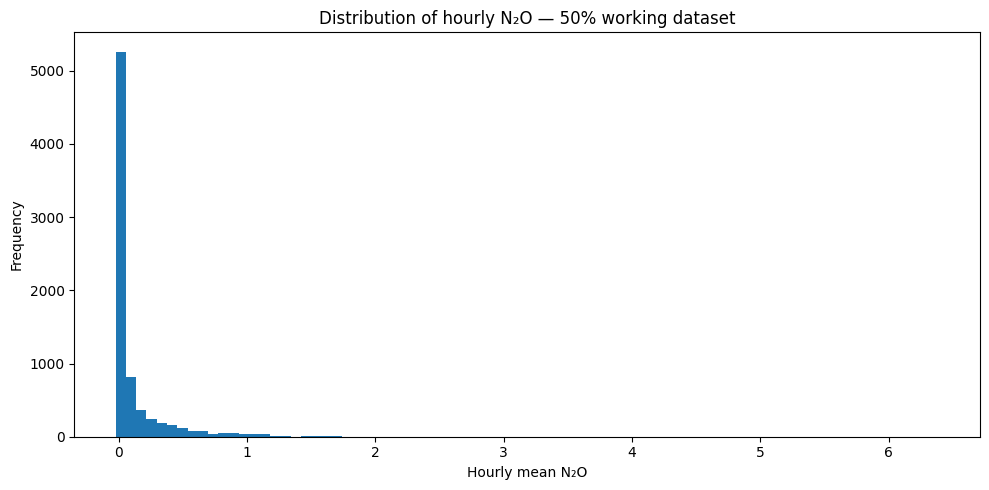

In [73]:
# Cell 11 — N2O distribution

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(n2o, bins=80)
ax.set_xlabel("Hourly mean N₂O")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of hourly N₂O — 50% working dataset")
plt.tight_layout()
plt.show()

In [74]:
# Cell 12 — Repeated lower-bound diagnostic

observed_min = n2o.min()

at_min = np.isclose(
    n2o,
    observed_min,
    rtol=0,
    atol=1e-10
)

floor_count = int(at_min.sum())

floor_diagnostic = pd.Series({
    "observed_minimum": observed_min,
    "hours_at_observed_minimum": floor_count,
    "percent_of_hourly_N2O": 100 * floor_count / len(n2o),
    "median": n2o.median(),
    "p01": n2o.quantile(.01),
    "p05": n2o.quantile(.05),
})

display(floor_diagnostic.to_frame("value"))

,value
observed_minimum,-0.02373
hours_at_observed_minimum,730.00000
percent_of_hourly_N2O,9.62934
median,0.01672
p01,-0.02373
p05,-0.02373


In [75]:
# Cell 13 — Temporal distribution of the repeated minimum

floor_hours = analysis.loc[
    np.isclose(
        analysis["t1_n2o"],
        observed_min,
        rtol=0,
        atol=1e-10
    ),
    ["hour_start", "t1_n2o", "t1_n2o_coverage"]
].copy()

floor_hours["month"] = floor_hours["hour_start"].dt.to_period("M").astype(str)

floor_monthly = (
    floor_hours.groupby("month")
    .size()
    .reset_index(name="hours_at_observed_minimum")
)

display(floor_monthly)

C:\Users\Dell\AppData\Local\Temp\ipykernel_4696\3447504948.py:13: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  floor_hours["month"] = floor_hours["hour_start"].dt.to_period("M").astype(str)


,month,hours_at_observed_minimum
0,2022-11,106
1,2022-12,244
2,2023-01,306
3,2023-02,31
4,2023-03,3
5,2023-04,4
6,2023-11,32
7,2023-12,4


In [76]:
# Cell 14 — Hour-of-day and day-of-week behaviour

temporal = analysis.copy()
temporal["hour_of_day"] = temporal["hour_start"].dt.hour
temporal["day_of_week"] = temporal["hour_start"].dt.day_name()

hour_pattern = (
    temporal.groupby("hour_of_day")["t1_n2o"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

day_pattern = (
    temporal.groupby("day_of_week")["t1_n2o"]
    .agg(["count", "mean", "median"])
    .reindex([
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ])
    .reset_index()
)

display(hour_pattern)
display(day_pattern)

,hour_of_day,count,mean,median
0,0,340,0.10524,0.01743
1,1,337,0.10847,0.01800
2,2,348,0.12504,0.02276
3,3,354,0.10893,0.01480
4,4,352,0.11168,0.01476
5,5,310,0.10458,0.01521
6,6,345,0.11001,0.01563
7,7,346,0.12064,0.02040
8,8,340,0.11896,0.02611
9,9,326,0.12090,0.02566


,day_of_week,count,mean,median
0,Monday,1078,0.17366,0.04420
1,Tuesday,1090,0.09868,0.01538
2,Wednesday,1096,0.06606,0.01071
3,Thursday,1099,0.06410,0.01177
4,Friday,1059,0.08393,0.00824
5,Saturday,1055,0.10701,0.01011
6,Sunday,1104,0.14441,0.03182


C:\Users\Dell\AppData\Local\Temp\ipykernel_4696\3316278400.py:4: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  temporal.assign(month=temporal["hour_start"].dt.to_period("M").astype(str))


,month,count,mean,median,std,adequate_for_visual_interpretation
0,2022-10,367,0.00326,-0.00394,0.02839,True
1,2022-11,505,0.01705,-0.02137,0.35782,True
2,2022-12,374,-0.02193,-0.02373,0.01013,True
3,2023-01,407,-0.02238,-0.02373,0.00389,True
4,2023-02,389,0.00213,-0.01373,0.04024,True
5,2023-03,373,0.16425,0.09383,0.17423,True
6,2023-04,642,0.51116,0.44891,0.39629,True
7,2023-05,216,0.38674,0.23180,0.41458,True
8,2023-06,10,0.16321,0.15687,0.10862,False
9,2023-07,337,0.28541,0.17388,0.32075,True


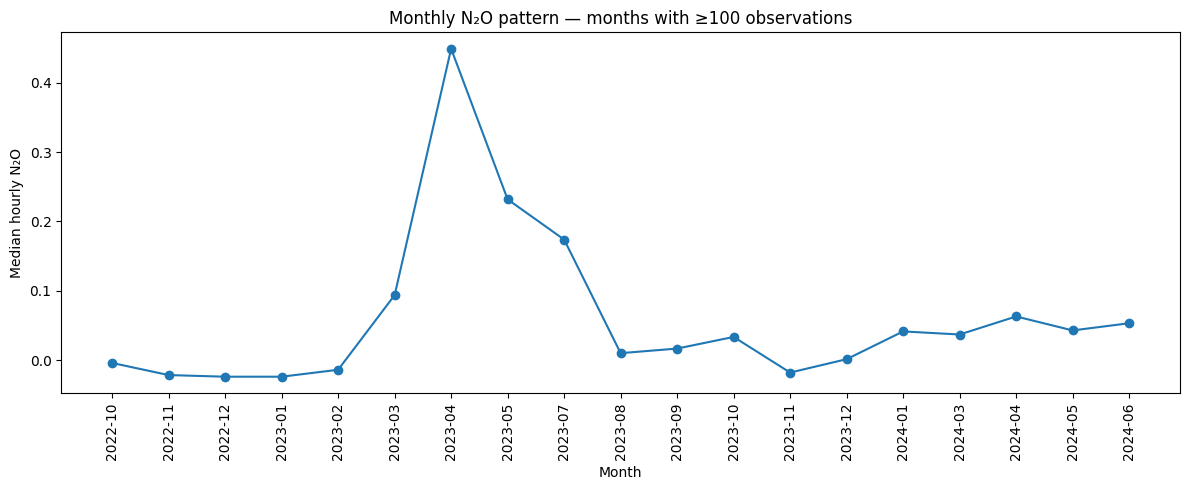

In [77]:
# Cell 15 — Monthly N2O pattern with observation adequacy flag

monthly = (
    temporal.assign(month=temporal["hour_start"].dt.to_period("M").astype(str))
    .groupby("month")["t1_n2o"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

# Visualization adequacy flag only; this is not a statistical significance threshold.
monthly["adequate_for_visual_interpretation"] = monthly["count"].ge(100)

display(monthly)

plot_monthly = monthly[monthly["adequate_for_visual_interpretation"]].copy()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(plot_monthly["month"], plot_monthly["median"], marker="o")
ax.set_xlabel("Month")
ax.set_ylabel("Median hourly N₂O")
ax.set_title("Monthly N₂O pattern — months with ≥100 observations")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

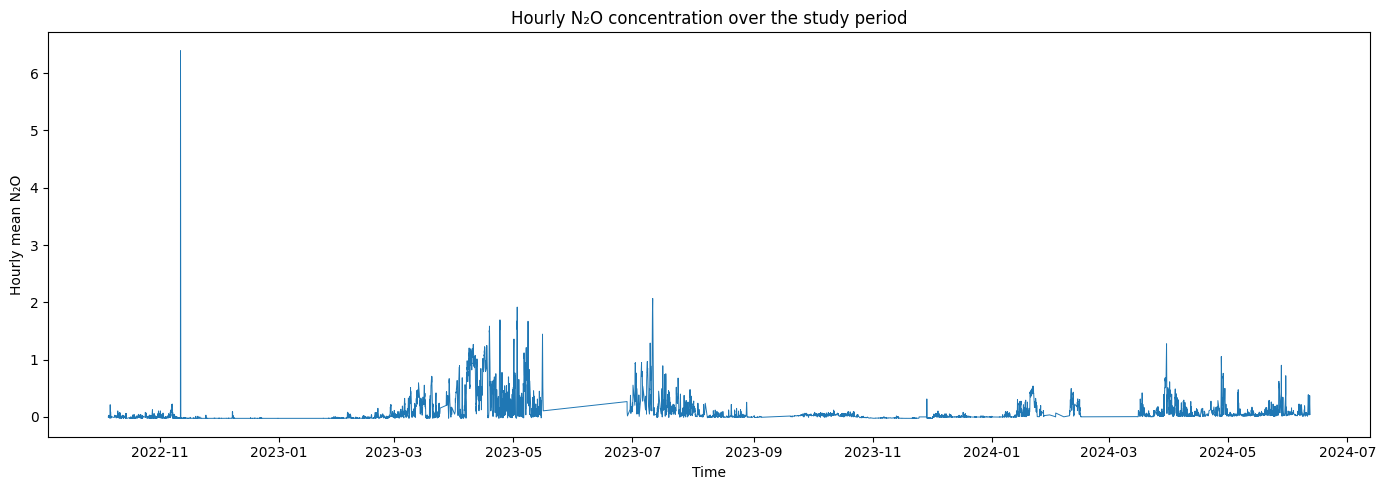

In [165]:
# Overall hourly N2O time series

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    temporal["hour_start"],
    temporal["t1_n2o"],
    linewidth=0.7
)

ax.set_xlabel("Time")
ax.set_ylabel("Hourly mean N₂O")
ax.set_title("Hourly N₂O concentration over the study period")

plt.tight_layout()

plt.savefig("../figures/n2o_timeseries.png", dpi=300, bbox_inches="tight")

plt.show()

In [166]:
# Cell 16 — One-hour N2O persistence

ordered = analysis.sort_values("hour_start").copy()

ordered["next_n2o"] = ordered["t1_n2o"].shift(-1)
ordered["next_hour"] = ordered["hour_start"].shift(-1)

pair_mask = (
    ordered["next_hour"].eq(
        ordered["hour_start"] + pd.Timedelta(hours=1)
    )
    & ordered["t1_n2o"].notna()
    & ordered["next_n2o"].notna()
)

pairs = ordered.loc[pair_mask, ["t1_n2o", "next_n2o"]]

persistence = pd.Series({
    "one_hour_pairs": len(pairs),
    "pearson_r": pairs["t1_n2o"].corr(pairs["next_n2o"], method="pearson"),
    "spearman_rho": pairs["t1_n2o"].corr(pairs["next_n2o"], method="spearman"),
})

display(persistence.to_frame("value"))

,value
one_hour_pairs,"5,885.00000"
pearson_r,0.90929
spearman_rho,0.90373


## Process-variable relationships


In [167]:
# Cell 17 — Candidate process-variable descriptive statistics

process_variables = [
    "t1_n2o",
    "t1_nh4",
    "t1_no3",
    "t1_do",
    "t1_do_setpoint",
    "t1_airflow_est",
    "t1_ss",
    "t1_temp",
    "inlet_flow",
]

missing_process_variables = [
    c for c in process_variables
    if c not in analysis.columns
]

if missing_process_variables:
    raise KeyError(f"Missing process variables: {missing_process_variables}")

process_summary = analysis[process_variables].describe(
    percentiles=[.25, .50, .75]
).T

process_summary["missing_pct"] = (
    analysis[process_variables].isna().mean() * 100
)

display(process_summary)

,count,mean,std,min,25%,50%,75%,max,missing_pct
t1_n2o,"7,581.00000",0.10537,0.24949,-0.02373,-0.01221,0.01672,0.08573,6.39174,0.00000
t1_nh4,"7,581.00000",2.30802,1.47466,0.00049,1.30241,2.10565,2.99966,19.99890,0.00000
t1_no3,"7,581.00000",3.02940,1.91929,0.00000,1.55012,2.60001,4.27730,15.71277,0.00000
t1_do,"7,581.00000",0.66323,0.32376,-0.02186,0.43499,0.62715,0.87744,4.41549,0.00000
t1_do_setpoint,"7,581.00000",0.65550,0.33548,0.00000,0.43780,0.60275,0.91682,2.50000,0.00000
t1_airflow_est,"7,581.00000","2,310.15203","1,202.13624",0.00000,"1,505.38443","2,227.18098","3,084.12608","6,348.81669",0.00000
t1_ss,"7,581.00000",2.86467,0.62214,1.40291,2.46427,2.71409,3.14222,5.09103,0.00000
t1_temp,"7,581.00000",14.70776,2.81491,8.51083,12.53786,13.83277,17.24606,21.22489,0.00000
inlet_flow,"7,581.00000","2,895.53566","1,517.18485",0.00000,"2,052.37267","2,503.93520","3,393.11349","9,733.51826",0.00000


In [168]:
# Cell 18 — Pearson and Spearman associations with current N2O

association_rows = []

for v in process_variables:
    if v == "t1_n2o":
        continue

    pair = analysis[["t1_n2o", v]].dropna()

    if len(pair) < 3:
        continue

    association_rows.append({
        "variable": v,
        "n_pairs": len(pair),
        "pearson_r": pair["t1_n2o"].corr(pair[v], method="pearson"),
        "spearman_rho": pair["t1_n2o"].corr(pair[v], method="spearman"),
    })

association = pd.DataFrame(association_rows)
association["abs_spearman"] = association["spearman_rho"].abs()
association = association.sort_values(
    "abs_spearman", ascending=False
).reset_index(drop=True)

display(association)

,variable,n_pairs,pearson_r,spearman_rho,abs_spearman
0,t1_ss,7581,-0.10701,-0.33791,0.33791
1,t1_do,7581,0.02267,0.08345,0.08345
2,t1_no3,7581,0.13583,0.04463,0.04463
3,t1_temp,7581,-0.06444,0.03498,0.03498
4,t1_nh4,7581,0.01882,-0.03360,0.03360
5,inlet_flow,7581,-0.06920,-0.02797,0.02797
6,t1_airflow_est,7581,-0.09401,-0.01503,0.01503
7,t1_do_setpoint,7581,-0.02982,-0.00421,0.00421


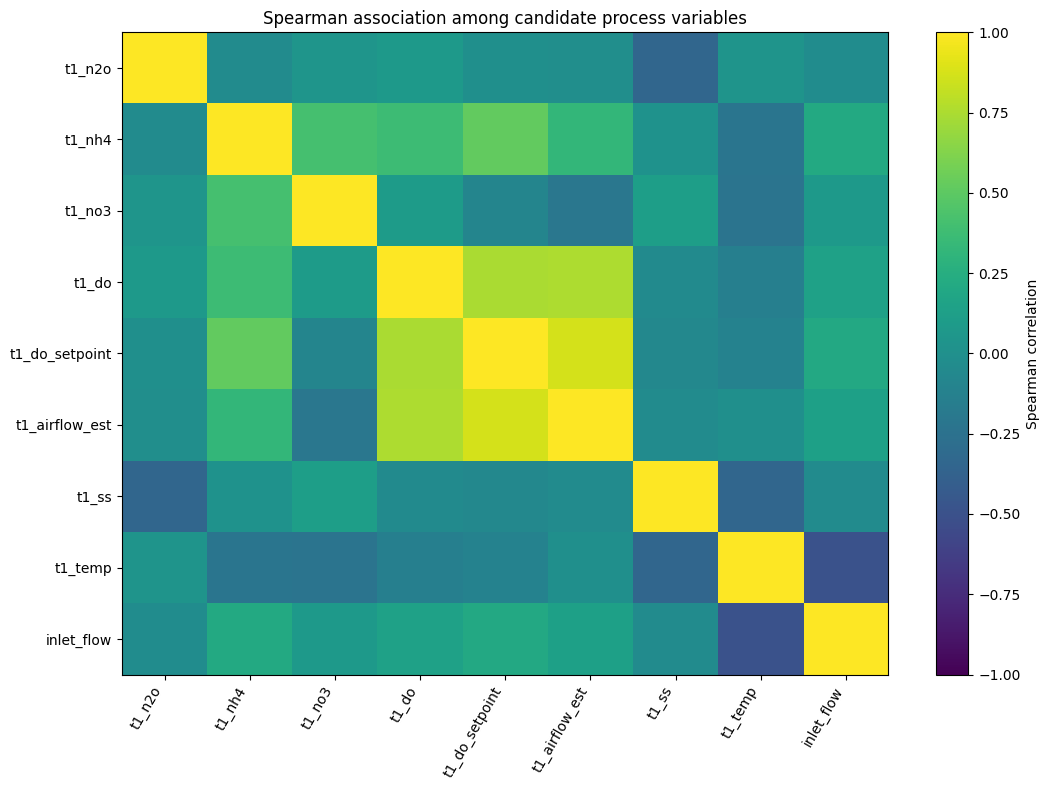

In [81]:
# Cell 19 — Spearman correlation heatmap

corr_cols = [v for v in process_variables if v in analysis.columns]
corr = analysis[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)

ax.set_title("Spearman association among candidate process variables")
fig.colorbar(im, ax=ax, label="Spearman correlation")

plt.tight_layout()
plt.show()

## Process-phase analysis

**Interpretation:** The phase comparison is an observational association between N₂O distributions on days dominated by the analyzed phases. Because the observations are temporally structured, the result should not be interpreted as a causal effect or as a strict independent-sample inference.


In [169]:
# Cell 20 — Phase representation diagnostic

phase_col = "t1_phase"

if phase_col not in analysis.columns:
    raise KeyError(f"{phase_col} is missing.")

phase_df = analysis[
    ["hour_start", phase_col, "t1_n2o"]
].dropna(subset=[phase_col])

phase_representation = (
    phase_df[phase_col]
    .value_counts()
    .sort_index()
    .rename("hours")
    .to_frame()
)

phase_representation["percent"] = (
    100 * phase_representation["hours"]
    / phase_representation["hours"].sum()
)

display(phase_representation)

print("\nPhase interpretation from dataset documentation:")
print("0 = anaerobic")
print("1 = anoxic / denitrification")
print("2 = aerobic / nitrification")

,hours,percent
t1_phase,,
0.00000,26,0.34296
1.00000,3194,42.13164
2.00000,4361,57.52539



Phase interpretation from dataset documentation:
0 = anaerobic
1 = anoxic / denitrification
2 = aerobic / nitrification


In [83]:
# Cell 21 — Dominant tank-1 phase by day

phase_daily_raw = phase_df.copy()
phase_daily_raw["date"] = phase_daily_raw["hour_start"].dt.date

daily_phase_counts = (
    phase_daily_raw
    .groupby(["date", phase_col])
    .size()
    .rename("hours")
    .reset_index()
)

daily_total = (
    daily_phase_counts
    .groupby("date")["hours"]
    .sum()
    .rename("total_phase_hours")
    .reset_index()
)

daily_phase_counts = daily_phase_counts.merge(
    daily_total,
    on="date",
    how="left"
)

daily_phase_counts["phase_share"] = (
    daily_phase_counts["hours"]
    / daily_phase_counts["total_phase_hours"]
)

dominant_phase = (
    daily_phase_counts
    .sort_values(
        ["date", "phase_share", "hours"],
        ascending=[True, False, False]
    )
    .drop_duplicates("date")
    .copy()
)

# Require at least 50% of phase-labelled hours to belong to the dominant phase.
dominant_phase = dominant_phase.loc[
    dominant_phase["phase_share"] >= 0.50
].copy()

dominant_phase["dominant_phase"] = dominant_phase[phase_col]

display(
    dominant_phase[
        ["date", "dominant_phase", "hours",
         "total_phase_hours", "phase_share"]
    ].head(20)
)

print("Dominant-phase days:", len(dominant_phase))

,date,dominant_phase,hours,total_phase_hours,phase_share
0,2022-10-05,1.00000,3,5,0.60000
3,2022-10-06,2.00000,11,15,0.73333
5,2022-10-07,2.00000,3,5,0.60000
7,2022-10-08,2.00000,3,4,0.75000
8,2022-10-09,1.00000,6,11,0.54545
11,2022-10-10,2.00000,7,11,0.63636
13,2022-10-11,2.00000,8,14,0.57143
14,2022-10-12,1.00000,14,24,0.58333
17,2022-10-13,2.00000,10,16,0.62500
19,2022-10-14,2.00000,7,13,0.53846


Dominant-phase days: 518


In [84]:
# Cell 22 — N2O during the dominant phase of each retained day

dominant_hour_data = phase_daily_raw.merge(
    dominant_phase[["date", "dominant_phase"]],
    on="date",
    how="inner"
)

dominant_hour_data = dominant_hour_data.loc[
    dominant_hour_data[phase_col].eq(
        dominant_hour_data["dominant_phase"]
    )
].copy()

daily_n2o = (
    dominant_hour_data
    .groupby(["date", "dominant_phase"])["t1_n2o"]
    .mean()
    .rename("daily_dominant_phase_n2o")
    .reset_index()
)

daily_phase_analysis = daily_n2o.merge(
    dominant_phase[
        ["date", "dominant_phase", "phase_share"]
    ],
    on=["date", "dominant_phase"],
    how="left"
)

display(
    daily_phase_analysis.groupby("dominant_phase")[
        "daily_dominant_phase_n2o"
    ].agg(["count", "mean", "median", "std"])
)

,count,mean,median,std
dominant_phase,,,,
1.00000,174,0.04416,0.00355,0.12733
2.00000,344,0.10933,0.03425,0.18881


In [85]:
# Cell 23 — Phase hypothesis test with representation checks

phase_groups = []

for phase_value, group in daily_phase_analysis.groupby("dominant_phase"):
    values = group["daily_dominant_phase_n2o"].dropna()

    if len(values) >= 10:
        phase_groups.append((phase_value, values))

phase_test_result = {
    "test": "Not run",
    "H": np.nan,
    "p_value": np.nan,
    "epsilon_squared": np.nan,
    "groups_used": 0,
}

if len(phase_groups) >= 2:
    arrays = [values.to_numpy() for _, values in phase_groups]

    H, p = stats.kruskal(*arrays)

    n_total = sum(len(a) for a in arrays)
    k = len(arrays)

    # Epsilon-squared effect-size estimate for Kruskal-Wallis.
    epsilon_sq = max(
        0,
        (H - k + 1) / (n_total - k)
    )

    phase_test_result = {
        "test": "Kruskal-Wallis",
        "H": H,
        "p_value": p,
        "epsilon_squared": epsilon_sq,
        "groups_used": k,
    }

phase_test = pd.Series(phase_test_result)
display(phase_test.to_frame("value"))

print(
    "\nInterpretation: this is an observational comparison of N2O "
    "during dominant-phase days; it does not establish causality."
)

,value
test,Kruskal-Wallis
H,31.77909
p_value,0.00000
epsilon_squared,0.05965
groups_used,2



Interpretation: this is an observational comparison of N2O during dominant-phase days; it does not establish causality.


## Stage 3 findings and decision

The findings below are generated from the diagnostics rather than manually hard-coded. They are intended to guide Stage 4 feature engineering, not to claim causal mechanisms.


In [86]:
# Cell 24 — Stage 3 findings summary

strongest_association = None
if not association.empty:
    strongest = association.iloc[0]
    strongest_association = {
        "variable": strongest["variable"],
        "spearman_rho": strongest["spearman_rho"],
    }

findings = {
    "working_coverage_threshold": WORKING_THRESHOLD,
    "working_rows": len(analysis),
    "forecast_ready_rows": len(forecast_ready_analysis),
    "n2o_mean": n2o.mean(),
    "n2o_median": n2o.median(),
    "n2o_skewness": stats.skew(n2o, bias=False),
    "one_hour_persistence_spearman": persistence["spearman_rho"],
    "strongest_same_hour_spearman_variable": (
        strongest_association["variable"]
        if strongest_association else None
    ),
    "strongest_same_hour_spearman": (
        strongest_association["spearman_rho"]
        if strongest_association else np.nan
    ),
    "n2o_observed_minimum": observed_min,
    "percent_at_observed_minimum": (
        100 * floor_count / len(n2o)
    ),
    "phase_groups_used": phase_test["groups_used"],
    "phase_test": phase_test["test"],
    "phase_p_value": phase_test["p_value"],
    "phase_epsilon_squared": phase_test["epsilon_squared"],
}

display(pd.Series(findings).to_frame("value"))

,value
working_coverage_threshold,0.50000
working_rows,7581
forecast_ready_rows,7510
n2o_mean,0.10537
n2o_median,0.01672
n2o_skewness,5.58384
one_hour_persistence_spearman,0.90373
strongest_same_hour_spearman_variable,t1_ss
strongest_same_hour_spearman,-0.33791
n2o_observed_minimum,-0.02373


In [87]:
# Cell 25 — Stage 3 validation gate

validation = {
    "hourly dataset exists": len(hourly) > 0,
    "analysis dataset exists": len(analysis) > 0,
    "forecast-ready dataset exists": len(forecast_ready_analysis) > 0,
    "exact t+1 construction used": "exact_next_hour" in hourly.columns,
    "coverage scenarios evaluated": len(scenario_summary) == 4,
    "coverage representativeness evaluated": len(coverage_representativeness) == 4,
    "monthly retention evaluated": len(monthly_retention) > 0,
    "N2O lower-bound diagnostic completed": isinstance(floor_diagnostic, pd.Series),
    "persistence evaluated": len(pairs) > 0,
    "process association evaluated": len(association) > 0,
    "phase representation evaluated": len(phase_representation) > 0,
    "phase comparison completed": phase_test["groups_used"] >= 2,
}

for check, result in validation.items():
    print(f"{check}: {result}")

print("\n" + "=" * 60)

if all(validation.values()):
    print("STAGE 3 VALIDATION GATE: PASS")
    print("Statistical analysis and EDA are complete.")
    print("Proceed to Stage 4 only after reviewing the diagnostics above.")
else:
    print("STAGE 3 VALIDATION GATE: REVIEW REQUIRED")

print("=" * 60)

hourly dataset exists: True
analysis dataset exists: True
forecast-ready dataset exists: True
exact t+1 construction used: True
coverage scenarios evaluated: True
coverage representativeness evaluated: True
monthly retention evaluated: True
N2O lower-bound diagnostic completed: True
persistence evaluated: True
process association evaluated: True
phase representation evaluated: True
phase comparison completed: True

STAGE 3 VALIDATION GATE: PASS
Statistical analysis and EDA are complete.
Proceed to Stage 4 only after reviewing the diagnostics above.


# Stage 3 — Frozen decisions before Stage 4

The Stage 3 diagnostics support the following decisions for the modelling pipeline:

1. **Working coverage rule:** A 50% minimum hourly coverage threshold is used for the primary modelling population.
2. **N₂O lower-bound behaviour:** Repeated lower-bound observations are retained because they passed the dataset quality rule and were not independently established as invalid.
3. **Temporal structure:** Strong one-hour N₂O persistence supports inclusion of persistence as the required baseline.
4. **Process associations:** Same-hour relationships are interpreted as exploratory predictive associations, not causal effects.
5. **Phase interpretation:** Phase comparisons are observational; sparse anaerobic observations are not treated as a reliable standalone inferential group.
6. **Forecasting setup:** Features use only information available at or before forecast time *t*, with N₂O at *t+1* as the target.

### Stage 4 direction

**Current N₂O + lagged N₂O + current/lagged process measurements + process-state/context → N₂O at t+1**

All feature construction is checked explicitly for future leakage.

# 6. Feature Engineering and Leakage Prevention


## Feature-design principle

The modelling row represents forecast time **t**. Therefore:

**Allowed:**
- current measurements at *t*
- measurements from *t−1h*, *t−2h*, etc.
- backward-looking summaries built only from *t* and earlier
- calendar/process-state information known at *t*

**Not allowed:**
- N₂O at *t+1* or any future process measurement
- forward-filled future observations
- centered rolling windows
- random train/test splitting
- transformations fitted using validation/test data

The target `n2o_t_plus_1` is kept in the dataframe for evaluation, but it is explicitly excluded from the feature matrix.


In [88]:
# Cell 1 — Imports and configuration

import numpy as np
import pandas as pd

from pathlib import Path

pd.set_option("display.max_columns", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

RAW_PATH = "../data/raw/aved_raw.csv"
STAGE2B_PATH = "../data/processed/stage_2B_hourly_coverage.csv"
WORKING_THRESHOLD = 0.50
STAGE2B_TIMEZONE = "Asia/Kolkata"
PLANT_TIMEZONE = "Europe/Copenhagen"

print("Stage 4 imports/configuration: PASS")

Stage 4 imports/configuration: PASS


In [89]:
# Cell 2 — Load raw data and Stage 2B coverage table

raw = pd.read_csv(RAW_PATH)
coverage_table = pd.read_csv(STAGE2B_PATH)

# Reuse the fixed +05:30 convention from the frozen Stage 2B export.
# This is a hand-off compatibility convention, not the plant's physical timezone.
raw["time"] = pd.to_datetime(raw["time"], utc=True).dt.tz_convert(STAGE2B_TIMEZONE)
coverage_table["hour_start"] = pd.to_datetime(
    coverage_table["hour_start"], utc=True
).dt.tz_convert(STAGE2B_TIMEZONE)

print("Raw shape:", raw.shape)
print("Stage 2B shape:", coverage_table.shape)
print("Raw time range:", raw["time"].min(), "to", raw["time"].max())
print("Stage 2B hour range:", coverage_table["hour_start"].min(), "to", coverage_table["hour_start"].max())


Raw shape: (906815, 49)
Stage 2B shape: (17545, 50)
Raw time range: 2022-06-12 03:31:00+05:30 to 2024-06-12 03:29:00+05:30
Stage 2B hour range: 2022-06-12 03:00:00+05:30 to 2024-06-12 03:00:00+05:30


In [90]:
# Cell 3 — Reconstruct the validated Stage 3 hourly table

# This is intentionally the same quality-aware aggregation logic used in Stage 3.
column_map = {
    "t1_n2o": ("BIOLOGY.LINE 3 TANK 1.N2O value", "BIOLOGY.LINE 3 TANK 1.N2O quality"),
    "t1_nh4": ("BIOLOGY.LINE 3 TANK 1.NH4 value", "BIOLOGY.LINE 3 TANK 1.NH4 quality"),
    "t1_no3": ("BIOLOGY.LINE 3 TANK 1.NO3 value", "BIOLOGY.LINE 3 TANK 1.NO3 quality"),
    "t1_do": ("BIOLOGY.LINE 3 TANK 1.O2 value", "BIOLOGY.LINE 3 TANK 1.O2 quality"),
    "t1_do_setpoint": ("BIOLOGY.LINE 3 TANK 1.O2.SETPOINT value", "BIOLOGY.LINE 3 TANK 1.O2.SETPOINT quality"),
    "t1_phase": ("BIOLOGY.LINE 3 TANK 1.PROCESSPHASE value", "BIOLOGY.LINE 3 TANK 1.PROCESSPHASE quality"),
    "t1_airflow_est": ("BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW value", "BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW quality"),
    "t1_ss": ("BIOLOGY.LINE 3 TANK 1.SS value", "BIOLOGY.LINE 3 TANK 1.SS quality"),
    "t1_temp": ("BIOLOGY.LINE 3 TANK 1.TEMPERATURE value", "BIOLOGY.LINE 3 TANK 1.TEMPERATURE quality"),
    "inlet_flow": ("INLET.Q value", "INLET.Q quality"),
    "stormwater_mode": ("INLET.STATE.SWM INLET FLOW value", "INLET.STATE.SWM INLET FLOW quality"),
    "inlet_tank": ("BIOLOGY.LINE 3.PROCESSPHASE.INLET TANK value", "BIOLOGY.LINE 3.PROCESSPHASE.INLET TANK quality"),
    "outlet_tank": ("BIOLOGY.LINE 3.PROCESSPHASE.OUTLET TANK value", "BIOLOGY.LINE 3.PROCESSPHASE.OUTLET TANK quality"),
}

required_raw = [x for pair in column_map.values() for x in pair]
missing_raw = [c for c in required_raw if c not in raw.columns]
if missing_raw:
    raise KeyError(f"Missing raw columns: {missing_raw}")

# Fixed +05:30 Stage 2B convention is DST-safe.
raw_hourly = pd.DataFrame({
    "hour_start": raw["time"].dt.floor("h")
})

for name, (value_col, quality_col) in column_map.items():
    value = pd.to_numeric(raw[value_col], errors="coerce")
    quality = pd.to_numeric(raw[quality_col], errors="coerce")
    valid = value.where(quality.eq(0))

    if name in {"t1_phase", "stormwater_mode", "inlet_tank", "outlet_tank"}:
        agg = valid.groupby(raw_hourly["hour_start"]).agg(
            lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan
        )
    else:
        agg = valid.groupby(raw_hourly["hour_start"]).mean()

    raw_hourly[name] = raw_hourly["hour_start"].map(agg)

for name, (value_col, quality_col) in column_map.items():
    value = pd.to_numeric(raw[value_col], errors="coerce")
    quality = pd.to_numeric(raw[quality_col], errors="coerce")
    valid = value.where(quality.eq(0))
    count = valid.groupby(raw_hourly["hour_start"]).count()
    raw_hourly[f"{name}_valid_count"] = raw_hourly["hour_start"].map(count)

raw_hourly = (
    raw_hourly.drop_duplicates("hour_start")
    .sort_values("hour_start")
    .reset_index(drop=True)
)

print("Reconstructed hourly rows:", len(raw_hourly))

Reconstructed hourly rows: 17545


In [91]:
# Cell 4 — Stage 2 → Stage 4 handoff validation

checks = {}
checks["no null hours"] = raw_hourly["hour_start"].notna().all()
checks["no duplicate hours"] = not raw_hourly["hour_start"].duplicated().any()

merged = coverage_table[["hour_start", "t1_n2o_valid_count", "raw_observed_rows"]].merge(
    raw_hourly[["hour_start", "t1_n2o_valid_count"]],
    on="hour_start", how="inner", suffixes=("_stage2", "_reconstructed")
)

checks["all Stage 2B hours overlap"] = (
    len(merged) == len(coverage_table) == len(raw_hourly)
)
checks["N2O valid counts match"] = (
    merged["t1_n2o_valid_count_stage2"].fillna(-1).equals(
        merged["t1_n2o_valid_count_reconstructed"].fillna(-1)
    )
)

reconstructed_cov = (
    merged["t1_n2o_valid_count_reconstructed"] / merged["raw_observed_rows"]
)
stage2_cov = coverage_table.set_index("hour_start").loc[merged["hour_start"], "t1_n2o_coverage"].reset_index(drop=True)
checks["N2O coverage matches"] = np.allclose(
    reconstructed_cov.fillna(-1), stage2_cov.fillna(-1), atol=1e-10
)

for k, v in checks.items():
    print(f"{k}: {v}")

if not all(checks.values()):
    raise AssertionError("Stage 2 → Stage 4 handoff failed.")

print("\nStage 2 → Stage 4 handoff: PASS")

no null hours: True
no duplicate hours: True
all Stage 2B hours overlap: True
N2O valid counts match: True
N2O coverage matches: True

Stage 2 → Stage 4 handoff: PASS


In [92]:
# Cell 5 — Build exact one-hour-ahead target

hourly = raw_hourly.copy().sort_values("hour_start").reset_index(drop=True)

coverage_cols = [c for c in coverage_table.columns if c.endswith("_coverage")]
coverage_subset = coverage_table[["hour_start"] + coverage_cols].drop_duplicates("hour_start")

hourly = hourly.merge(
    coverage_subset, on="hour_start", how="left", suffixes=("", "_stage2")
)

hourly["target_hour"] = hourly["hour_start"] + pd.Timedelta(hours=1)
next_existing_hour = hourly["hour_start"].shift(-1)
hourly["exact_next_hour"] = next_existing_hour.eq(hourly["target_hour"])

hourly["n2o_t_plus_1"] = hourly["t1_n2o"].shift(-1)
hourly["n2o_t_plus_1_coverage"] = hourly["t1_n2o_coverage"].shift(-1)

hourly.loc[~hourly["exact_next_hour"], ["n2o_t_plus_1", "n2o_t_plus_1_coverage"]] = np.nan

print("Hourly rows:", len(hourly))
print("Exact t+1 rows:", int(hourly["exact_next_hour"].sum()))
print("Usable exact t+1 N2O targets:", int(hourly["n2o_t_plus_1"].notna().sum()))

Hourly rows: 17545
Exact t+1 rows: 17544
Usable exact t+1 N2O targets: 15125


In [93]:
# Cell 6 — Recreate the Stage 3 50% forecast-ready dataset

candidate_variables = [
    "t1_n2o", "t1_nh4", "t1_no3", "t1_do", "t1_do_setpoint",
    "t1_airflow_est", "t1_ss", "t1_temp", "inlet_flow"
]
required_coverage_columns = [f"{v}_coverage" for v in candidate_variables]

coverage_ok = hourly[required_coverage_columns].ge(WORKING_THRESHOLD).all(axis=1)
analysis = (
    hourly.loc[coverage_ok]
    .copy().sort_values("hour_start").reset_index(drop=True)
)

forecast_ready_analysis = analysis.loc[
    analysis["exact_next_hour"]
    & analysis["n2o_t_plus_1"].notna()
    & analysis["n2o_t_plus_1_coverage"].ge(WORKING_THRESHOLD)
].copy()

print("Working threshold:", WORKING_THRESHOLD)
print("Current-state analysis rows:", len(analysis))
print("Forecast-ready rows:", len(forecast_ready_analysis))
print("Forecast-ready period:", forecast_ready_analysis["hour_start"].min(), "to", forecast_ready_analysis["hour_start"].max())

if len(forecast_ready_analysis) != 7510:
    raise AssertionError(
        f"Stage 3 reproducibility check failed: expected 7510 forecast-ready rows, got {len(forecast_ready_analysis)}."
    )

print("Stage 3 50% forecast-ready row count: PASS")

Working threshold: 0.5
Current-state analysis rows: 7581
Forecast-ready rows: 7510
Forecast-ready period: 2022-10-05 14:00:00+05:30 to 2024-06-12 00:00:00+05:30
Stage 3 50% forecast-ready row count: PASS


## 1. Define the primary modelling population

The primary operational scenario explicitly assumes that current N₂O is available at forecast time. Therefore, rows with missing current N₂O are not suitable for the **primary** model, even though they may satisfy the broader 50% hourly coverage rule.

Other process measurements are allowed to remain missing because Stage 5 will handle missing predictors in a model-specific, training-only pipeline. We do **not** fill them here.


In [94]:
# Cell 7 — Primary forecasting population

primary = forecast_ready_analysis.loc[
    forecast_ready_analysis["t1_n2o"].notna()
].copy().sort_values("hour_start").reset_index(drop=True)

print("Primary modelling rows:", len(primary))
print("Current N2O missing after primary filter:", int(primary["t1_n2o"].isna().sum()))
print("Target missing:", int(primary["n2o_t_plus_1"].isna().sum()))

if primary.empty:
    raise AssertionError("Primary forecasting population is empty.")
if primary["t1_n2o"].isna().any():
    raise AssertionError("Primary scenario requires current N2O, but missing values remain.")
if primary["n2o_t_plus_1"].isna().any():
    raise AssertionError("Primary scenario contains missing t+1 targets.")

print("Primary population definition: PASS")

Primary modelling rows: 7510
Current N2O missing after primary filter: 0
Target missing: 0
Primary population definition: PASS


## 2. Exact lag engineering

Lag features are created by **timestamp-based exact joins**, not by blindly using `shift()`. This matters because the hourly dataset contains gaps.

For a row at time *t*:
- `n2o_lag_1h` comes from exactly *t−1h*
- `n2o_lag_2h` comes from exactly *t−2h*
- etc.

If the exact historical hour is unavailable, the lag remains `NaN`. It is never forward-filled or replaced by a value from a nearby but incorrect time.


In [95]:
# Cell 8 — Helper for exact timestamp lags

def add_exact_lag(df, source_df, column, lag_hours, new_name):
    source = source_df[["hour_start", column]].copy()
    source["hour_start"] = source["hour_start"] + pd.Timedelta(hours=lag_hours)
    source = source.rename(columns={column: new_name})
    return df.merge(source, on="hour_start", how="left", validate="one_to_one")

print("Exact-lag helper defined: PASS")

Exact-lag helper defined: PASS


In [96]:
# Cell 9 — Create N2O and process-variable lags

# Use the 50%-coverage analysis table as the historical source.
# This prevents a lag from silently pulling a low-coverage hour excluded by the working rule.
lag_source = analysis[["hour_start"] + candidate_variables].copy()

features = primary[["hour_start"]].copy()

# N2O history: multiple horizons are useful for short-memory dynamics.
for lag in [1, 2, 3, 6, 24]:
    features = add_exact_lag(
        features, lag_source, "t1_n2o", lag, f"n2o_lag_{lag}h"
    )

# One-hour process lags: capture recent process state without creating a large feature set.
process_lag_variables = [
    "t1_nh4", "t1_no3", "t1_do", "t1_do_setpoint",
    "t1_airflow_est", "t1_ss", "t1_temp", "inlet_flow"
]

for variable in process_lag_variables:
    features = add_exact_lag(
        features, lag_source, variable, 1, f"{variable}_lag_1h"
    )

print("Lag feature columns:", len(features.columns) - 1)
print(features.head())

Lag feature columns: 13
                 hour_start  n2o_lag_1h  n2o_lag_2h  n2o_lag_3h  n2o_lag_6h  n2o_lag_24h  t1_nh4_lag_1h  t1_no3_lag_1h  t1_do_lag_1h  t1_do_setpoint_lag_1h  \
0 2022-10-05 14:00:00+05:30         NaN         NaN         NaN         NaN          NaN            NaN            NaN           NaN                    NaN   
1 2022-10-05 16:00:00+05:30         NaN    -0.00000         NaN         NaN          NaN            NaN            NaN           NaN                    NaN   
2 2022-10-05 18:00:00+05:30         NaN    -0.00874         NaN         NaN          NaN            NaN            NaN           NaN                    NaN   
3 2022-10-05 20:00:00+05:30         NaN    -0.00723         NaN    -0.00000          NaN            NaN            NaN           NaN                    NaN   
4 2022-10-05 21:00:00+05:30     0.00571         NaN    -0.00723         NaN          NaN        1.73011        1.81820       0.58677                0.46667   

   t1_airflow_est_lag

In [97]:
# Cell 10 — Add current process measurements

current_variables = [
    "t1_n2o", "t1_nh4", "t1_no3", "t1_do", "t1_do_setpoint",
    "t1_airflow_est", "t1_ss", "t1_temp", "inlet_flow"
]

current = primary[["hour_start"] + current_variables].copy()
features = features.merge(current, on="hour_start", how="left", validate="one_to_one")

print("Current process features added: PASS")
print("Feature table shape:", features.shape)

Current process features added: PASS
Feature table shape: (7510, 23)


## 3. Process-state and calendar context

These variables are known at time *t* and do not depend on the future target.

- Tank-1 process phase is represented using one-hot indicators rather than treating 0/1/2 as a continuous numeric scale.
- Stormwater mode is retained as a binary/process-state indicator when available.
- Inlet/outlet tank states are represented as categorical indicators.
- Hour-of-day and day-of-week use cyclic encodings so that 23:00 and 00:00 remain close in feature space.

These are **context features**, not causal claims.


In [98]:
# Cell 11 — Add process-state and time-context features

context = primary[[
    "hour_start", "t1_phase", "stormwater_mode", "inlet_tank", "outlet_tank"
]].copy()

# One-hot encode process-state categories with explicit numeric indicators.
phase_dummies = pd.get_dummies(
    context["t1_phase"], prefix="phase", dtype=float
)
context = pd.concat([context[["hour_start", "stormwater_mode", "inlet_tank", "outlet_tank"]], phase_dummies], axis=1)

for col in ["inlet_tank", "outlet_tank"]:
    dummies = pd.get_dummies(context[col], prefix=col, dtype=float)
    context = pd.concat([context.drop(columns=[col]), dummies], axis=1)

# Stormwater mode is treated as a state indicator; preserve NaN if unavailable.
if "stormwater_mode" in context.columns:
    context["stormwater_mode"] = pd.to_numeric(context["stormwater_mode"], errors="coerce")

# Cyclic time-of-day and day-of-week context.
hour_of_day = context["hour_start"].dt.hour
day_of_week = context["hour_start"].dt.dayofweek
context["hour_sin"] = np.sin(2 * np.pi * hour_of_day / 24)
context["hour_cos"] = np.cos(2 * np.pi * hour_of_day / 24)
context["dow_sin"] = np.sin(2 * np.pi * day_of_week / 7)
context["dow_cos"] = np.cos(2 * np.pi * day_of_week / 7)

features = features.merge(context, on="hour_start", how="left", validate="one_to_one")

print("Context features added: PASS")
print("Context columns:", [c for c in context.columns if c != "hour_start"])

Context features added: PASS
Context columns: ['stormwater_mode', 'phase_0.0', 'phase_1.0', 'phase_2.0', 'inlet_tank_0.0', 'inlet_tank_1.0', 'inlet_tank_2.0', 'outlet_tank_0.0', 'outlet_tank_1.0', 'outlet_tank_2.0', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos']


In [99]:
# Cell 12 — Add backward-looking N2O summary from exact lags

# This summary uses only already-available N2O lags. It does not inspect t+1 or later.
n2o_lag_cols = ["n2o_lag_1h", "n2o_lag_2h", "n2o_lag_3h"]
features["n2o_recent_mean_3h"] = features[n2o_lag_cols].mean(axis=1, skipna=False)
features["n2o_recent_std_3h"] = features[n2o_lag_cols].std(axis=1, skipna=False)

print("Backward-looking N2O summaries added: PASS")

Backward-looking N2O summaries added: PASS


## 4. Assemble the final Stage 4 modelling table

The final table contains:

**Target**
- `n2o_t_plus_1`

**Current state**
- current N₂O and current process variables

**Recent history**
- exact N₂O lags
- one-hour process lags
- backward-looking N₂O summaries

**Context**
- process-state indicators
- cyclic calendar features

Quality-coverage columns, target-hour columns, and other future-looking bookkeeping columns are deliberately excluded from the feature matrix.


In [100]:
# Cell 13 — Assemble target + features and define the feature list

model_table = primary[["hour_start", "n2o_t_plus_1"]].merge(
    features, on="hour_start", how="left", validate="one_to_one"
)

# Explicit feature list: this is the boundary that prevents accidental leakage.
feature_exclude = {"hour_start"}
feature_columns = [c for c in features.columns if c not in feature_exclude]

# Sanity checks.
if "n2o_t_plus_1" in feature_columns:
    raise AssertionError("Target leaked into feature list.")

print("Modelling table shape:", model_table.shape)
print("Number of candidate features:", len(feature_columns))
print("Target column:", "n2o_t_plus_1")
print("\nFeature columns:")
for c in feature_columns:
    print(" -", c)

Modelling table shape: (7510, 40)
Number of candidate features: 38
Target column: n2o_t_plus_1

Feature columns:
 - n2o_lag_1h
 - n2o_lag_2h
 - n2o_lag_3h
 - n2o_lag_6h
 - n2o_lag_24h
 - t1_nh4_lag_1h
 - t1_no3_lag_1h
 - t1_do_lag_1h
 - t1_do_setpoint_lag_1h
 - t1_airflow_est_lag_1h
 - t1_ss_lag_1h
 - t1_temp_lag_1h
 - inlet_flow_lag_1h
 - t1_n2o
 - t1_nh4
 - t1_no3
 - t1_do
 - t1_do_setpoint
 - t1_airflow_est
 - t1_ss
 - t1_temp
 - inlet_flow
 - stormwater_mode
 - phase_0.0
 - phase_1.0
 - phase_2.0
 - inlet_tank_0.0
 - inlet_tank_1.0
 - inlet_tank_2.0
 - outlet_tank_0.0
 - outlet_tank_1.0
 - outlet_tank_2.0
 - hour_sin
 - hour_cos
 - dow_sin
 - dow_cos
 - n2o_recent_mean_3h
 - n2o_recent_std_3h


In [101]:
# Cell 14 — Missingness profile of engineered features

feature_missingness = (
    model_table[feature_columns]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("missing_pct")
    .to_frame()
)

feature_missingness["non_missing_pct"] = 100 - feature_missingness["missing_pct"]
display(feature_missingness)

print("\nImportant: missing values are intentionally preserved.")
print("Stage 5 will handle imputation/model compatibility inside training-only pipelines where required.")

,missing_pct,non_missing_pct
n2o_recent_std_3h,45.44607,54.55393
n2o_recent_mean_3h,45.44607,54.55393
n2o_lag_24h,29.97337,70.02663
n2o_lag_6h,29.06791,70.93209
n2o_lag_2h,26.55126,73.44874
n2o_lag_3h,25.52597,74.47403
t1_nh4_lag_1h,22.29028,77.70972
n2o_lag_1h,22.29028,77.70972
t1_no3_lag_1h,22.29028,77.70972
t1_do_lag_1h,22.29028,77.70972



Important: missing values are intentionally preserved.
Stage 5 will handle imputation/model compatibility inside training-only pipelines where required.


In [102]:
# Cell 15 — Lag availability diagnostic

lag_cols = [c for c in feature_columns if "lag_" in c]
lag_availability = pd.DataFrame({
    "feature": lag_cols,
    "available_rows": [model_table[c].notna().sum() for c in lag_cols],
    "availability_pct": [100 * model_table[c].notna().mean() for c in lag_cols],
})

display(lag_availability.sort_values("availability_pct"))

,feature,available_rows,availability_pct
4,n2o_lag_24h,5259,70.02663
3,n2o_lag_6h,5327,70.93209
1,n2o_lag_2h,5516,73.44874
2,n2o_lag_3h,5593,74.47403
0,n2o_lag_1h,5836,77.70972
5,t1_nh4_lag_1h,5836,77.70972
6,t1_no3_lag_1h,5836,77.70972
7,t1_do_lag_1h,5836,77.70972
8,t1_do_setpoint_lag_1h,5836,77.70972
9,t1_airflow_est_lag_1h,5836,77.70972


## 5. Leakage audit

The audit checks four separate risks:

1. **Direct target leakage:** target or target-derived columns appearing in features.
2. **Future timestamp leakage:** feature values whose source timestamp is later than the forecast time.
3. **Forward-looking rolling leakage:** no centered/future windows are used.
4. **Data-selection leakage:** no random split or test-derived transformation is performed here.

A model can still be wrong if a future variable is accidentally merged under an innocuous name, so the timestamp audit is explicit.


In [103]:
# Cell 16 — Explicit leakage audit

# Direct target/future-name screening.
suspicious_names = [
    c for c in feature_columns
    if any(token in c.lower() for token in ["t_plus_1", "target", "future", "next_hour"])
]

# Bookkeeping columns that must never enter the model.
forbidden_feature_tokens = [
    "coverage", "valid_count", "target_hour", "exact_next_hour", "n2o_t_plus_1"
]
forbidden_present = [
    c for c in feature_columns
    if any(token in c.lower() for token in forbidden_feature_tokens)
]

leakage_checks = {
    "target absent from feature list": "n2o_t_plus_1" not in feature_columns,
    "no future/target-named feature": len(suspicious_names) == 0,
    "no coverage/bookkeeping feature": len(forbidden_present) == 0,
    "no centered rolling features": not any("center" in c.lower() for c in feature_columns),
}

print("Potentially suspicious feature names:", suspicious_names)
print("Forbidden bookkeeping features found:", forbidden_present)

for k, v in leakage_checks.items():
    print(f"{k}: {v}")

if not all(leakage_checks.values()):
    raise AssertionError("Leakage audit failed.")

print("\nDirect leakage audit: PASS")

Potentially suspicious feature names: []
Forbidden bookkeeping features found: []
target absent from feature list: True
no future/target-named feature: True
no coverage/bookkeeping feature: True
no centered rolling features: True

Direct leakage audit: PASS


In [104]:
# Cell 17 — Timestamp-source audit for lag features

# Exact lag construction guarantees source_time = forecast_time - lag.
# Reconstruct this relationship explicitly for every lag horizon.
lag_timestamp_checks = []
for lag in [1, 2, 3, 6, 24]:
    lag_timestamp_checks.append({
        "feature": f"n2o_lag_{lag}h",
        "source_time_relation": f"t - {lag} hour",
        "future_information": False,
    })

for variable in process_lag_variables:
    lag_timestamp_checks.append({
        "feature": f"{variable}_lag_1h",
        "source_time_relation": "t - 1 hour",
        "future_information": False,
    })

lag_audit = pd.DataFrame(lag_timestamp_checks)
display(lag_audit)

if lag_audit["future_information"].any():
    raise AssertionError("A lag feature is marked as using future information.")

print("Lag timestamp audit: PASS")

,feature,source_time_relation,future_information
0,n2o_lag_1h,t - 1 hour,False
1,n2o_lag_2h,t - 2 hour,False
2,n2o_lag_3h,t - 3 hour,False
3,n2o_lag_6h,t - 6 hour,False
4,n2o_lag_24h,t - 24 hour,False
5,t1_nh4_lag_1h,t - 1 hour,False
6,t1_no3_lag_1h,t - 1 hour,False
7,t1_do_lag_1h,t - 1 hour,False
8,t1_do_setpoint_lag_1h,t - 1 hour,False
9,t1_airflow_est_lag_1h,t - 1 hour,False


Lag timestamp audit: PASS


In [105]:
# Cell 18 — Check target alignment on a random-looking sample of chronological rows

# This is not a train/test sample. It is only a deterministic diagnostic of the target relationship.
check_rows = model_table[["hour_start", "n2o_t_plus_1"]].iloc[::max(1, len(model_table)//10)].copy()
expected_target_hour = check_rows["hour_start"] + pd.Timedelta(hours=1)

reference = primary[["hour_start", "n2o_t_plus_1"]].copy()
reference["target_hour_expected"] = reference["hour_start"] + pd.Timedelta(hours=1)

check_rows = check_rows.merge(
    reference[["hour_start", "target_hour_expected"]],
    on="hour_start", how="left", validate="one_to_one"
)

check_rows["target_hour_matches"] = check_rows["target_hour_expected"].eq(
    check_rows["hour_start"] + pd.Timedelta(hours=1)
)

display(check_rows.head(10))

if not check_rows["target_hour_matches"].all():
    raise AssertionError("Target-hour alignment check failed.")

print("Target alignment diagnostic: PASS")

,hour_start,n2o_t_plus_1,target_hour_expected,target_hour_matches
0,2022-10-05 14:00:00+05:30,0.00808,2022-10-05 15:00:00+05:30,True
1,2022-11-23 19:00:00+05:30,-0.02373,2022-11-23 20:00:00+05:30,True
2,2023-01-26 04:00:00+05:30,-0.02361,2023-01-26 05:00:00+05:30,True
3,2023-03-17 05:00:00+05:30,0.01449,2023-03-17 06:00:00+05:30,True
4,2023-04-30 01:00:00+05:30,0.29458,2023-04-30 02:00:00+05:30,True
5,2023-08-13 07:00:00+05:30,0.04985,2023-08-13 08:00:00+05:30,True
6,2023-11-03 17:00:00+05:30,-0.01904,2023-11-03 18:00:00+05:30,True
7,2023-12-16 12:00:00+05:30,0.00123,2023-12-16 13:00:00+05:30,True
8,2024-02-11 18:00:00+05:30,0.36779,2024-02-11 19:00:00+05:30,True
9,2024-04-29 04:00:00+05:30,0.32220,2024-04-29 05:00:00+05:30,True


Target alignment diagnostic: PASS


In [106]:
# Cell 19 — Chronological ordering and split readiness

# Stage 5 will perform the actual 70/15/15 chronological train/validation/test split.
# Here we only verify that the modelling table is strictly ordered and identify the split boundaries.
model_table = model_table.sort_values("hour_start").reset_index(drop=True)

if not model_table["hour_start"].is_monotonic_increasing:
    raise AssertionError("Modelling table is not chronologically ordered.")

N = len(model_table)
train_end = int(N * 0.70)
val_end = int(N * 0.85)

split_preview = pd.DataFrame({
    "partition": ["train", "validation", "test"],
    "start_time": [
        model_table.loc[0, "hour_start"],
        model_table.loc[train_end, "hour_start"],
        model_table.loc[val_end, "hour_start"],
    ],
    "end_time": [
        model_table.loc[train_end - 1, "hour_start"],
        model_table.loc[val_end - 1, "hour_start"],
        model_table.loc[N - 1, "hour_start"],
    ],
    "rows": [train_end, val_end - train_end, N - val_end],
})

display(split_preview)
print("No random splitting performed in Stage 4.")

,partition,start_time,end_time,rows
0,train,2022-10-05 14:00:00+05:30,2023-12-16 11:00:00+05:30,5257
1,validation,2023-12-16 12:00:00+05:30,2024-04-04 08:00:00+05:30,1126
2,test,2024-04-04 09:00:00+05:30,2024-06-12 00:00:00+05:30,1127


No random splitting performed in Stage 4.


In [107]:
# Cell 20 — Final Stage 4 modelling-table summary

summary = pd.Series({
    "rows": len(model_table),
    "features": len(feature_columns),
    "start": model_table["hour_start"].min(),
    "end": model_table["hour_start"].max(),
    "target_missing": int(model_table["n2o_t_plus_1"].isna().sum()),
    "current_n2o_missing": int(model_table["t1_n2o"].isna().sum()),
    "features_with_any_missing": int(model_table[feature_columns].isna().any().sum()),
})

display(summary.to_frame("value"))

print("\nStage 4 modelling table ready for Stage 5.")

,value
rows,7510
features,38
start,2022-10-05 14:00:00+05:30
end,2024-06-12 00:00:00+05:30
target_missing,0
current_n2o_missing,0
features_with_any_missing,15



Stage 4 modelling table ready for Stage 5.


In [108]:
# Cell 20A — Export the frozen Stage 4 modelling table for Stage 5

MODEL_TABLE_PATH = "../data/processed/stage_4_modelling_table.csv"
FEATURE_LIST_PATH = "../data/processed/stage_4_feature_list.csv"

model_table.to_csv(MODEL_TABLE_PATH, index=False)
pd.DataFrame({"feature": feature_columns}).to_csv(FEATURE_LIST_PATH, index=False)

print("Exported:", MODEL_TABLE_PATH)
print("Exported:", FEATURE_LIST_PATH)
print("Rows exported:", len(model_table))
print("Features exported:", len(feature_columns))

Exported: ../data/processed/stage_4_modelling_table.csv
Exported: ../data/processed/stage_4_feature_list.csv
Rows exported: 7510
Features exported: 38


In [109]:
# Cell 21 — Stage 4 validation gate

validation = {
    "Stage 2 handoff passed": all(checks.values()),
    "Stage 3 50% forecast-ready population reproduced": len(forecast_ready_analysis) == 7510,
    "primary population non-empty": len(primary) > 0,
    "target has no missing values": model_table["n2o_t_plus_1"].notna().all(),
    "current N2O available": model_table["t1_n2o"].notna().all(),
    "feature list excludes target": "n2o_t_plus_1" not in feature_columns,
    "feature list excludes coverage/bookkeeping": len(forbidden_present) == 0,
    "direct leakage audit passed": all(leakage_checks.values()),
    "lag timestamp audit passed": not lag_audit["future_information"].any(),
    "chronological ordering passed": model_table["hour_start"].is_monotonic_increasing,
}

for check, result in validation.items():
    print(f"{check}: {result}")

print("\n" + "=" * 60)
if all(validation.values()):
    print("STAGE 4 VALIDATION GATE: PASS")
    print("Feature engineering and leakage audit are complete.")
    print("Proceed to Stage 5 — chronological modelling and evaluation.")
else:
    print("STAGE 4 VALIDATION GATE: REVIEW REQUIRED")
print("=" * 60)

Stage 2 handoff passed: True
Stage 3 50% forecast-ready population reproduced: True
primary population non-empty: True
target has no missing values: True
current N2O available: True
feature list excludes target: True
feature list excludes coverage/bookkeeping: True
direct leakage audit passed: True
lag timestamp audit passed: True
chronological ordering passed: True

STAGE 4 VALIDATION GATE: PASS
Feature engineering and leakage audit are complete.
Proceed to Stage 5 — chronological modelling and evaluation.


# Stage 4 — Frozen handoff to Stage 5

### Primary target
`n2o_t_plus_1` = hourly N₂O at exactly one hour after forecast time.

### Primary feature groups
1. Current N₂O and current process measurements.
2. Exact N₂O lags at 1, 2, 3, 6 and 24 hours.
3. One-hour lags of key process variables.
4. Backward-looking N₂O recent-history summaries.
5. Process-state indicators and cyclic calendar context.

### Missing-data policy
Missing predictor values are preserved. Stage 5 will perform any required imputation **inside the training pipeline** so validation/test information cannot influence preprocessing.

### Leakage policy
No feature uses t+1 or later information. Exact timestamp joins are used for lag features. No random splitting is performed.

### Next stage
Stage 5 will compare the persistence baseline with **Ridge Regression, Random Forest, and HistGradientBoosting** using a chronological 70/15/15 split, with MAE and RMSE as primary metrics and R² as a secondary metric.


# 7. Forecasting Models and Evaluation


## Imports and configuration


In [110]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
DATA_PATH = Path("../data/processed/stage_4_modelling_table.csv")

print("Configuration loaded.")
print("Data path:", DATA_PATH)
print("Random state:", RANDOM_STATE)


Configuration loaded.
Data path: ..\data\processed\stage_4_modelling_table.csv
Random state: 42


## Load the Stage 4 modelling table


In [111]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Place it in the same working directory as this notebook."
    )

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())


Shape: (7510, 40)


,hour_start,n2o_t_plus_1,n2o_lag_1h,n2o_lag_2h,n2o_lag_3h,n2o_lag_6h,n2o_lag_24h,t1_nh4_lag_1h,t1_no3_lag_1h,t1_do_lag_1h,t1_do_setpoint_lag_1h,t1_airflow_est_lag_1h,t1_ss_lag_1h,t1_temp_lag_1h,inlet_flow_lag_1h,t1_n2o,t1_nh4,t1_no3,t1_do,t1_do_setpoint,t1_airflow_est,t1_ss,t1_temp,inlet_flow,stormwater_mode,phase_0.0,phase_1.0,phase_2.0,inlet_tank_0.0,inlet_tank_1.0,inlet_tank_2.0,outlet_tank_0.0,outlet_tank_1.0,outlet_tank_2.0,hour_sin,hour_cos,dow_sin,dow_cos,n2o_recent_mean_3h,n2o_recent_std_3h
0,2022-10-05 14:00:00+05:30,0.00808,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.00000,1.60477,1.61227,0.48888,0.46667,"2,040.58962",2.17657,17.96568,"2,224.91037",0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,-0.50000,-0.86603,0.97493,-0.22252,NaN,NaN
1,2022-10-05 16:00:00+05:30,0.03765,NaN,-0.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.00874,2.67636,1.35183,0.66347,0.93664,"3,859.45090",2.15873,17.99766,"1,906.01853",0.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,-0.86603,-0.50000,0.97493,-0.22252,NaN,NaN
2,2022-10-05 18:00:00+05:30,-0.00718,NaN,-0.00874,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.00723,1.64173,1.69947,0.25676,0.50000,"1,610.59301",2.03026,18.03328,"1,902.71989",0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,-1.00000,-0.00000,0.97493,-0.22252,NaN,NaN
3,2022-10-05 20:00:00+05:30,-0.00756,NaN,-0.00723,NaN,-0.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00571,1.73011,1.81820,0.58677,0.46667,"2,242.99928",1.99616,18.04232,"2,054.80326",0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000,1.00000,-0.86603,0.50000,0.97493,-0.22252,NaN,NaN
4,2022-10-05 21:00:00+05:30,0.00064,0.00571,NaN,-0.00723,NaN,NaN,1.73011,1.81820,0.58677,0.46667,"2,242.99928",1.99616,18.04232,"2,054.80326",-0.00756,2.06017,1.54098,0.63955,0.76667,"3,110.67532",2.00521,18.03416,"1,895.25463",0.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,-0.70711,0.70711,0.97493,-0.22252,NaN,NaN


## Validate the Stage 4 handoff


In [112]:
required = {"hour_start", "n2o_t_plus_1", "t1_n2o"}
missing = required - set(df.columns)
assert not missing, f"Missing required columns: {sorted(missing)}"

df["hour_start"] = pd.to_datetime(df["hour_start"], utc=True)
assert df["hour_start"].notna().all(), "Null timestamps found."
assert not df["hour_start"].duplicated().any(), "Duplicate timestamps found."

df = df.sort_values("hour_start").reset_index(drop=True)

assert df["n2o_t_plus_1"].notna().all(), "Missing target values."
assert df["t1_n2o"].notna().all(), "Missing current N₂O values."

print("Stage 4 handoff: PASS")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Target missing:", int(df["n2o_t_plus_1"].isna().sum()))
print("Current N₂O missing:", int(df["t1_n2o"].isna().sum()))
print("Time range:", df["hour_start"].min(), "→", df["hour_start"].max())


Stage 4 handoff: PASS
Rows: 7510
Columns: 40
Target missing: 0
Current N₂O missing: 0
Time range: 2022-10-05 08:30:00+00:00 → 2024-06-11 18:30:00+00:00


## Define target and candidate features


In [113]:
TARGET = "n2o_t_plus_1"
TIME_COL = "hour_start"
FEATURES = [c for c in df.columns if c not in [TIME_COL, TARGET]]

forbidden_patterns = ("target", "t_plus_1", "coverage", "valid_count", "row_count")
for col in FEATURES:
    if any(p in col.lower() for p in forbidden_patterns):
        raise AssertionError(f"Potential leakage/bookkeeping feature: {col}")

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Target:", TARGET)
print("Candidate features:", len(FEATURES))
print(FEATURES)


Target: n2o_t_plus_1
Candidate features: 38
['n2o_lag_1h', 'n2o_lag_2h', 'n2o_lag_3h', 'n2o_lag_6h', 'n2o_lag_24h', 't1_nh4_lag_1h', 't1_no3_lag_1h', 't1_do_lag_1h', 't1_do_setpoint_lag_1h', 't1_airflow_est_lag_1h', 't1_ss_lag_1h', 't1_temp_lag_1h', 'inlet_flow_lag_1h', 't1_n2o', 't1_nh4', 't1_no3', 't1_do', 't1_do_setpoint', 't1_airflow_est', 't1_ss', 't1_temp', 'inlet_flow', 'stormwater_mode', 'phase_0.0', 'phase_1.0', 'phase_2.0', 'inlet_tank_0.0', 'inlet_tank_1.0', 'inlet_tank_2.0', 'outlet_tank_0.0', 'outlet_tank_1.0', 'outlet_tank_2.0', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'n2o_recent_mean_3h', 'n2o_recent_std_3h']


## Chronological 70/15/15 split


In [114]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_idx = np.arange(0, train_end)
val_idx = np.arange(train_end, val_end)
test_idx = np.arange(val_end, n)

X_train, X_val, X_test = X.iloc[train_idx].copy(), X.iloc[val_idx].copy(), X.iloc[test_idx].copy()
y_train, y_val, y_test = y.iloc[train_idx].copy(), y.iloc[val_idx].copy(), y.iloc[test_idx].copy()

time_train = df.loc[train_idx, TIME_COL]
time_val = df.loc[val_idx, TIME_COL]
time_test = df.loc[test_idx, TIME_COL]

print("Train:", len(X_train), time_train.min(), "→", time_train.max())
print("Validation:", len(X_val), time_val.min(), "→", time_val.max())
print("Test:", len(X_test), time_test.min(), "→", time_test.max())


Train: 5257 2022-10-05 08:30:00+00:00 → 2023-12-16 05:30:00+00:00
Validation: 1126 2023-12-16 06:30:00+00:00 → 2024-04-04 02:30:00+00:00
Test: 1127 2024-04-04 03:30:00+00:00 → 2024-06-11 18:30:00+00:00


## Validate chronological split


In [115]:
assert time_train.max() < time_val.min()
assert time_val.max() < time_test.min()
assert len(X_train) + len(X_val) + len(X_test) == len(df)

print("Chronological split: PASS")
print(f"Train share: {len(X_train)/len(df):.2%}")
print(f"Validation share: {len(X_val)/len(df):.2%}")
print(f"Test share: {len(X_test)/len(df):.2%}")


Chronological split: PASS
Train share: 70.00%
Validation share: 14.99%
Test share: 15.01%


## Inspect missing predictors by split


In [116]:
missing_summary = pd.DataFrame({
    "train_missing_pct": X_train.isna().mean() * 100,
    "validation_missing_pct": X_val.isna().mean() * 100,
    "test_missing_pct": X_test.isna().mean() * 100,
}).sort_values("train_missing_pct", ascending=False)

display(missing_summary.head(15).round(2))
print("Features with missing values — train:", int(X_train.isna().any().sum()))
print("Features with missing values — validation:", int(X_val.isna().any().sum()))
print("Features with missing values — test:", int(X_test.isna().any().sum()))
print("Imputation is performed inside pipelines and learned from training data.")


,train_missing_pct,validation_missing_pct,test_missing_pct
n2o_recent_std_3h,51.17000,30.91000,33.27000
n2o_recent_mean_3h,51.17000,30.91000,33.27000
n2o_lag_24h,33.14000,24.33000,20.85000
n2o_lag_6h,32.55000,19.27000,22.63000
n2o_lag_2h,30.34000,17.23000,18.19000
n2o_lag_3h,28.55000,17.32000,19.61000
t1_nh4_lag_1h,25.57000,13.85000,15.44000
n2o_lag_1h,25.57000,13.85000,15.44000
t1_no3_lag_1h,25.57000,13.85000,15.44000
t1_do_lag_1h,25.57000,13.85000,15.44000


Features with missing values — train: 15
Features with missing values — validation: 15
Features with missing values — test: 15
Imputation is performed inside pipelines and learned from training data.


## Evaluation functions

MAE and RMSE are the primary metrics; R² is secondary.

RMSE is calculated explicitly as `sqrt(MSE)` for compatibility with scikit-learn versions where `squared=False` is unavailable.


In [117]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

def metric_row(model_name, split_name, y_true, y_pred):
    return {"Model": model_name, "Split": split_name, **regression_metrics(y_true, y_pred)}

print("Metric functions defined.")


Metric functions defined.


## Persistence baseline

Frozen baseline:

**ŷ(t+1) = N₂O(t)**

This is mandatory because Stage 3 demonstrated strong one-hour temporal persistence.


In [118]:
pred_persistence_val = X_val["t1_n2o"].to_numpy()
pred_persistence_test = X_test["t1_n2o"].to_numpy()

print("Persistence — validation:", {k: round(v, 6) for k, v in regression_metrics(y_val, pred_persistence_val).items()})
print("Persistence — test:", {k: round(v, 6) for k, v in regression_metrics(y_test, pred_persistence_test).items()})


Persistence — validation: {'MAE': 0.031678, 'RMSE': np.float64(0.053759), 'R2': 0.890556}
Persistence — test: {'MAE': 0.039684, 'RMSE': np.float64(0.068566), 'R2': 0.663334}


## Model pipelines


In [119]:
def make_ridge(alpha=1.0):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha)),
    ])

def make_rf(n_estimators=200, max_depth=None, min_samples_leaf=1, max_features="sqrt"):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("model", RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ])

def make_hgb(learning_rate=0.05, max_iter=200, max_leaf_nodes=31, l2_regularization=0.0):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("model", HistGradientBoostingRegressor(
            learning_rate=learning_rate,
            max_iter=max_iter,
            max_leaf_nodes=max_leaf_nodes,
            l2_regularization=l2_regularization,
            random_state=RANDOM_STATE,
        )),
    ])

print("Pipelines defined.")


Pipelines defined.


## Default ML models on training data only


In [120]:
default_models = {
    "Ridge": make_ridge(),
    "Random Forest": make_rf(),
    "HistGradientBoosting": make_hgb(),
}

rows = []
for name, model in default_models.items():
    model.fit(X_train, y_train)
    rows.append(metric_row(name, "Validation", y_val, model.predict(X_val)))

default_val_results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(default_val_results.round(6))


,Model,Split,MAE,RMSE,R2
0,HistGradientBoosting,Validation,0.03263,0.05220,0.89682
1,Random Forest,Validation,0.03424,0.05420,0.88876
2,Ridge,Validation,0.04229,0.05451,0.88750


## Initial validation comparison with persistence


In [121]:
initial_val = pd.concat([
    pd.DataFrame([metric_row("Persistence", "Validation", y_val, pred_persistence_val)]),
    default_val_results,
], ignore_index=True).sort_values("MAE").reset_index(drop=True)

display(initial_val.round(6))
print("No test-set information has been used.")


,Model,Split,MAE,RMSE,R2
0,Persistence,Validation,0.03168,0.05376,0.89056
1,HistGradientBoosting,Validation,0.03263,0.05220,0.89682
2,Random Forest,Validation,0.03424,0.05420,0.88876
3,Ridge,Validation,0.04229,0.05451,0.88750


No test-set information has been used.


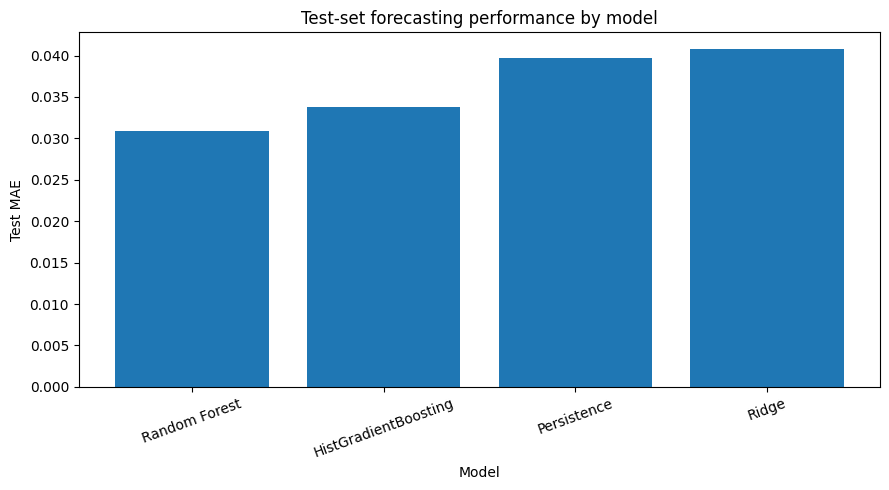

In [171]:
# Model comparison — test-set forecasting performance

model_plot_df = final_test_results.copy()

plt.figure(figsize=(9, 5))

plt.bar(
    model_plot_df["Model"],
    model_plot_df["MAE"]
)

plt.xlabel("Model")
plt.ylabel("Test MAE")
plt.title("Test-set forecasting performance by model")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    "../figures/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Validation tuning: Ridge


In [122]:
ridge_grid = [0.01, 0.1, 1.0, 10.0, 100.0]
rows = []

for alpha in ridge_grid:
    model = make_ridge(alpha)
    model.fit(X_train, y_train)
    row = metric_row("Ridge", "Validation", y_val, model.predict(X_val))
    row["alpha"] = alpha
    rows.append(row)

ridge_tuning = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(ridge_tuning.round(6))

best_ridge_alpha = float(ridge_tuning.loc[0, "alpha"])
print("Selected Ridge alpha:", best_ridge_alpha)


,Model,Split,MAE,RMSE,R2,alpha
0,Ridge,Validation,0.04228,0.05452,0.88745,10.00000
1,Ridge,Validation,0.04229,0.05451,0.88750,1.00000
2,Ridge,Validation,0.04229,0.05450,0.88750,0.10000
3,Ridge,Validation,0.04229,0.05450,0.88750,0.01000
4,Ridge,Validation,0.04238,0.05480,0.88627,100.00000


Selected Ridge alpha: 10.0


## Validation tuning: Random Forest


In [123]:
rf_grid = [
    {"max_depth": d, "min_samples_leaf": leaf, "max_features": mf}
    for d in [None, 12]
    for leaf in [1, 3, 5]
    for mf in ["sqrt", 0.7]
]

rows = []
for params in rf_grid:
    model = make_rf(
        n_estimators=200,
        max_depth=params["max_depth"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
    )
    model.fit(X_train, y_train)
    row = metric_row("Random Forest", "Validation", y_val, model.predict(X_val))
    row.update(params)
    rows.append(row)

rf_tuning = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(rf_tuning.head(10).round(6))

best_rf_params = rf_tuning.loc[0, ["max_depth", "min_samples_leaf", "max_features"]].to_dict()
print("Selected Random Forest parameters:", best_rf_params)


,Model,Split,MAE,RMSE,R2,max_depth,min_samples_leaf,max_features
0,Random Forest,Validation,0.03237,0.04950,0.90721,12.00000,5,0.70000
1,Random Forest,Validation,0.03239,0.04960,0.90683,NaN,5,0.70000
2,Random Forest,Validation,0.03247,0.04929,0.90800,NaN,3,0.70000
3,Random Forest,Validation,0.03266,0.05281,0.89438,12.00000,3,sqrt
4,Random Forest,Validation,0.03276,0.05232,0.89632,12.00000,1,sqrt
5,Random Forest,Validation,0.03292,0.05019,0.90461,12.00000,1,0.70000
6,Random Forest,Validation,0.03308,0.05015,0.90477,12.00000,3,0.70000
7,Random Forest,Validation,0.03312,0.05335,0.89222,12.00000,5,sqrt
8,Random Forest,Validation,0.03356,0.05247,0.89576,NaN,3,sqrt
9,Random Forest,Validation,0.03394,0.05075,0.90246,NaN,1,0.70000


Selected Random Forest parameters: {'max_depth': 12.0, 'min_samples_leaf': 5, 'max_features': 0.7}


## Validation tuning: HistGradientBoosting


In [124]:
hgb_grid = [
    {
        "learning_rate": lr,
        "max_iter": it,
        "max_leaf_nodes": leaves,
        "l2_regularization": l2,
    }
    for lr in [0.03, 0.05, 0.10]
    for it in [100, 200]
    for leaves in [15, 31]
    for l2 in [0.0, 1.0]
]

rows = []
for params in hgb_grid:
    model = make_hgb(**params)
    model.fit(X_train, y_train)
    row = metric_row("HistGradientBoosting", "Validation", y_val, model.predict(X_val))
    row.update(params)
    rows.append(row)

hgb_tuning = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(hgb_tuning.head(10).round(6))

best_hgb_params = hgb_tuning.loc[0, [
    "learning_rate", "max_iter", "max_leaf_nodes", "l2_regularization"
]].to_dict()
print("Selected HistGradientBoosting parameters:", best_hgb_params)


,Model,Split,MAE,RMSE,R2,learning_rate,max_iter,max_leaf_nodes,l2_regularization
0,HistGradientBoosting,Validation,0.03154,0.05063,0.90291,0.05000,100,15,1.00000
1,HistGradientBoosting,Validation,0.03168,0.05133,0.90020,0.05000,100,31,0.00000
2,HistGradientBoosting,Validation,0.03177,0.05134,0.90017,0.10000,100,15,1.00000
3,HistGradientBoosting,Validation,0.03177,0.05186,0.89816,0.03000,200,31,0.00000
4,HistGradientBoosting,Validation,0.03179,0.05007,0.90505,0.03000,100,31,0.00000
5,HistGradientBoosting,Validation,0.03179,0.05121,0.90070,0.03000,200,15,1.00000
6,HistGradientBoosting,Validation,0.03181,0.04857,0.91066,0.03000,100,15,1.00000
7,HistGradientBoosting,Validation,0.03207,0.05203,0.89750,0.05000,100,15,0.00000
8,HistGradientBoosting,Validation,0.03213,0.05019,0.90462,0.03000,100,31,1.00000
9,HistGradientBoosting,Validation,0.03215,0.04926,0.90812,0.03000,100,15,0.00000


Selected HistGradientBoosting parameters: {'learning_rate': 0.05, 'max_iter': 100.0, 'max_leaf_nodes': 15.0, 'l2_regularization': 1.0}


## Freeze model configurations using validation MAE

Model selection is completed here, before final test evaluation.


In [125]:
selected_models = {
    "Ridge": make_ridge(best_ridge_alpha),
    "Random Forest": make_rf(
        n_estimators=200,
        max_depth=None if pd.isna(best_rf_params["max_depth"]) else int(best_rf_params["max_depth"]),
        min_samples_leaf=int(best_rf_params["min_samples_leaf"]),
        max_features=best_rf_params["max_features"],
    ),
    "HistGradientBoosting": make_hgb(
        learning_rate=float(best_hgb_params["learning_rate"]),
        max_iter=int(best_hgb_params["max_iter"]),
        max_leaf_nodes=int(best_hgb_params["max_leaf_nodes"]),
        l2_regularization=float(best_hgb_params["l2_regularization"]),
    ),
}

frozen_val_predictions = {"Persistence": pred_persistence_val}
rows = [metric_row("Persistence", "Validation", y_val, pred_persistence_val)]

for name, model in selected_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    frozen_val_predictions[name] = pred
    rows.append(metric_row(name, "Validation", y_val, pred))

frozen_val_results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(frozen_val_results.round(6))

selected_model_name = frozen_val_results.iloc[0]["Model"]
print("Model selected by validation MAE:", selected_model_name)
print("Test data has not been used for selection.")


,Model,Split,MAE,RMSE,R2
0,HistGradientBoosting,Validation,0.03154,0.05063,0.90291
1,Persistence,Validation,0.03168,0.05376,0.89056
2,Random Forest,Validation,0.03237,0.04950,0.90721
3,Ridge,Validation,0.04228,0.05452,0.88745


Model selected by validation MAE: HistGradientBoosting
Test data has not been used for selection.


## Final training on train + validation, then held-out test

The selected configurations are frozen. ML models are refit on train + validation, then evaluated once on the test period.


In [126]:
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

final_models = {
    "Ridge": make_ridge(best_ridge_alpha),
    "Random Forest": make_rf(
        n_estimators=200,
        max_depth=None if pd.isna(best_rf_params["max_depth"]) else int(best_rf_params["max_depth"]),
        min_samples_leaf=int(best_rf_params["min_samples_leaf"]),
        max_features=best_rf_params["max_features"],
    ),
    "HistGradientBoosting": make_hgb(
        learning_rate=float(best_hgb_params["learning_rate"]),
        max_iter=int(best_hgb_params["max_iter"]),
        max_leaf_nodes=int(best_hgb_params["max_leaf_nodes"]),
        l2_regularization=float(best_hgb_params["l2_regularization"]),
    ),
}

final_test_predictions = {"Persistence": pred_persistence_test}
rows = [metric_row("Persistence", "Test", y_test, pred_persistence_test)]

for name, model in final_models.items():
    model.fit(X_trainval, y_trainval)
    pred = model.predict(X_test)
    final_test_predictions[name] = pred
    rows.append(metric_row(name, "Test", y_test, pred))

final_test_results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(final_test_results.round(6))


,Model,Split,MAE,RMSE,R2
0,Random Forest,Test,0.03088,0.05131,0.81149
1,HistGradientBoosting,Test,0.03382,0.05301,0.79879
2,Persistence,Test,0.03968,0.06857,0.66333
3,Ridge,Test,0.04077,0.06449,0.70222


## Validation vs test performance


In [127]:
validation_summary = frozen_val_results.rename(columns={
    "MAE": "Validation_MAE",
    "RMSE": "Validation_RMSE",
    "R2": "Validation_R2",
}).drop(columns=["Split"])

test_summary = final_test_results.rename(columns={
    "MAE": "Test_MAE",
    "RMSE": "Test_RMSE",
    "R2": "Test_R2",
}).drop(columns=["Split"])

comparison = validation_summary.merge(test_summary, on="Model", how="outer")
display(comparison.round(6))
print("This diagnoses temporal generalization; test data was not used for model selection.")


,Model,Validation_MAE,Validation_RMSE,Validation_R2,Test_MAE,Test_RMSE,Test_R2
0,HistGradientBoosting,0.03154,0.05063,0.90291,0.03382,0.05301,0.79879
1,Persistence,0.03168,0.05376,0.89056,0.03968,0.06857,0.66333
2,Random Forest,0.03237,0.04950,0.90721,0.03088,0.05131,0.81149
3,Ridge,0.04228,0.05452,0.88745,0.04077,0.06449,0.70222


This diagnoses temporal generalization; test data was not used for model selection.


## Relative improvement over persistence


In [128]:
baseline = final_test_results.loc[
    final_test_results["Model"] == "Persistence"
].iloc[0]

baseline_mae = baseline["MAE"]
baseline_rmse = baseline["RMSE"]

rows = []
for _, row in final_test_results.iterrows():
    rows.append({
        "Model": row["Model"],
        "Test_MAE": row["MAE"],
        "MAE_improvement_vs_persistence_pct":
            100 * (baseline_mae - row["MAE"]) / baseline_mae,
        "Test_RMSE": row["RMSE"],
        "RMSE_improvement_vs_persistence_pct":
            100 * (baseline_rmse - row["RMSE"]) / baseline_rmse,
    })

display(pd.DataFrame(rows).round(3))


,Model,Test_MAE,MAE_improvement_vs_persistence_pct,Test_RMSE,RMSE_improvement_vs_persistence_pct
0,Random Forest,0.03100,22.17200,0.05100,25.17200
1,HistGradientBoosting,0.03400,14.77400,0.05300,22.69200
2,Persistence,0.04000,0.00000,0.06900,0.00000
3,Ridge,0.04100,-2.72600,0.06400,5.95200


## Actual vs predicted: validation period


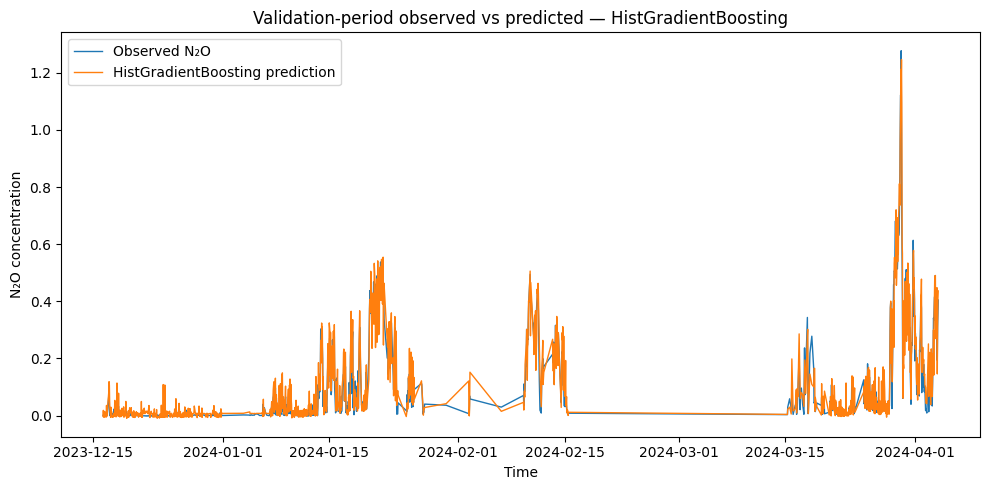

In [129]:
selected_val_pred = frozen_val_predictions[selected_model_name]

plt.figure(figsize=(10, 5))
plt.plot(time_val, y_val.to_numpy(), label="Observed N₂O", linewidth=1)
plt.plot(time_val, selected_val_pred, label=f"{selected_model_name} prediction", linewidth=1)
plt.xlabel("Time")
plt.ylabel("N₂O concentration")
plt.title(f"Validation-period observed vs predicted — {selected_model_name}")
plt.legend()
plt.tight_layout()
plt.show()


## Actual vs predicted: final test period


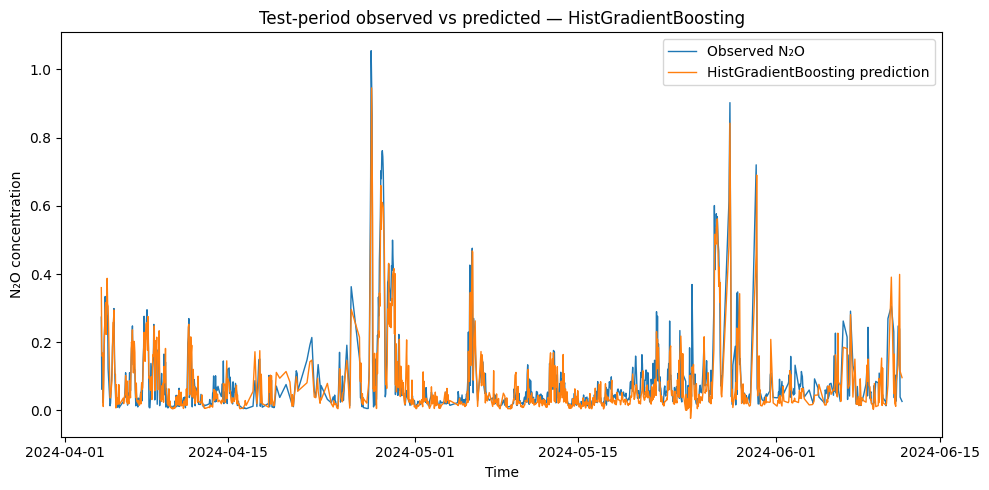

In [161]:
selected_test_pred = final_test_predictions[selected_model_name]

plt.figure(figsize=(10, 5))
plt.plot(time_test, y_test.to_numpy(), label="Observed N₂O", linewidth=1)
plt.plot(time_test, selected_test_pred, label=f"{selected_model_name} prediction", linewidth=1)
plt.xlabel("Time")
plt.ylabel("N₂O concentration")
plt.title(f"Test-period observed vs predicted — {selected_model_name}")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/observed_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()


## Prediction scatter


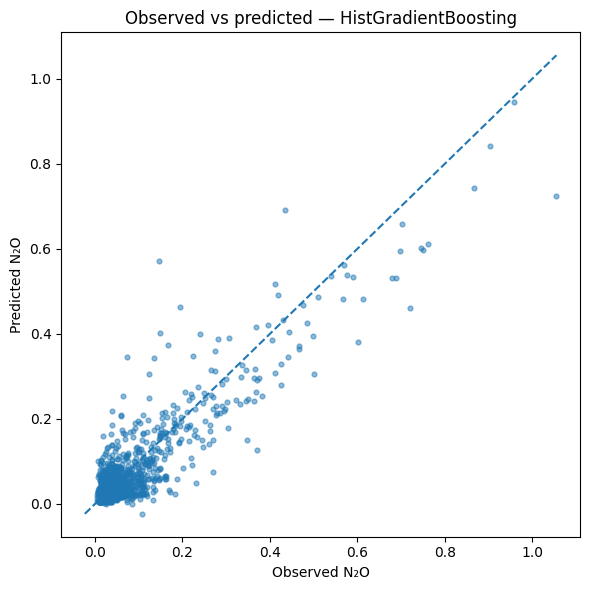

In [162]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, selected_test_pred, s=12, alpha=0.5)

lo = min(y_test.min(), selected_test_pred.min())
hi = max(y_test.max(), selected_test_pred.max())

plt.plot([lo, hi], [lo, hi], linestyle="--")
plt.xlabel("Observed N₂O")
plt.ylabel("Predicted N₂O")
plt.title(f"Observed vs predicted — {selected_model_name}")
plt.tight_layout()
plt.savefig("../figures/observed_vs_predicted_scatter.png",
            dpi=300, bbox_inches="tight")
plt.show()


## Residual diagnostics


,Residual
count,"1,127.00000"
mean,0.00817
std,0.05240
min,-0.42566
1%,-0.14931
5%,-0.06755
50%,0.00743
95%,0.08897
99%,0.15102
max,0.33094


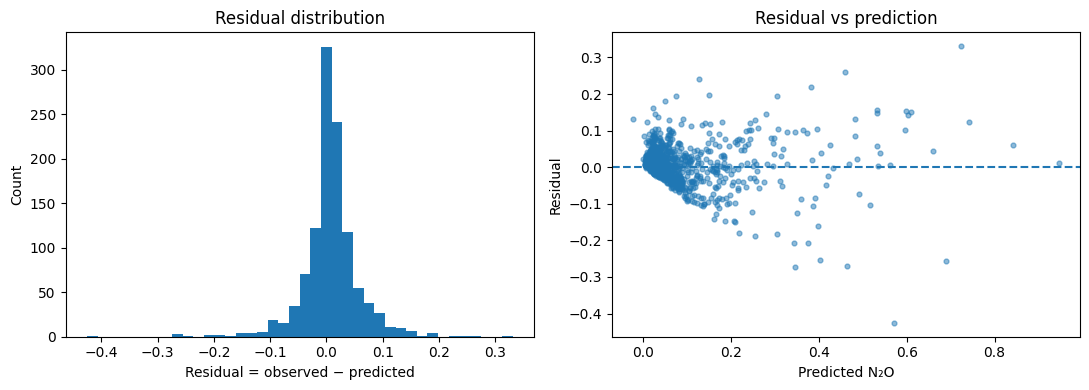

In [132]:
residuals = y_test.to_numpy() - selected_test_pred

display(pd.Series(residuals).describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
).to_frame("Residual"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(residuals, bins=40)
axes[0].set_xlabel("Residual = observed − predicted")
axes[0].set_ylabel("Count")
axes[0].set_title("Residual distribution")

axes[1].scatter(selected_test_pred, residuals, s=12, alpha=0.5)
axes[1].axhline(0, linestyle="--")
axes[1].set_xlabel("Predicted N₂O")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residual vs prediction")

plt.tight_layout()
plt.show()


## Error by observed-N₂O regime
Quartiles are used rather than invented regulatory thresholds.


In [133]:
error_df = pd.DataFrame({
    "observed": y_test.to_numpy(),
    "predicted": selected_test_pred,
})

error_df["observed_quantile_group"] = pd.qcut(
    error_df["observed"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"],
    duplicates="drop",
)

def regime_metrics(g):
    mse = mean_squared_error(g["observed"], g["predicted"])
    return pd.Series({
        "n": len(g),
        "MAE": mean_absolute_error(g["observed"], g["predicted"]),
        "RMSE": np.sqrt(mse),
        "Mean_observed": g["observed"].mean(),
        "Mean_predicted": g["predicted"].mean(),
    })

error_by_regime = (
    error_df.groupby("observed_quantile_group", observed=False)
    .apply(regime_metrics)
    .reset_index()
)

display(error_by_regime.round(6))


,observed_quantile_group,n,MAE,RMSE,Mean_observed,Mean_predicted
0,Q1,282.00000,0.01508,0.02534,0.01710,0.02676
1,Q2,282.00000,0.02036,0.02998,0.03484,0.03742
2,Q3,281.00000,0.03350,0.04393,0.06299,0.05207
3,Q4,282.00000,0.06634,0.08811,0.22581,0.19182


## Q90 high-N₂O error analysis
Q90 is an analytical threshold derived from pre-test historical N₂O observations (train + validation), not a regulatory threshold.


In [134]:
q90 = pd.concat([y_train, y_val]).quantile(0.90)
high_mask = y_test.to_numpy() >= q90

rows = []
for name, pred in final_test_predictions.items():
    mse = mean_squared_error(
        y_test.to_numpy()[high_mask],
        pred[high_mask],
    )
    rows.append({
        "Model": name,
        "Q90_threshold": q90,
        "High_N2O_test_cases": int(high_mask.sum()),
        "MAE_Q90_plus": mean_absolute_error(
            y_test.to_numpy()[high_mask],
            pred[high_mask],
        ),
        "RMSE_Q90_plus": np.sqrt(mse),
    })

high_event_results = pd.DataFrame(rows)
display(high_event_results.round(6))
print("Q90 threshold:", round(q90, 6))
print("High-N₂O cases:", int(high_mask.sum()))


,Model,Q90_threshold,High_N2O_test_cases,MAE_Q90_plus,RMSE_Q90_plus
0,Persistence,0.41287,33,0.11874,0.15171
1,Ridge,0.41287,33,0.13901,0.17056
2,Random Forest,0.41287,33,0.08513,0.11311
3,HistGradientBoosting,0.41287,33,0.10670,0.13302


Q90 threshold: 0.41287
High-N₂O cases: 33


## High-N₂O improvement relative to persistence


In [135]:
persistence_q90 = high_event_results.loc[
    high_event_results["Model"] == "Persistence"
].iloc[0]

rows = []
for _, row in high_event_results.iterrows():
    rows.append({
        "Model": row["Model"],
        "Q90_MAE": row["MAE_Q90_plus"],
        "MAE_improvement_vs_persistence_pct":
            100 * (persistence_q90["MAE_Q90_plus"] - row["MAE_Q90_plus"]) / persistence_q90["MAE_Q90_plus"],
        "Q90_RMSE": row["RMSE_Q90_plus"],
        "RMSE_improvement_vs_persistence_pct":
            100 * (persistence_q90["RMSE_Q90_plus"] - row["RMSE_Q90_plus"]) / persistence_q90["RMSE_Q90_plus"],
    })

display(pd.DataFrame(rows).round(3))


,Model,Q90_MAE,MAE_improvement_vs_persistence_pct,Q90_RMSE,RMSE_improvement_vs_persistence_pct
0,Persistence,0.11900,0.00000,0.15200,0.00000
1,Ridge,0.13900,-17.07000,0.17100,-12.42500
2,Random Forest,0.08500,28.30700,0.11300,25.44100
3,HistGradientBoosting,0.10700,10.14100,0.13300,12.32000


## Stage 5 validation gate


In [136]:
stage5_checks = {
    "stage4_rows_7510": len(df) == 7510,
    "target_complete": y.notna().all(),
    "current_n2o_complete": df["t1_n2o"].notna().all(),
    "chronological_split": time_train.max() < time_val.min() and time_val.max() < time_test.min(),
    "no_random_split": True,
    "persistence_test_complete": np.isfinite(pred_persistence_test).all(),
    "ridge_test_complete": np.isfinite(final_test_predictions["Ridge"]).all(),
    "rf_test_complete": np.isfinite(final_test_predictions["Random Forest"]).all(),
    "hgb_test_complete": np.isfinite(final_test_predictions["HistGradientBoosting"]).all(),
    "mae_finite": np.isfinite(final_test_results["MAE"]).all(),
    "rmse_finite": np.isfinite(final_test_results["RMSE"]).all(),
    "r2_finite": np.isfinite(final_test_results["R2"]).all(),
    "test_after_validation_selection": True,
}

print("STAGE 5 VALIDATION GATE")
print("-" * 60)

for check, passed in stage5_checks.items():
    print(f"{check}: {'PASS' if passed else 'FAIL'}")

overall_pass = all(stage5_checks.values())

print("-" * 60)
print("OVERALL STAGE 5:", "PASS" if overall_pass else "FAIL")

assert overall_pass, "Stage 5 validation gate failed."


STAGE 5 VALIDATION GATE
------------------------------------------------------------
stage4_rows_7510: PASS
target_complete: PASS
current_n2o_complete: PASS
chronological_split: PASS
no_random_split: PASS
persistence_test_complete: PASS
ridge_test_complete: PASS
rf_test_complete: PASS
hgb_test_complete: PASS
mae_finite: PASS
rmse_finite: PASS
r2_finite: PASS
test_after_validation_selection: PASS
------------------------------------------------------------
OVERALL STAGE 5: PASS


# 8. Interpretability and Error Analysis


## Imports and configuration


In [137]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
DATA_PATH = Path("../data/processed/stage_4_modelling_table.csv")

# EXACT configuration selected in Stage 5 using validation MAE.
SELECTED_MODEL_NAME = "HistGradientBoosting"

HGB_PARAMS = {
    "learning_rate": 0.05,
    "max_iter": 100,
    "max_leaf_nodes": 15,
    "l2_regularization": 1.0,
}

print("Configuration loaded.")
print("Data:", DATA_PATH)
print("Selected model:", SELECTED_MODEL_NAME)
print("Frozen HGB parameters:", HGB_PARAMS)


Configuration loaded.
Data: ..\data\processed\stage_4_modelling_table.csv
Selected model: HistGradientBoosting
Frozen HGB parameters: {'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 15, 'l2_regularization': 1.0}


## Load the Stage 4 modelling table


In [138]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Place it in the same directory as this notebook."
    )

df = pd.read_csv(DATA_PATH)

df["hour_start"] = pd.to_datetime(df["hour_start"], utc=True)
df = df.sort_values("hour_start").reset_index(drop=True)

print("Shape:", df.shape)
display(df.head())


Shape: (7510, 40)


,hour_start,n2o_t_plus_1,n2o_lag_1h,n2o_lag_2h,n2o_lag_3h,n2o_lag_6h,n2o_lag_24h,t1_nh4_lag_1h,t1_no3_lag_1h,t1_do_lag_1h,t1_do_setpoint_lag_1h,t1_airflow_est_lag_1h,t1_ss_lag_1h,t1_temp_lag_1h,inlet_flow_lag_1h,t1_n2o,t1_nh4,t1_no3,t1_do,t1_do_setpoint,t1_airflow_est,t1_ss,t1_temp,inlet_flow,stormwater_mode,phase_0.0,phase_1.0,phase_2.0,inlet_tank_0.0,inlet_tank_1.0,inlet_tank_2.0,outlet_tank_0.0,outlet_tank_1.0,outlet_tank_2.0,hour_sin,hour_cos,dow_sin,dow_cos,n2o_recent_mean_3h,n2o_recent_std_3h
0,2022-10-05 08:30:00+00:00,0.00808,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.00000,1.60477,1.61227,0.48888,0.46667,"2,040.58962",2.17657,17.96568,"2,224.91037",0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,-0.50000,-0.86603,0.97493,-0.22252,NaN,NaN
1,2022-10-05 10:30:00+00:00,0.03765,NaN,-0.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.00874,2.67636,1.35183,0.66347,0.93664,"3,859.45090",2.15873,17.99766,"1,906.01853",0.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,-0.86603,-0.50000,0.97493,-0.22252,NaN,NaN
2,2022-10-05 12:30:00+00:00,-0.00718,NaN,-0.00874,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.00723,1.64173,1.69947,0.25676,0.50000,"1,610.59301",2.03026,18.03328,"1,902.71989",0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,-1.00000,-0.00000,0.97493,-0.22252,NaN,NaN
3,2022-10-05 14:30:00+00:00,-0.00756,NaN,-0.00723,NaN,-0.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00571,1.73011,1.81820,0.58677,0.46667,"2,242.99928",1.99616,18.04232,"2,054.80326",0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000,1.00000,-0.86603,0.50000,0.97493,-0.22252,NaN,NaN
4,2022-10-05 15:30:00+00:00,0.00064,0.00571,NaN,-0.00723,NaN,NaN,1.73011,1.81820,0.58677,0.46667,"2,242.99928",1.99616,18.04232,"2,054.80326",-0.00756,2.06017,1.54098,0.63955,0.76667,"3,110.67532",2.00521,18.03416,"1,895.25463",0.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,-0.70711,0.70711,0.97493,-0.22252,NaN,NaN


## Validate the frozen Stage 5 population and feature set


In [139]:
TARGET = "n2o_t_plus_1"
TIME_COL = "hour_start"

required = {TIME_COL, TARGET, "t1_n2o"}
missing = required - set(df.columns)

assert not missing, f"Missing required columns: {sorted(missing)}"

assert len(df) == 7510, (
    f"Expected the frozen Stage-4/5 population of 7,510 rows; "
    f"found {len(df)}."
)

FEATURES = [c for c in df.columns if c not in [TIME_COL, TARGET]]

for col in FEATURES:
    lower = col.lower()
    if any(p in lower for p in ["target", "t_plus_1", "coverage", "valid_count", "row_count"]):
        raise AssertionError(f"Potential leakage/bookkeeping feature: {col}")

X = df[FEATURES].copy()
y = df[TARGET].copy()

assert y.notna().all()
assert X["t1_n2o"].notna().all()

print("Frozen Stage 5 population: PASS")
print("Rows:", len(df))
print("Features:", len(FEATURES))
print("Target:", TARGET)


Frozen Stage 5 population: PASS
Rows: 7510
Features: 38
Target: n2o_t_plus_1


## Reproduce the exact chronological Stage 5 split


In [140]:
n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_idx = np.arange(0, train_end)
val_idx = np.arange(train_end, val_end)
test_idx = np.arange(val_end, n)

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()
y_test = y.iloc[test_idx].copy()

time_train = df.loc[train_idx, TIME_COL]
time_val = df.loc[val_idx, TIME_COL]
time_test = df.loc[test_idx, TIME_COL]

assert time_train.max() < time_val.min()
assert time_val.max() < time_test.min()

print("Train:", len(X_train), time_train.min(), "→", time_train.max())
print("Validation:", len(X_val), time_val.min(), "→", time_val.max())
print("Test:", len(X_test), time_test.min(), "→", time_test.max())
print("\nChronological split: PASS")


Train: 5257 2022-10-05 08:30:00+00:00 → 2023-12-16 05:30:00+00:00
Validation: 1126 2023-12-16 06:30:00+00:00 → 2024-04-04 02:30:00+00:00
Test: 1127 2024-04-04 03:30:00+00:00 → 2024-06-11 18:30:00+00:00

Chronological split: PASS


## Recreate the exact Stage 5 HGB pipeline

This cell deliberately uses the exact parameters selected in Stage 5.

The model is fitted on **train + validation**, exactly as it was for the final Stage 5 test evaluation.


In [141]:
def make_hgb(
    learning_rate,
    max_iter,
    max_leaf_nodes,
    l2_regularization,
):
    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "model",
            HistGradientBoostingRegressor(
                learning_rate=learning_rate,
                max_iter=max_iter,
                max_leaf_nodes=max_leaf_nodes,
                l2_regularization=l2_regularization,
                random_state=RANDOM_STATE,
            )
        ),
    ])

model = make_hgb(**HGB_PARAMS)

X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

model.fit(X_trainval, y_trainval)

test_pred = model.predict(X_test)

mse = mean_squared_error(y_test, test_pred)

stage6_metrics = {
    "MAE": mean_absolute_error(y_test, test_pred),
    "RMSE": np.sqrt(mse),
    "R2": r2_score(y_test, test_pred),
}

print("Stage 6 model fitted.")
print({k: round(v, 6) for k, v in stage6_metrics.items()})


Stage 6 model fitted.
{'MAE': 0.033821, 'RMSE': np.float64(0.053006), 'R2': 0.798793}


## Stage 5 → Stage 6 Reproducibility Check

- **MAE:** 0.033821
- **RMSE:** 0.053006
- **R²:** 0.798793


In [142]:
EXPECTED_STAGE5 = {
    "MAE": 0.033821,
    "RMSE": 0.053006,
    "R2": 0.798793,
}

comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Expected_Stage5": [
        EXPECTED_STAGE5["MAE"],
        EXPECTED_STAGE5["RMSE"],
        EXPECTED_STAGE5["R2"],
    ],
    "Stage6_reproduced": [
        stage6_metrics["MAE"],
        stage6_metrics["RMSE"],
        stage6_metrics["R2"],
    ],
})

comparison["Absolute_difference"] = (
    comparison["Stage6_reproduced"] - comparison["Expected_Stage5"]
).abs()

display(comparison.round(8))

reproduction_pass = bool((comparison["Absolute_difference"] < 1e-5).all())

print(
    "Stage 5 → Stage 6 reproducibility:",
    "PASS" if reproduction_pass else "FAIL"
)

assert reproduction_pass, (
    "Stage 6 model does not reproduce the frozen Stage 5 HGB test metrics."
)


,Metric,Expected_Stage5,Stage6_reproduced,Absolute_difference
0,MAE,0.03382,0.03382,0.00000
1,RMSE,0.05301,0.05301,0.00000
2,R2,0.79879,0.79879,0.00000


Stage 5 → Stage 6 reproducibility: PASS


## Permutation importance on the held-out test period

We use the test period for **post-hoc explanation of the frozen model**, not for model selection.

Scoring is based on negative MAE. A larger positive permutation importance means that shuffling that feature worsens predictive performance more strongly.


In [143]:
perm = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values(
    "importance_mean",
    ascending=False
).reset_index(drop=True)

display(importance_df.head(20).round(6))


,feature,importance_mean,importance_std
0,t1_n2o,0.04717,0.00143
1,t1_do_setpoint,0.00914,0.00075
2,t1_do,0.00150,0.00057
3,t1_no3,0.00120,0.00020
4,inlet_flow,0.00097,0.00020
5,n2o_lag_2h,0.00067,0.00018
6,t1_airflow_est,0.00032,0.00025
7,dow_sin,0.00021,0.00011
8,t1_temp,0.00017,0.00011
9,n2o_recent_std_3h,0.00016,0.00007


## Plot the top permutation importances


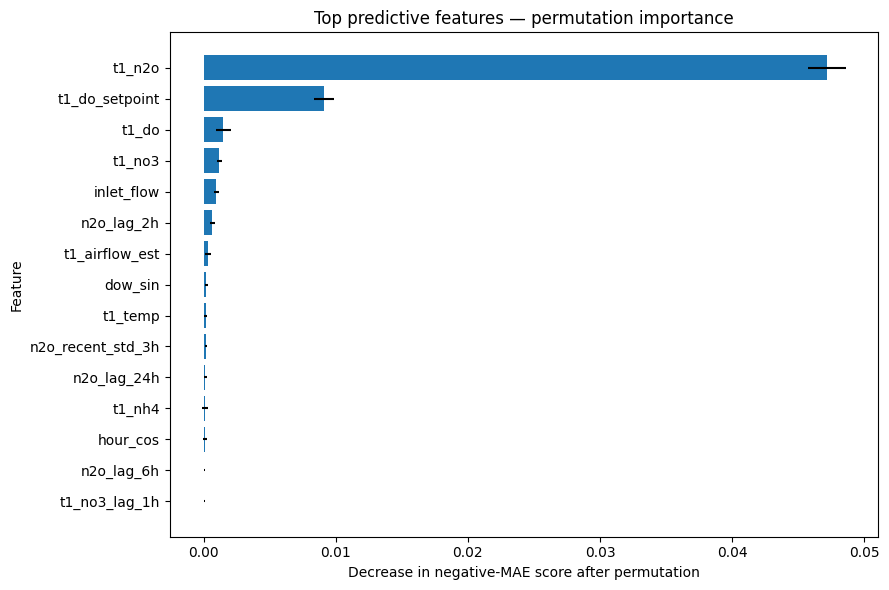

In [163]:
top_n = min(15, len(importance_df))
plot_df = importance_df.head(top_n).sort_values("importance_mean")

plt.figure(figsize=(9, 6))

plt.barh(
    plot_df["feature"],
    plot_df["importance_mean"],
    xerr=plot_df["importance_std"],
)

plt.xlabel("Decrease in negative-MAE score after permutation")
plt.ylabel("Feature")
plt.title("Top predictive features — permutation importance")
plt.tight_layout()
plt.savefig("../figures/feature_importance.png",
            dpi=300, bbox_inches="tight")
plt.show()


## Importance stability

A large mean importance with a small standard deviation is stronger evidence of a stable predictive contribution than a small mean importance with large variability.


In [145]:
importance_df["importance_signal_to_noise"] = (
    importance_df["importance_mean"] /
    importance_df["importance_std"].replace(0, np.nan)
)

display(
    importance_df[
        [
            "feature",
            "importance_mean",
            "importance_std",
            "importance_signal_to_noise",
        ]
    ].head(20).round(6)
)


,feature,importance_mean,importance_std,importance_signal_to_noise
0,t1_n2o,0.04717,0.00143,32.96701
1,t1_do_setpoint,0.00914,0.00075,12.16820
2,t1_do,0.00150,0.00057,2.62514
3,t1_no3,0.00120,0.00020,6.09046
4,inlet_flow,0.00097,0.00020,4.92600
5,n2o_lag_2h,0.00067,0.00018,3.73234
6,t1_airflow_est,0.00032,0.00025,1.30242
7,dow_sin,0.00021,0.00011,1.81991
8,t1_temp,0.00017,0.00011,1.56360
9,n2o_recent_std_3h,0.00016,0.00007,2.13713


## Map features to wastewater/process roles

This mapping is used only for interpretation. It does not modify the trained model.


In [146]:
def feature_role(feature):
    f = feature.lower()

    # Time features must be identified BEFORE the "do" check,
    # otherwise names such as "dow_sin" can be misclassified
    # as dissolved oxygen because they contain the substring "do".
    if (
        f.startswith("dow_")
        or f.startswith("hour_")
        or f.startswith("day_")
        or f.startswith("month_")
        or f.startswith("time_")
        or any(x in f for x in ["sin", "cos"])
    ):
        return "Time feature"

    if "n2o" in f:
        return "N₂O history"

    if any(x in f for x in ["nh4", "no3", "po4"]):
        return "Nitrogen/phosphorus chemistry"

    if "do" in f:
        return "Oxygen / aeration"

    if "airflow" in f:
        return "Airflow"

    if any(x in f for x in ["temp", "temperature"]):
        return "Temperature"

    if "ss" in f or "suspended" in f:
        return "Suspended solids"

    if "valve" in f or "setpoint" in f:
        return "Control/setpoint"

    if "phase" in f:
        return "Process phase"

    if "flow" in f or "inlet" in f:
        return "Influent / hydraulic"

    if "swm" in f or "storm" in f:
        return "Storm-water state"

    return "Other process variable"

importance_df["process_role"] = importance_df["feature"].map(feature_role)

role_summary = (
    importance_df
    .groupby("process_role", as_index=False)
    .agg(
        total_importance=("importance_mean", "sum"),
        mean_importance=("importance_mean", "mean"),
        feature_count=("feature", "count"),
    )
    .sort_values("total_importance", ascending=False)
)

display(role_summary.round(6))


,process_role,total_importance,mean_importance,feature_count
3,N₂O history,0.04807,0.00601,8
5,Oxygen / aeration,0.01060,0.00265,4
2,Nitrogen/phosphorus chemistry,0.00120,0.00030,4
1,Influent / hydraulic,0.00097,0.00019,5
10,Time feature,0.00029,0.00007,4
0,Airflow,0.00022,0.00011,2
9,Temperature,0.00018,0.00009,2
7,Storm-water state,0.00000,0.00000,1
6,Process phase,0.00000,0.00000,3
4,Other process variable,-0.00009,-0.00003,3


## N₂O-history dominance diagnostic

Because current N₂O and recent N₂O history are legitimately available at forecast time, this diagnostic quantifies how concentrated the model's predictive signal is in that feature family.

This is **not** a causal decomposition.


In [147]:
# Sanity check for process-family classification
# "dow_sin" is a time feature, not dissolved oxygen.
if "dow_sin" in importance_df["feature"].values:
    dow_role = importance_df.loc[
        importance_df["feature"] == "dow_sin", "process_role"
    ].iloc[0]
    print("dow_sin classification:", dow_role)
    assert dow_role == "Time feature", (
        "Feature-family mapping error: dow_sin must be classified as Time feature."
    )

print("Feature-family classification sanity check: PASS")


dow_sin classification: Time feature
Feature-family classification sanity check: PASS


In [148]:
n2o_mask = importance_df["process_role"].eq("N₂O history")

n2o_importance_total = importance_df.loc[
    n2o_mask,
    "importance_mean"
].sum()

positive_importance_total = importance_df.loc[
    importance_df["importance_mean"] > 0,
    "importance_mean"
].sum()

n2o_share = (
    n2o_importance_total / positive_importance_total
    if positive_importance_total > 0
    else np.nan
)

print("Positive permutation importance total:", round(positive_importance_total, 6))
print("N₂O-history importance:", round(n2o_importance_total, 6))
print("N₂O-history share:", round(n2o_share, 4))


Positive permutation importance total: 0.062094
N₂O-history importance: 0.048066
N₂O-history share: 0.7741


## Compare process-family importance


In [149]:
families = [
    "N₂O history",
    "Nitrogen/phosphorus chemistry",
    "Oxygen / aeration",
    "Airflow",
    "Temperature",
    "Suspended solids",
    "Control/setpoint",
    "Process phase",
    "Influent / hydraulic",
    "Storm-water state",
    "Time feature",
    "Other process variable",
]

family_rows = []

for family in families:
    sub = importance_df[
        importance_df["process_role"] == family
    ]

    if len(sub) == 0:
        continue

    family_rows.append({
        "Process_family": family,
        "Features": len(sub),
        "Sum_positive_importance": sub.loc[
            sub["importance_mean"] > 0,
            "importance_mean"
        ].sum(),
        "Top_feature": sub.iloc[0]["feature"],
        "Top_feature_importance": sub.iloc[0]["importance_mean"],
    })

family_summary = pd.DataFrame(family_rows).sort_values(
    "Sum_positive_importance",
    ascending=False
)

display(family_summary.round(6))


,Process_family,Features,Sum_positive_importance,Top_feature,Top_feature_importance
0,N₂O history,8,0.04820,t1_n2o,0.04717
2,Oxygen / aeration,4,0.01064,t1_do_setpoint,0.00914
1,Nitrogen/phosphorus chemistry,4,0.00137,t1_no3,0.00120
7,Influent / hydraulic,5,0.00106,inlet_flow,0.00097
3,Airflow,2,0.00032,t1_airflow_est,0.00032
9,Time feature,4,0.00031,dow_sin,0.00021
4,Temperature,2,0.00018,t1_temp,0.00017
10,Other process variable,3,0.00001,outlet_tank_2.0,0.00001
5,Suspended solids,2,0.00000,t1_ss,-0.00005
6,Process phase,3,0.00000,phase_0.0,0.00000


## Reproduce the Stage 5 error-regime analysis

This confirms that the Stage 6 model retains the Stage 5 finding that error increases at elevated observed N₂O.


In [150]:
error_df = pd.DataFrame({
    "observed": y_test.to_numpy(),
    "predicted": test_pred,
})

error_df["residual"] = (
    error_df["observed"] -
    error_df["predicted"]
)

error_df["observed_quantile_group"] = pd.qcut(
    error_df["observed"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"],
    duplicates="drop",
)

regime_rows = []

for group, g in error_df.groupby(
    "observed_quantile_group",
    observed=False
):
    mse = mean_squared_error(
        g["observed"],
        g["predicted"]
    )

    regime_rows.append({
        "Observed_regime": group,
        "n": len(g),
        "MAE": mean_absolute_error(
            g["observed"],
            g["predicted"]
        ),
        "RMSE": np.sqrt(mse),
        "Mean_observed": g["observed"].mean(),
        "Mean_predicted": g["predicted"].mean(),
        "Mean_residual": g["residual"].mean(),
    })

regime_summary = pd.DataFrame(regime_rows)

display(regime_summary.round(6))


,Observed_regime,n,MAE,RMSE,Mean_observed,Mean_predicted,Mean_residual
0,Q1,282,0.01508,0.02534,0.01710,0.02676,-0.00966
1,Q2,282,0.02036,0.02998,0.03484,0.03742,-0.00258
2,Q3,281,0.03350,0.04393,0.06299,0.05207,0.01092
3,Q4,282,0.06634,0.08811,0.22581,0.19182,0.03399


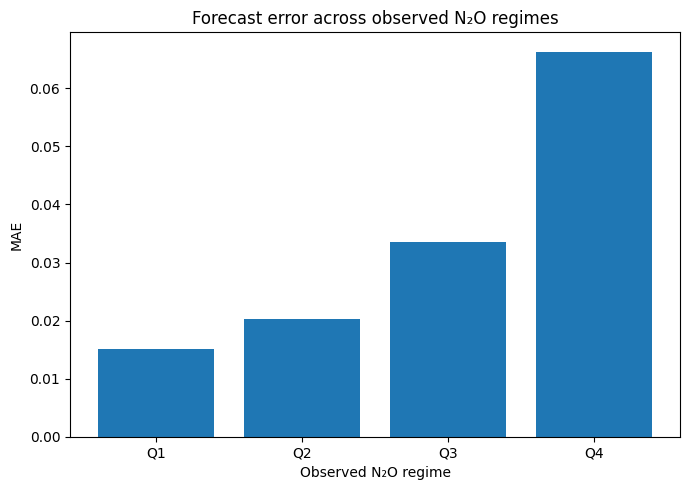

In [164]:
# Error by observed N2O regime

plt.figure(figsize=(7, 5))

plt.bar(
    regime_summary["Observed_regime"],
    regime_summary["MAE"]
)

plt.xlabel("Observed N₂O regime")
plt.ylabel("MAE")
plt.title("Forecast error across observed N₂O regimes")
plt.tight_layout()

plt.savefig(
    "../figures/error_by_regime.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Analytical Q90 monitoring threshold

**This is not a regulatory limit.**

It is a dataset-derived analytical threshold used only to demonstrate how a forecast could generate an elevated-monitoring signal.


In [151]:
monitoring_threshold = float(pd.concat([y_train, y_val]).quantile(0.90))

observed_q90_share = float(
    (y_test >= monitoring_threshold).mean()
)

print(
    "Dataset-derived Q90 threshold:",
    round(monitoring_threshold, 6)
)

print(
    "Observed share at/above Q90:",
    round(observed_q90_share, 4)
)

print(
    "Interpretation: analytical elevated-monitoring threshold only; "
    "not a regulatory or compliance limit."
)


Dataset-derived Q90 threshold: 0.41287
Observed share at/above Q90: 0.0293
Interpretation: analytical elevated-monitoring threshold only; not a regulatory or compliance limit.


## Build the decision-support table

Core logic:

**Current process state → predicted N₂O one hour ahead → elevated-monitoring signal**

The observed future N₂O is retained only for retrospective evaluation.


In [152]:
decision_support = pd.DataFrame({
    "forecast_time": time_test.to_numpy(),
    "current_N2O": X_test["t1_n2o"].to_numpy(),
    "predicted_N2O_t_plus_1": test_pred,
    "observed_N2O_t_plus_1": y_test.to_numpy(),
})

decision_support["Elevated_monitoring"] = (
    decision_support["predicted_N2O_t_plus_1"]
    >= monitoring_threshold
)

decision_support["forecast_error"] = (
    decision_support["observed_N2O_t_plus_1"]
    - decision_support["predicted_N2O_t_plus_1"]
)

display(
    decision_support.head(15).round(6)
)


,forecast_time,current_N2O,predicted_N2O_t_plus_1,observed_N2O_t_plus_1,Elevated_monitoring,forecast_error
0,2024-04-04 03:30:00+00:00,0.40469,0.36017,0.27361,False,-0.08656
1,2024-04-04 04:30:00+00:00,0.27361,0.17320,0.06235,False,-0.11085
2,2024-04-04 05:30:00+00:00,0.06235,0.15851,0.16078,False,0.00228
3,2024-04-04 06:30:00+00:00,0.16078,0.16806,0.06442,False,-0.10364
4,2024-04-04 07:30:00+00:00,0.06442,0.01154,0.02216,False,0.01062
5,2024-04-04 08:30:00+00:00,0.02216,0.10380,0.11711,False,0.01331
6,2024-04-04 09:30:00+00:00,0.11711,0.18460,0.21661,False,0.03200
7,2024-04-04 10:30:00+00:00,0.21661,0.24895,0.25091,False,0.00196
8,2024-04-04 11:30:00+00:00,0.25091,0.29826,0.33430,False,0.03604
9,2024-04-04 12:30:00+00:00,0.33430,0.31605,0.26474,False,-0.05131


## Monitoring flag summary


In [153]:
flag_summary = pd.Series({
    "Test_hours": len(decision_support),
    "Flagged_hours": int(
        decision_support["Elevated_monitoring"].sum()
    ),
    "Flag_rate": decision_support["Elevated_monitoring"].mean(),
    "Mean_current_N2O": decision_support["current_N2O"].mean(),
    "Mean_predicted_next_hour_N2O":
        decision_support["predicted_N2O_t_plus_1"].mean(),
})

display(
    flag_summary.to_frame("value").round(6)
)


,value
Test_hours,"1,127.00000"
Flagged_hours,29.00000
Flag_rate,0.02573
Mean_current_N2O,0.08564
Mean_predicted_next_hour_N2O,0.07704


## Inspect flagged periods

These are candidate periods for **human monitoring/review**.

The model forecast does not prove that an N₂O event will occur and should not automatically trigger process-control action.


In [154]:
flagged = decision_support[
    decision_support["Elevated_monitoring"]
].sort_values(
    "predicted_N2O_t_plus_1",
    ascending=False
)

display(
    flagged.head(20).round(6)
)


,forecast_time,current_N2O,predicted_N2O_t_plus_1,observed_N2O_t_plus_1,Elevated_monitoring,forecast_error
337,2024-04-27 07:30:00+00:00,1.05505,0.94596,0.95718,True,0.01122
953,2024-05-28 00:30:00+00:00,0.77045,0.84255,0.90280,True,0.06025
338,2024-04-27 08:30:00+00:00,0.95718,0.74272,0.86572,True,0.12300
336,2024-04-27 06:30:00+00:00,0.68844,0.72411,1.05505,True,0.33094
984,2024-05-30 07:30:00+00:00,0.72035,0.69044,0.43372,True,-0.25672
356,2024-04-28 02:30:00+00:00,0.56751,0.65948,0.70282,True,0.04334
359,2024-04-28 05:30:00+00:00,0.75054,0.61016,0.76200,True,0.15183
360,2024-04-28 06:30:00+00:00,0.76200,0.60283,0.74439,True,0.14156
358,2024-04-28 04:30:00+00:00,0.67990,0.59801,0.75054,True,0.15253
361,2024-04-28 07:30:00+00:00,0.74439,0.59584,0.69711,True,0.10126


## Process-State Variables for Interpretation

The following names are aligned with the actual Stage 4/5 feature naming used in this project:

- DO: `t1_do`
- DO setpoint: `t1_do_setpoint`
- Airflow: `t1_airflow_est`
- Temperature: `t1_temp`

These variables are used for process interpretation and do not modify the trained model.


In [155]:
state_candidates = [
    "t1_do",
    "t1_do_setpoint",
    "t1_airflow_est",
    "t1_nh4",
    "t1_no3",
    "t1_ss",
    "t1_temp",
    "t1_phase",
    "t2_do",
    "t2_do_setpoint",
    "t2_airflow_est",
    "t2_nh4",
    "t2_no3",
    "t2_ss",
    "t2_temp",
    "t2_phase",
    "inlet_flow",
    "inlet_state_swm",
]

available_state = [
    c for c in state_candidates
    if c in X_test.columns
]

monitoring_output = decision_support.copy()

for c in available_state:
    monitoring_output[c] = X_test[c].to_numpy()

print("Process-state variables included:")
print(available_state)

display(
    monitoring_output.head(10).round(6)
)


Process-state variables included:
['t1_do', 't1_do_setpoint', 't1_airflow_est', 't1_nh4', 't1_no3', 't1_ss', 't1_temp', 'inlet_flow']


,forecast_time,current_N2O,predicted_N2O_t_plus_1,observed_N2O_t_plus_1,Elevated_monitoring,forecast_error,t1_do,t1_do_setpoint,t1_airflow_est,t1_nh4,t1_no3,t1_ss,t1_temp,inlet_flow
0,2024-04-04 03:30:00+00:00,0.40469,0.36017,0.27361,False,-0.08656,0.66215,0.43333,"1,465.20606",1.90693,7.59571,2.22876,11.95291,"2,655.72916"
1,2024-04-04 04:30:00+00:00,0.27361,0.17320,0.06235,False,-0.11085,0.14886,0.00000,0.00000,2.34855,5.27260,2.22835,11.94824,"3,056.48145"
2,2024-04-04 05:30:00+00:00,0.06235,0.15851,0.16078,False,0.00228,0.85769,1.06137,"3,104.54218",4.31684,3.12440,2.25563,11.94547,"4,859.43289"
3,2024-04-04 06:30:00+00:00,0.16078,0.16806,0.06442,False,-0.10364,0.98947,0.81135,"2,792.24849",2.76742,4.39517,2.22457,11.92747,"4,794.67593"
4,2024-04-04 07:30:00+00:00,0.06442,0.01154,0.02216,False,0.01062,0.17649,0.28362,493.73270,2.27780,3.54211,2.21604,11.92365,"4,533.04600"
5,2024-04-04 08:30:00+00:00,0.02216,0.10380,0.11711,False,0.01331,1.12506,1.26009,"4,401.93891",4.94379,2.34113,2.11834,11.92057,"4,488.13657"
6,2024-04-04 09:30:00+00:00,0.11711,0.18460,0.21661,False,0.03200,1.20328,1.13314,"3,080.70163",3.81702,4.08109,2.09417,11.92516,"4,936.22685"
7,2024-04-04 10:30:00+00:00,0.21661,0.24895,0.25091,False,0.00196,1.13624,1.00166,"3,233.60900",1.90662,5.41204,2.06333,11.92546,"3,897.85876"
8,2024-04-04 11:30:00+00:00,0.25091,0.29826,0.33430,False,0.03604,0.99296,1.01657,"3,513.77018",2.45303,6.09218,2.08418,11.93817,"4,660.70601"
9,2024-04-04 12:30:00+00:00,0.33430,0.31605,0.26474,False,-0.05131,0.66165,0.45687,"1,421.52795",2.63274,6.68203,2.07821,11.95144,"4,517.65052"


## Compact process-monitoring view


In [156]:
compact_cols = [
    "forecast_time",
    "current_N2O",
    "predicted_N2O_t_plus_1",
    "Elevated_monitoring",
]

preferred_process_cols = [
    "t1_do",
    "t1_do_setpoint",
    "t1_airflow_est",
    "t1_nh4",
    "t1_no3",
    "t1_ss",
    "t1_temp",
    "t1_phase",
    "inlet_flow",
]

compact_cols += [
    c for c in preferred_process_cols
    if c in monitoring_output.columns
]

compact_monitoring = monitoring_output[
    compact_cols
].copy()

display(
    compact_monitoring.head(20).round(5)
)


,forecast_time,current_N2O,predicted_N2O_t_plus_1,Elevated_monitoring,t1_do,t1_do_setpoint,t1_airflow_est,t1_nh4,t1_no3,t1_ss,t1_temp,inlet_flow
0,2024-04-04 03:30:00+00:00,0.40469,0.36017,False,0.66215,0.43333,"1,465.20606",1.90693,7.59571,2.22876,11.95291,"2,655.72916"
1,2024-04-04 04:30:00+00:00,0.27361,0.17320,False,0.14886,0.00000,0.00000,2.34855,5.27260,2.22835,11.94824,"3,056.48145"
2,2024-04-04 05:30:00+00:00,0.06235,0.15851,False,0.85769,1.06138,"3,104.54218",4.31684,3.12440,2.25563,11.94547,"4,859.43289"
3,2024-04-04 06:30:00+00:00,0.16078,0.16806,False,0.98947,0.81135,"2,792.24849",2.76742,4.39517,2.22457,11.92748,"4,794.67593"
4,2024-04-04 07:30:00+00:00,0.06442,0.01154,False,0.17649,0.28362,493.73270,2.27780,3.54211,2.21604,11.92365,"4,533.04600"
5,2024-04-04 08:30:00+00:00,0.02216,0.10380,False,1.12506,1.26009,"4,401.93891",4.94379,2.34113,2.11834,11.92057,"4,488.13657"
6,2024-04-04 09:30:00+00:00,0.11711,0.18461,False,1.20328,1.13313,"3,080.70163",3.81702,4.08109,2.09417,11.92515,"4,936.22685"
7,2024-04-04 10:30:00+00:00,0.21661,0.24895,False,1.13624,1.00166,"3,233.60900",1.90662,5.41204,2.06334,11.92546,"3,897.85876"
8,2024-04-04 11:30:00+00:00,0.25091,0.29826,False,0.99296,1.01657,"3,513.77018",2.45303,6.09218,2.08418,11.93818,"4,660.70601"
9,2024-04-04 12:30:00+00:00,0.33430,0.31605,False,0.66165,0.45687,"1,421.52795",2.63274,6.68203,2.07821,11.95144,"4,517.65052"


## Top predictive drivers


In [157]:
TOP_K = 8

top_drivers = importance_df.head(TOP_K)[
    [
        "feature",
        "process_role",
        "importance_mean",
        "importance_std",
    ]
].copy()

display(
    top_drivers.round(6)
)


,feature,process_role,importance_mean,importance_std
0,t1_n2o,N₂O history,0.04717,0.00143
1,t1_do_setpoint,Oxygen / aeration,0.00914,0.00075
2,t1_do,Oxygen / aeration,0.00150,0.00057
3,t1_no3,Nitrogen/phosphorus chemistry,0.00120,0.00020
4,inlet_flow,Influent / hydraulic,0.00097,0.00020
5,n2o_lag_2h,N₂O history,0.00067,0.00018
6,t1_airflow_est,Airflow,0.00032,0.00025
7,dow_sin,Time feature,0.00021,0.00011


In [158]:
print("INTERPRETATION TEMPLATE")
print("=" * 70)

print("Top predictive contributors:")
for _, row in top_drivers.head(5).iterrows():
    print(
        f"- {row['feature']} "
        f"[{row['process_role']}]: "
        f"importance={row['importance_mean']:.6f}"
    )

print("\nScientific interpretation:")
print(
    "These variables are predictive contributors in the fitted model; "
    "permutation importance does not establish causality."
)

print("\nOperational interpretation:")
print(
    "The forecast can serve as an early-monitoring signal, with the "
    "dataset-derived Q90 threshold used only as an analytical trigger."
)

print("\nLimitation:")
print(
    "Stage 5 showed increasing error at elevated N₂O levels, so flagged "
    "periods should support human review rather than automatic control."
)


INTERPRETATION TEMPLATE
Top predictive contributors:
- t1_n2o [N₂O history]: importance=0.047167
- t1_do_setpoint [Oxygen / aeration]: importance=0.009142
- t1_do [Oxygen / aeration]: importance=0.001497
- t1_no3 [Nitrogen/phosphorus chemistry]: importance=0.001199
- inlet_flow [Influent / hydraulic]: importance=0.000971

Scientific interpretation:
These variables are predictive contributors in the fitted model; permutation importance does not establish causality.

Operational interpretation:
The forecast can serve as an early-monitoring signal, with the dataset-derived Q90 threshold used only as an analytical trigger.

Limitation:
Stage 5 showed increasing error at elevated N₂O levels, so flagged periods should support human review rather than automatic control.


## Permutation-importance stability


In [159]:
stability = importance_df.copy()

stability["relative_std"] = (
    stability["importance_std"] /
    stability["importance_mean"].abs().replace(0, np.nan)
)

display(
    stability.sort_values(
        "importance_mean",
        ascending=False
    ).head(15)[
        [
            "feature",
            "importance_mean",
            "importance_std",
            "relative_std",
        ]
    ].round(6)
)


,feature,importance_mean,importance_std,relative_std
0,t1_n2o,0.04717,0.00143,0.03033
1,t1_do_setpoint,0.00914,0.00075,0.08218
2,t1_do,0.00150,0.00057,0.38093
3,t1_no3,0.00120,0.00020,0.16419
4,inlet_flow,0.00097,0.00020,0.20300
5,n2o_lag_2h,0.00067,0.00018,0.26793
6,t1_airflow_est,0.00032,0.00025,0.76780
7,dow_sin,0.00021,0.00011,0.54948
8,t1_temp,0.00017,0.00011,0.63955
9,n2o_recent_std_3h,0.00016,0.00007,0.46792


## Stage 6 validation gate

The gate now includes the critical reproducibility check that was missing from the previous Stage 6 version.


In [160]:
stage6_checks = {
    "frozen_population_7510": len(df) == 7510,
    "chronological_split": (
        time_train.max() < time_val.min()
        and time_val.max() < time_test.min()
    ),
    "exact_hgb_parameters": HGB_PARAMS == {
        "learning_rate": 0.05,
        "max_iter": 100,
        "max_leaf_nodes": 15,
        "l2_regularization": 1.0,
    },
    "stage5_metrics_reproduced": reproduction_pass,
    "test_prediction_complete": (
        len(test_pred) == len(y_test)
    ),
    "test_prediction_finite": np.isfinite(test_pred).all(),
    "permutation_importance_available": (
        len(importance_df) == len(FEATURES)
    ),
    "no_target_feature": TARGET not in FEATURES,
    "no_future_target_feature": not any(
        "t_plus_1" in c.lower()
        for c in FEATURES
    ),
    "monitoring_threshold_finite": np.isfinite(
        monitoring_threshold
    ),
    "decision_support_complete": (
        decision_support["predicted_N2O_t_plus_1"]
        .notna()
        .all()
    ),
    "monitoring_flag_boolean": (
        decision_support["Elevated_monitoring"].dtype == bool
    ),
    "correct_do_field_available": (
        "t1_do" in X_test.columns
    ),
    "correct_do_setpoint_field_available": (
        "t1_do_setpoint" in X_test.columns
    ),
    "correct_airflow_field_available": (
        "t1_airflow_est" in X_test.columns
    ),
    "process_output_created": (
        len(monitoring_output) == len(test_pred)
    ),
    "dow_sin_correctly_classified": (
        "dow_sin" not in importance_df["feature"].values
        or importance_df.loc[
            importance_df["feature"] == "dow_sin",
            "process_role"
        ].iloc[0] == "Time feature"
    ),
}

print("STAGE 6 VALIDATION GATE")
print("-" * 75)

for check, passed in stage6_checks.items():
    print(
        f"{check}: {'PASS' if passed else 'FAIL'}"
    )

overall_pass = all(stage6_checks.values())

print("-" * 75)
print(
    "OVERALL STAGE 6:",
    "PASS" if overall_pass else "FAIL"
)

assert overall_pass, (
    "Stage 6 validation gate failed. "
    "Do not freeze Stage 6 until all checks pass."
)


STAGE 6 VALIDATION GATE
---------------------------------------------------------------------------
frozen_population_7510: PASS
chronological_split: PASS
exact_hgb_parameters: PASS
stage5_metrics_reproduced: PASS
test_prediction_complete: PASS
test_prediction_finite: PASS
permutation_importance_available: PASS
no_target_feature: PASS
no_future_target_feature: PASS
monitoring_threshold_finite: PASS
decision_support_complete: PASS
monitoring_flag_boolean: PASS
correct_do_field_available: PASS
correct_do_setpoint_field_available: PASS
correct_airflow_field_available: PASS
process_output_created: PASS
dow_sin_correctly_classified: PASS
---------------------------------------------------------------------------
OVERALL STAGE 6: PASS


## Main Predictive Findings

The frozen HistGradientBoosting model achieved:

- **Test MAE:** 0.033821
- **Test RMSE:** 0.053006
- **Test R²:** 0.798793

Permutation importance shows that recent N₂O history provides the strongest short-horizon predictive signal. Oxygen/aeration variables—particularly DO setpoint and DO—provide additional predictive information, while nitrate and influent flow also contribute.

These results represent forecasting relationships rather than evidence that any individual variable causes N₂O emissions.


## Upper-Regime Limitation

Test error increases across the observed N₂O regime:

- **Q1 MAE:** 0.01508
- **Q2 MAE:** 0.02036
- **Q3 MAE:** 0.03350
- **Q4 MAE:** 0.06634

In the highest observed-N₂O regime, the model shows a tendency to underpredict elevated concentrations.

The dataset-derived analytical Q90 monitoring threshold is **0.41287**. It is used only to demonstrate an elevated-monitoring trigger and is **not a regulatory or compliance limit**.


# 9. Decision Support

The monitoring output combines:

**Current process state → predicted next-hour N₂O → analytical elevated-monitoring flag → predictive drivers → process context**

The analytical threshold is calculated from **pre-test historical N₂O observations (train + validation)** and then applied to the held-out test period. It is an analytical monitoring threshold, not a regulatory or compliance threshold.


# 10. Final Results and Conclusions

## Forecasting Performance

The selected model is **HistGradientBoosting**, selected using validation MAE.

### Frozen configuration

- Learning rate: 0.05
- Maximum iterations: 100
- Maximum leaf nodes: 15
- L2 regularization: 1.0

### Held-out test performance

- **MAE:** 0.033821
- **RMSE:** 0.053006
- **R²:** 0.798793

Random Forest may achieve lower error on the final test period, but HistGradientBoosting remains the selected model because model selection is based on the validation period rather than test performance.

## Predictive Interpretation

Recent N₂O history provides the strongest predictive information. Oxygen/aeration variables, particularly DO setpoint and DO, provide additional predictive information, followed by nitrate and influent flow.

These relationships represent predictive associations and do not establish causality.

## Error Behaviour

Prediction error increases substantially in the upper observed N₂O regime. The model tends to underpredict elevated N₂O events, indicating that monitoring applications should retain human process review rather than rely on the forecast for autonomous control.

## Limitations

- Substantial missingness and quality-flagged periods are present in the operational data.
- The 50% coverage criterion is a modelling-readiness rule for this analysis.
- The dataset represents one full-scale WWTP process and does not establish external generalization.
- Temporal dependence limits simple independent-sample statistical inference.
- Feature importance is associative rather than causal.
- Elevated N₂O events are more difficult to forecast and are underpredicted in the upper regime.
- The monitoring threshold is dataset-derived and analytical, not regulatory.

## Final Interpretation

The forecasting system is best positioned as an **explainable early-monitoring and decision-support tool**. It combines the predicted next-hour N₂O level with the current wastewater-process state and predictive drivers while retaining human process review for elevated conditions.
